In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/RADIOLOGÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 11 questions
Page 1, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=152.5, y1=109.2
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 355
Page 1, Q1, A: Yellow percentage: 0.0%


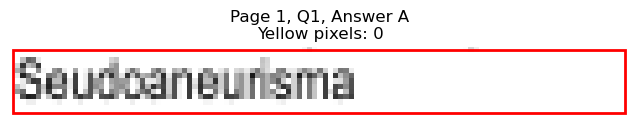

Page 1, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=257.8, y1=121.3
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 917
Page 1, Q1, B: Yellow percentage: 0.0%


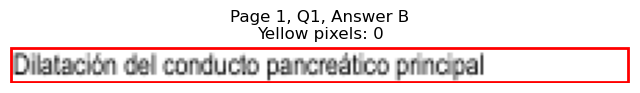

Page 1, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=139.6, y1=133.3
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 292
Page 1, Q1, C: Yellow percentage: 0.0%


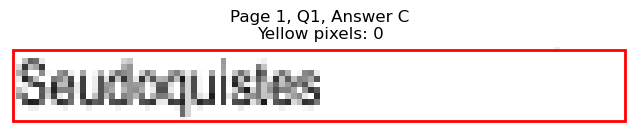

Page 1, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=472.7, y1=109.2
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 693
Page 1, Q1, D: Yellow percentage: 0.0%


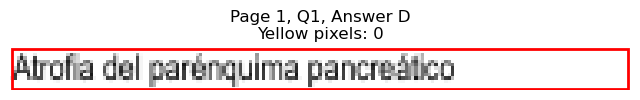

Page 1, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=498.9, y1=121.3
Page 1, Q1, E: Yellow pixels: 1590
Page 1, Q1, E: Total non-white pixels: 2470
Page 1, Q1, E: Yellow percentage: 64.4%


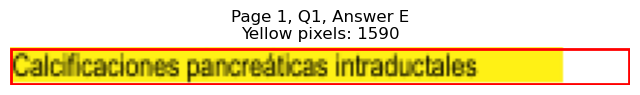


Page 1, Q1 - Selected Answer: E (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=187.0, y1=181.5
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 544
Page 1, Q2, A: Yellow percentage: 0.0%


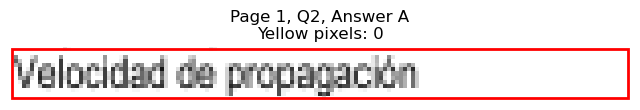

Page 1, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=139.1, y1=193.5
Page 1, Q2, B: Yellow pixels: 106
Page 1, Q2, B: Total non-white pixels: 391
Page 1, Q2, B: Yellow percentage: 27.1%


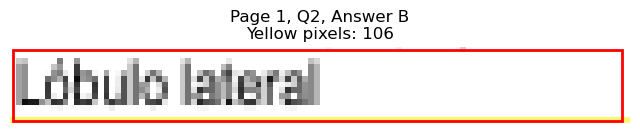

Page 1, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=113.7, y1=205.5
Page 1, Q2, C: Yellow pixels: 914
Page 1, Q2, C: Total non-white pixels: 1040
Page 1, Q2, C: Yellow percentage: 87.9%


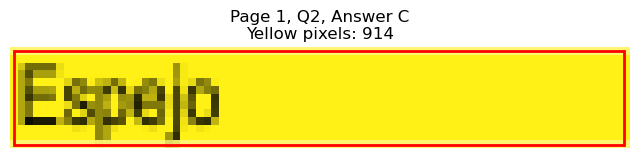

Page 1, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=399.0, y1=181.5
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 280
Page 1, Q2, D: Yellow percentage: 0.0%


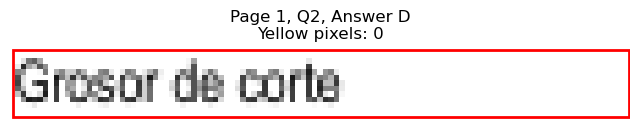

Page 1, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=395.1, y1=193.5
Page 1, Q2, E: Yellow pixels: 0
Page 1, Q2, E: Total non-white pixels: 313
Page 1, Q2, E: Yellow percentage: 0.0%


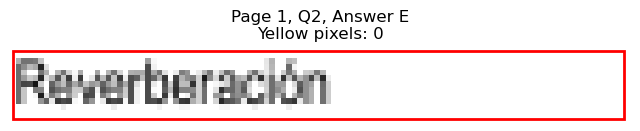


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=85.0, y0=229.7, x1=115.6, y1=241.8
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 140
Page 1, Q3, A: Yellow percentage: 0.0%


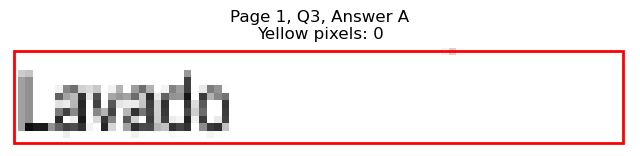

Page 1, Q3 - B: Detected box: x0=85.0, y0=241.7, x1=188.3, y1=253.8
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 478
Page 1, Q3, B: Yellow percentage: 0.0%


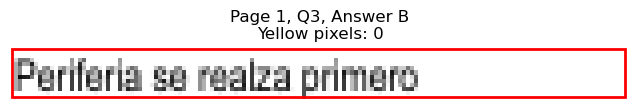

Page 1, Q3 - C: Detected box: x0=85.0, y0=253.7, x1=145.8, y1=265.8
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 312
Page 1, Q3, C: Yellow percentage: 0.0%


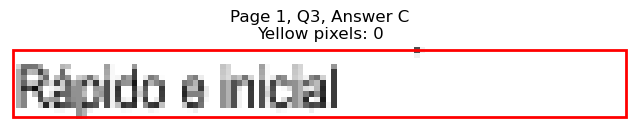

Page 1, Q3 - D: Detected box: x0=336.7, y0=229.7, x1=369.7, y1=241.8
Page 1, Q3, D: Yellow pixels: 873
Page 1, Q3, D: Total non-white pixels: 1092
Page 1, Q3, D: Yellow percentage: 79.9%


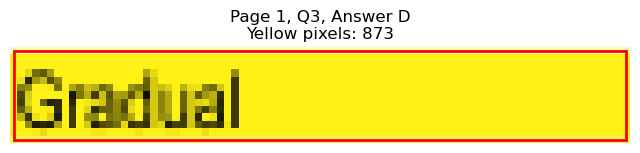

Page 1, Q3 - E: Detected box: x0=336.7, y0=241.7, x1=391.8, y1=253.8
Page 1, Q3, E: Yellow pixels: 106
Page 1, Q3, E: Total non-white pixels: 389
Page 1, Q3, E: Yellow percentage: 27.2%


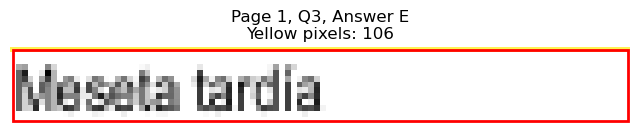


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=151.1, y1=314.0
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 339
Page 1, Q4, A: Yellow percentage: 0.0%


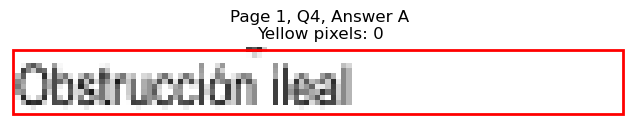

Page 1, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=162.6, y1=326.0
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 388
Page 1, Q4, B: Yellow percentage: 0.0%


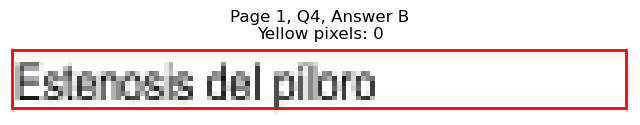

Page 1, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=168.3, y1=338.2
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 455
Page 1, Q4, C: Yellow percentage: 0.0%


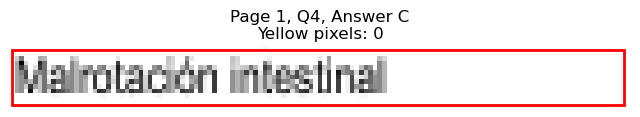

Page 1, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=420.0, y1=314.0
Page 1, Q4, D: Yellow pixels: 134
Page 1, Q4, D: Total non-white pixels: 707
Page 1, Q4, D: Yellow percentage: 19.0%


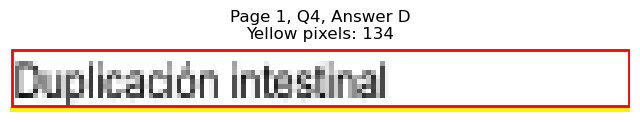

Page 1, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=403.8, y1=326.0
Page 1, Q4, E: Yellow pixels: 1148
Page 1, Q4, E: Total non-white pixels: 1652
Page 1, Q4, E: Yellow percentage: 69.5%


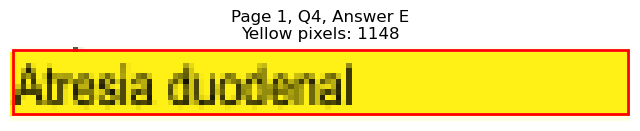


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=136.7, y1=374.3
Page 1, Q5, A: Yellow pixels: 103
Page 1, Q5, A: Total non-white pixels: 371
Page 1, Q5, A: Yellow percentage: 27.8%


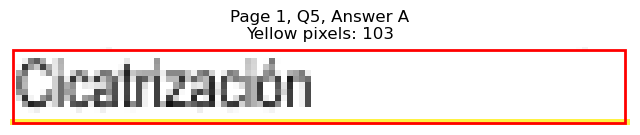

Page 1, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=122.8, y1=386.3
Page 1, Q5, B: Yellow pixels: 922
Page 1, Q5, B: Total non-white pixels: 1157
Page 1, Q5, B: Yellow percentage: 79.7%


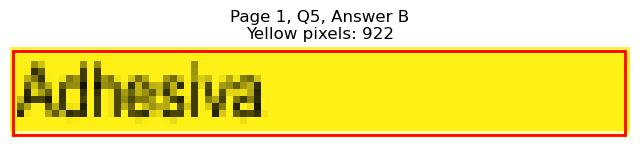

Page 1, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=133.8, y1=398.4
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 355
Page 1, Q5, C: Yellow percentage: 0.0%


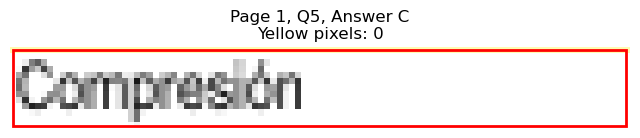

Page 1, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=387.4, y1=374.3
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 259
Page 1, Q5, D: Yellow percentage: 0.0%


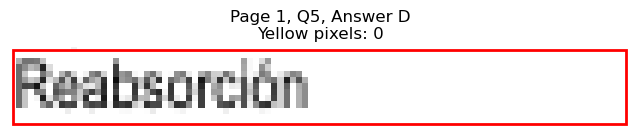

Page 1, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=364.9, y1=386.3
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 133
Page 1, Q5, E: Yellow percentage: 0.0%


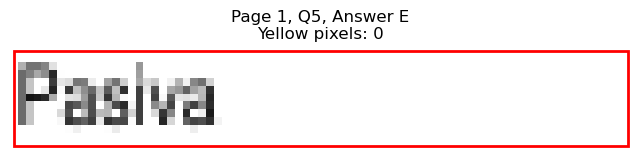


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=142.5, y1=446.5
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 294
Page 1, Q6, A: Yellow percentage: 0.0%


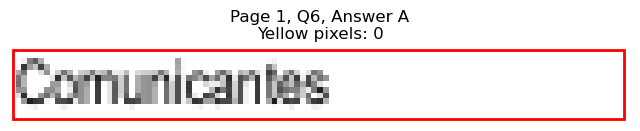

Page 1, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=129.5, y1=458.7
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 219
Page 1, Q6, B: Yellow percentage: 0.0%


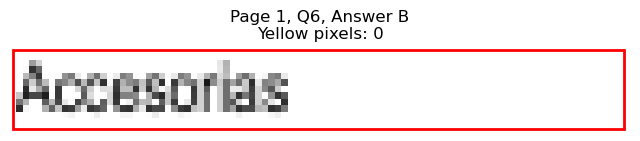

Page 1, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=136.7, y1=470.7
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 271
Page 1, Q6, C: Yellow percentage: 0.0%


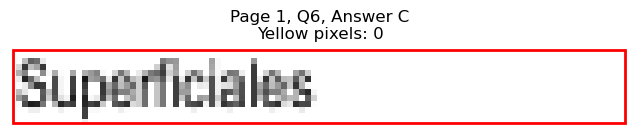

Page 1, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=383.6, y1=446.5
Page 1, Q6, D: Yellow pixels: 1064
Page 1, Q6, D: Total non-white pixels: 1274
Page 1, Q6, D: Yellow percentage: 83.5%


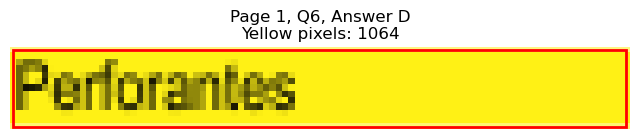

Page 1, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=378.3, y1=458.7
Page 1, Q6, E: Yellow pixels: 93
Page 1, Q6, E: Total non-white pixels: 303
Page 1, Q6, E: Yellow percentage: 30.7%


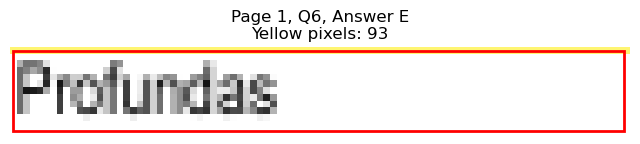


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=121.8, y1=506.8
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 191
Page 1, Q7, A: Yellow percentage: 0.0%


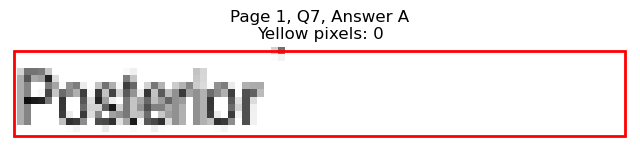

Page 1, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=146.8, y1=518.9
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 459
Page 1, Q7, B: Yellow percentage: 0.0%


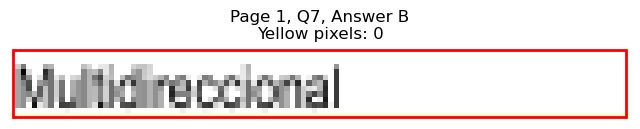

Page 1, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=117.5, y1=530.9
Page 1, Q7, C: Yellow pixels: 883
Page 1, Q7, C: Total non-white pixels: 1092
Page 1, Q7, C: Yellow percentage: 80.9%


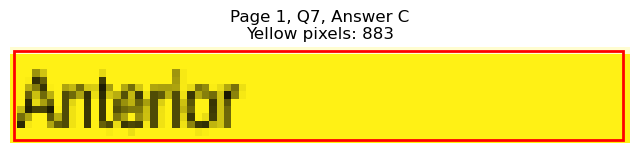

Page 1, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=371.6, y1=506.8
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 175
Page 1, Q7, D: Yellow percentage: 0.0%


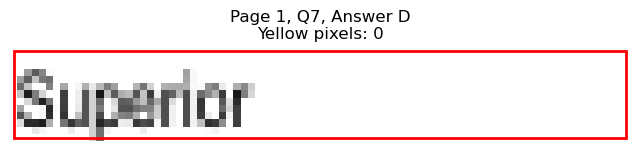

Page 1, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=365.4, y1=518.9
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 144
Page 1, Q7, E: Yellow percentage: 0.0%


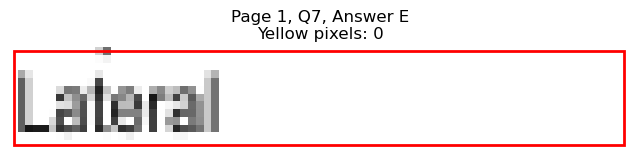


Page 1, Q7 - Selected Answer: C (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=199.4, y1=567.0
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 614
Page 1, Q8, A: Yellow percentage: 0.0%


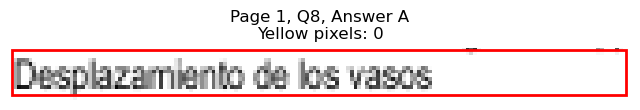

Page 1, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=209.5, y1=579.2
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 611
Page 1, Q8, B: Yellow percentage: 0.0%


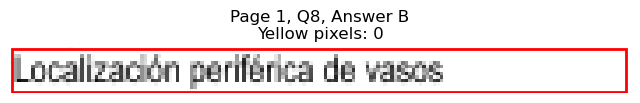

Page 1, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=176.9, y1=591.2
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 438
Page 1, Q8, C: Yellow percentage: 0.0%


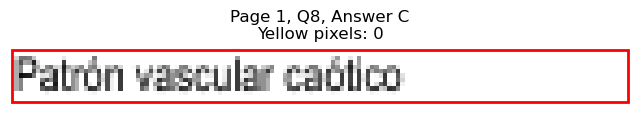

Page 1, Q8 - D: Detected box: x0=336.7, y0=554.9, x1=430.0, y1=567.0
Page 1, Q8, D: Yellow pixels: 1379
Page 1, Q8, D: Total non-white pixels: 2030
Page 1, Q8, D: Yellow percentage: 67.9%


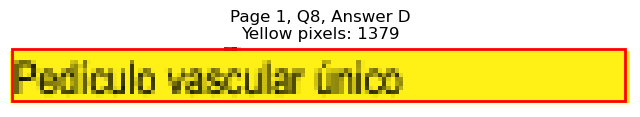

Page 1, Q8 - E: Detected box: x0=336.7, y0=567.1, x1=433.9, y1=579.2
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 626
Page 1, Q8, E: Yellow percentage: 0.0%


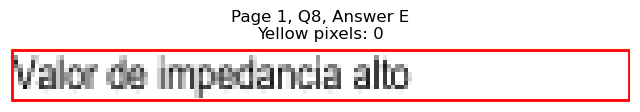


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=85.0, y0=627.3, x1=148.7, y1=639.4
Page 1, Q9, A: Yellow pixels: 115
Page 1, Q9, A: Total non-white pixels: 455
Page 1, Q9, A: Yellow percentage: 25.3%


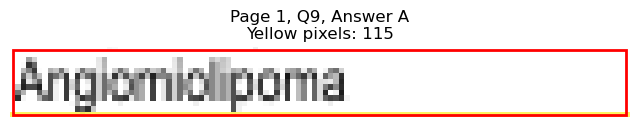

Page 1, Q9 - B: Detected box: x0=85.0, y0=639.3, x1=133.3, y1=651.4
Page 1, Q9, B: Yellow pixels: 1107
Page 1, Q9, B: Total non-white pixels: 1300
Page 1, Q9, B: Yellow percentage: 85.2%


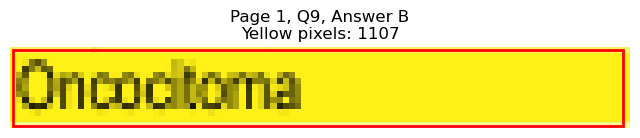

Page 1, Q9 - C: Detected box: x0=85.0, y0=651.4, x1=118.0, y1=663.5
Page 1, Q9, C: Yellow pixels: 84
Page 1, Q9, C: Total non-white pixels: 246
Page 1, Q9, C: Yellow percentage: 34.1%


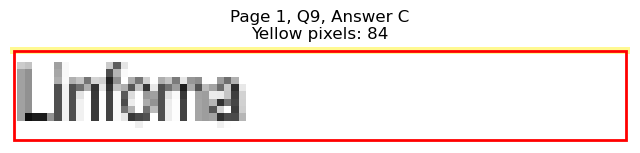

Page 1, Q9 - D: Detected box: x0=336.7, y0=627.3, x1=373.5, y1=639.4
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 178
Page 1, Q9, D: Yellow percentage: 0.0%


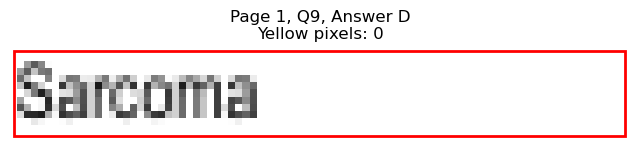

Page 1, Q9 - E: Detected box: x0=336.7, y0=639.3, x1=381.2, y1=651.4
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 226
Page 1, Q9, E: Yellow percentage: 0.0%


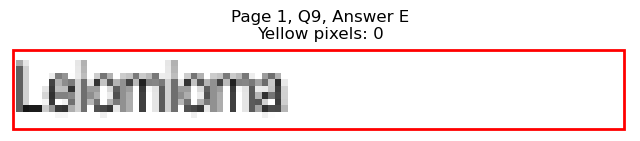


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=85.0, y0=687.5, x1=135.3, y1=699.7
Page 1, Q10, A: Yellow pixels: 0
Page 1, Q10, A: Total non-white pixels: 264
Page 1, Q10, A: Yellow percentage: 0.0%


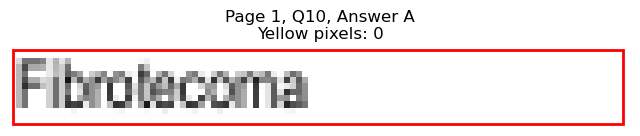

Page 1, Q10 - B: Detected box: x0=85.0, y0=699.5, x1=159.6, y1=711.7
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 394
Page 1, Q10, B: Yellow percentage: 0.0%


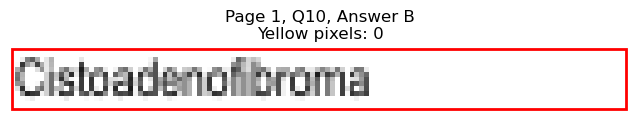

Page 1, Q10 - C: Detected box: x0=85.0, y0=711.7, x1=142.9, y1=723.8
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 296
Page 1, Q10, C: Yellow percentage: 0.0%


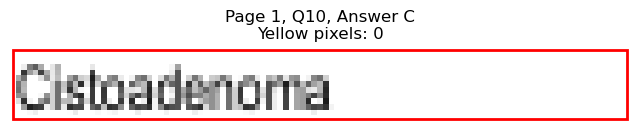

Page 1, Q10 - D: Detected box: x0=336.7, y0=687.5, x1=375.9, y1=699.7
Page 1, Q10, D: Yellow pixels: 1027
Page 1, Q10, D: Total non-white pixels: 1170
Page 1, Q10, D: Yellow percentage: 87.8%


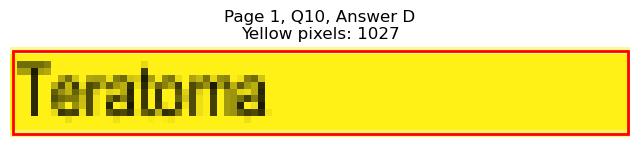

Page 1, Q10 - E: Detected box: x0=336.7, y0=699.5, x1=408.9, y1=711.7
Page 1, Q10, E: Yellow pixels: 123
Page 1, Q10, E: Total non-white pixels: 460
Page 1, Q10, E: Yellow percentage: 26.7%


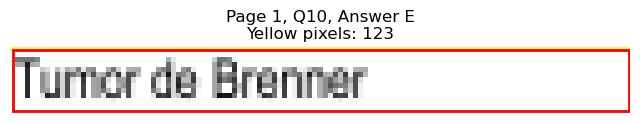


Page 1, Q10 - Selected Answer: D (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=85.0, y0=747.8, x1=199.9, y1=759.9
Page 1, Q11, A: Yellow pixels: 1494
Page 1, Q11, A: Total non-white pixels: 2158
Page 1, Q11, A: Yellow percentage: 69.2%


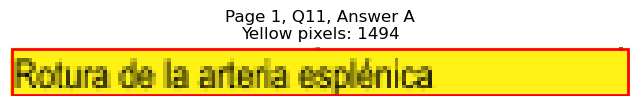

Page 1, Q11 - B: Detected box: x0=85.0, y0=759.8, x1=151.5, y1=771.9
Page 1, Q11, B: Yellow pixels: 116
Page 1, Q11, B: Total non-white pixels: 479
Page 1, Q11, B: Yellow percentage: 24.2%


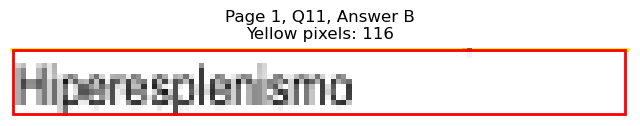

Page 1, Q11 - C: Detected box: x0=85.0, y0=771.9, x1=164.4, y1=784.0
Page 1, Q11, C: Yellow pixels: 0
Page 1, Q11, C: Total non-white pixels: 402
Page 1, Q11, C: Yellow percentage: 0.0%


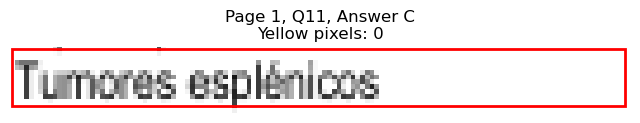

Page 1, Q11 - D: Detected box: x0=336.7, y0=747.8, x1=378.8, y1=759.9
Page 1, Q11, D: Yellow pixels: 0
Page 1, Q11, D: Total non-white pixels: 210
Page 1, Q11, D: Yellow percentage: 0.0%


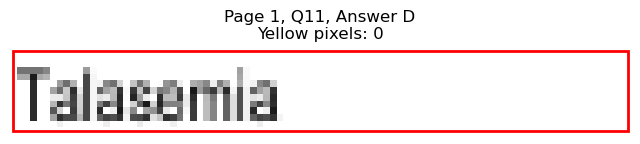

Page 1, Q11 - E: Detected box: x0=336.7, y0=759.8, x1=474.1, y1=771.9
Page 1, Q11, E: Yellow pixels: 0
Page 1, Q11, E: Total non-white pixels: 741
Page 1, Q11, E: Yellow percentage: 0.0%


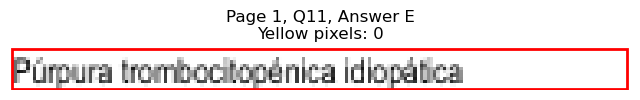


Page 1, Q11 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 11 questions
Page 2, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=131.4, y1=109.2
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 250
Page 2, Q1, A: Yellow percentage: 0.0%


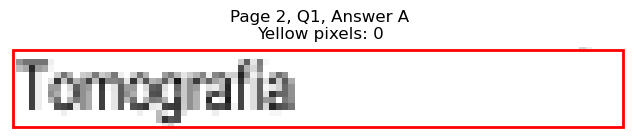

Page 2, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=133.3, y1=121.3
Page 2, Q1, B: Yellow pixels: 100
Page 2, Q1, B: Total non-white pixels: 371
Page 2, Q1, B: Yellow percentage: 27.0%


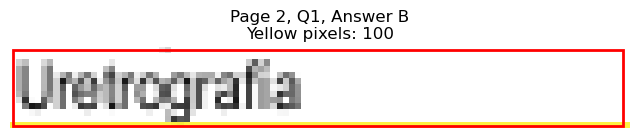

Page 2, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=132.9, y1=133.3
Page 2, Q1, C: Yellow pixels: 977
Page 2, Q1, C: Total non-white pixels: 1287
Page 2, Q1, C: Yellow percentage: 75.9%


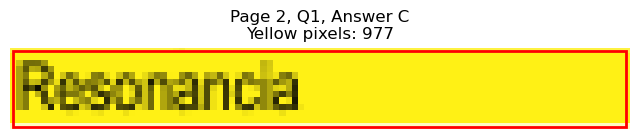

Page 2, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=391.8, y1=109.2
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 285
Page 2, Q1, D: Yellow percentage: 0.0%


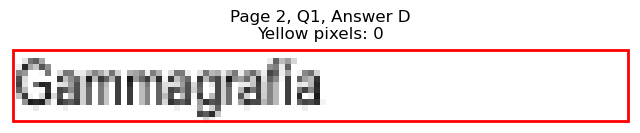

Page 2, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=375.9, y1=121.3
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 214
Page 2, Q1, E: Yellow percentage: 0.0%


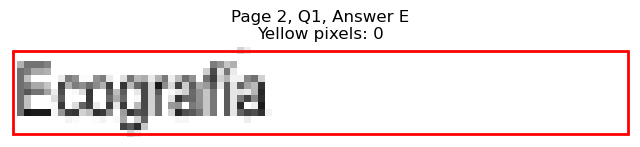


Page 2, Q1 - Selected Answer: C (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=166.3, y1=169.4
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 445
Page 2, Q2, A: Yellow percentage: 0.0%


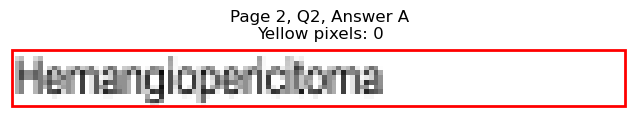

Page 2, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=134.3, y1=181.5
Page 2, Q2, B: Yellow pixels: 1086
Page 2, Q2, B: Total non-white pixels: 1313
Page 2, Q2, B: Yellow percentage: 82.7%


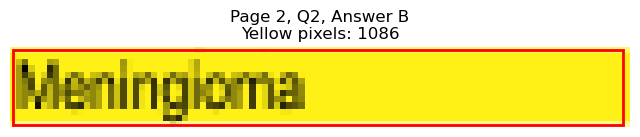

Page 2, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=132.4, y1=193.5
Page 2, Q2, C: Yellow pixels: 99
Page 2, Q2, C: Total non-white pixels: 324
Page 2, Q2, C: Yellow percentage: 30.6%


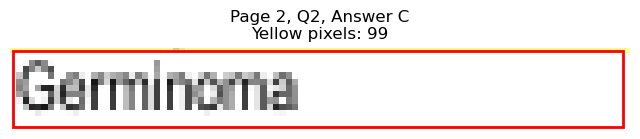

Page 2, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=375.9, y1=169.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 178
Page 2, Q2, D: Yellow percentage: 0.0%


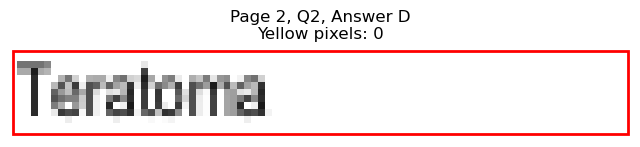

Page 2, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=374.5, y1=181.5
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 182
Page 2, Q2, E: Yellow percentage: 0.0%


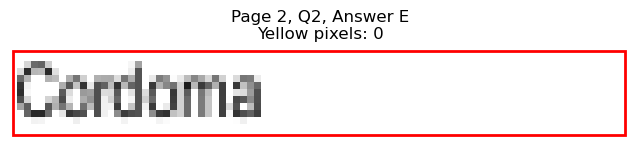


Page 2, Q2 - Selected Answer: B (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=294.2, y1=229.7
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 1027
Page 2, Q3, A: Yellow percentage: 0.0%


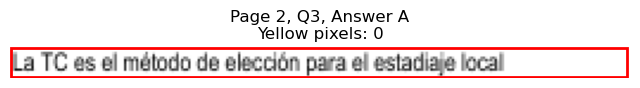

Page 2, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=375.1, y1=241.8
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 1424
Page 2, Q3, B: Yellow percentage: 0.0%


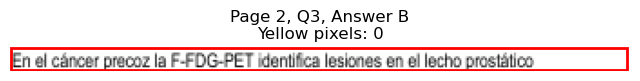

Page 2, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=270.3, y1=253.8
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 941
Page 2, Q3, C: Yellow percentage: 0.0%


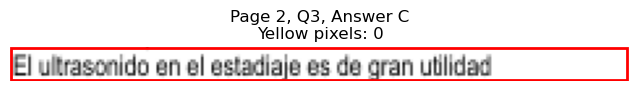

Page 2, Q3 - D: Detected box: x0=85.0, y0=253.7, x1=299.0, y1=265.8
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 1065
Page 2, Q3, D: Yellow percentage: 0.0%


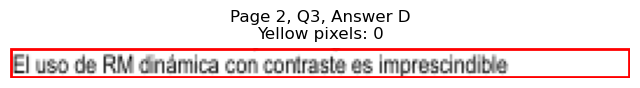

Page 2, Q3 - E: Detected box: x0=85.0, y0=265.8, x1=391.9, y1=277.9
Page 2, Q3, E: Yellow pixels: 3097
Page 2, Q3, E: Total non-white pixels: 4654
Page 2, Q3, E: Yellow percentage: 66.5%


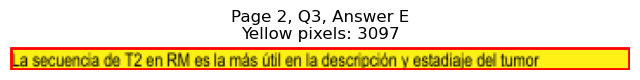


Page 2, Q3 - Selected Answer: E (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=104.2, y1=314.0
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 103
Page 2, Q4, A: Yellow percentage: 0.0%


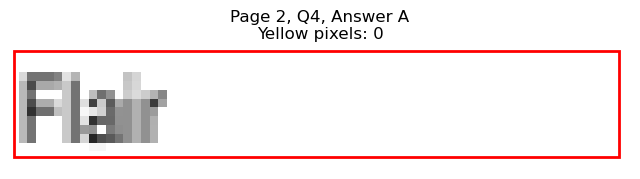

Page 2, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=97.5, y1=326.0
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 50
Page 2, Q4, B: Yellow percentage: 0.0%


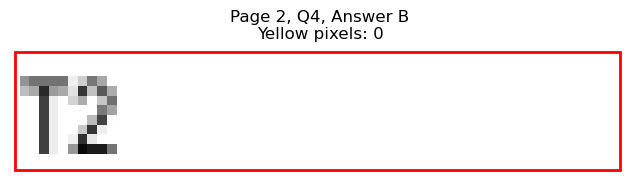

Page 2, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=106.9, y1=338.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 100
Page 2, Q4, C: Yellow percentage: 0.0%


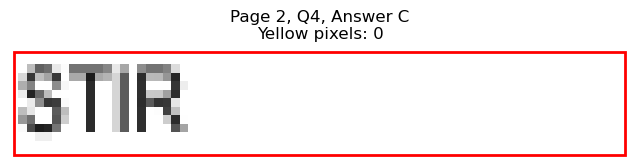

Page 2, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=392.7, y1=314.0
Page 2, Q4, D: Yellow pixels: 1055
Page 2, Q4, D: Total non-white pixels: 1393
Page 2, Q4, D: Yellow percentage: 75.7%


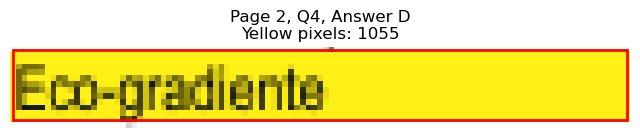

Page 2, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=351.1, y1=326.0
Page 2, Q4, E: Yellow pixels: 62
Page 2, Q4, E: Total non-white pixels: 135
Page 2, Q4, E: Yellow percentage: 45.9%


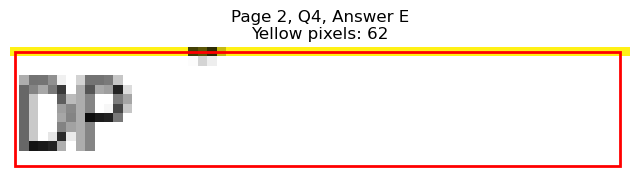


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=185.5, y1=374.3
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 516
Page 2, Q5, A: Yellow percentage: 0.0%


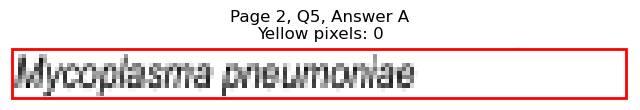

Page 2, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=183.1, y1=386.3
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 512
Page 2, Q5, B: Yellow percentage: 0.0%


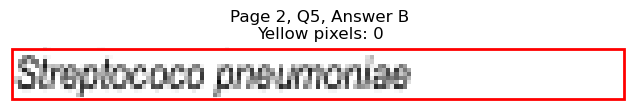

Page 2, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=169.7, y1=398.4
Page 2, Q5, C: Yellow pixels: 1294
Page 2, Q5, C: Total non-white pixels: 1768
Page 2, Q5, C: Yellow percentage: 73.2%


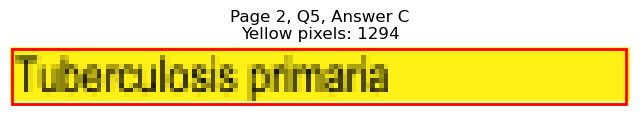

Page 2, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=434.8, y1=374.3
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 508
Page 2, Q5, D: Yellow percentage: 0.0%


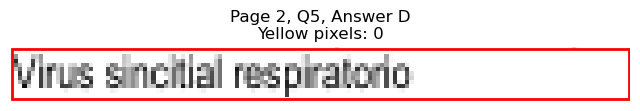

Page 2, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=455.4, y1=386.3
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 569
Page 2, Q5, E: Yellow percentage: 0.0%


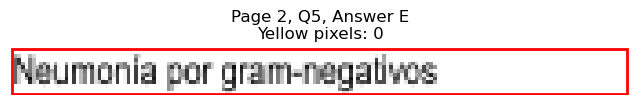


Page 2, Q5 - Selected Answer: C (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=85.0, y0=422.4, x1=255.4, y1=434.5
Page 2, Q6, A: Yellow pixels: 1822
Page 2, Q6, A: Total non-white pixels: 2483
Page 2, Q6, A: Yellow percentage: 73.4%


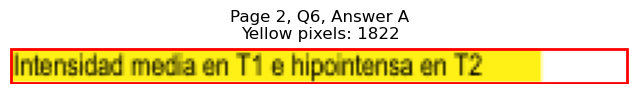

Page 2, Q6 - B: Detected box: x0=85.0, y0=434.4, x1=275.2, y1=446.5
Page 2, Q6, B: Yellow pixels: 190
Page 2, Q6, B: Total non-white pixels: 1163
Page 2, Q6, B: Yellow percentage: 16.3%


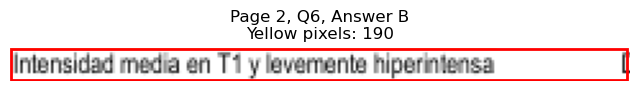

Page 2, Q6 - C: Detected box: x0=336.7, y0=422.4, x1=431.0, y1=434.5
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 427
Page 2, Q6, C: Yellow percentage: 0.0%


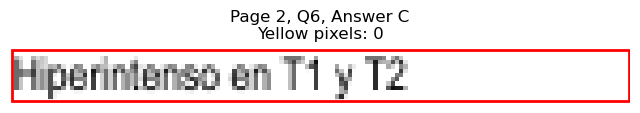

Page 2, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=428.1, y1=446.5
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 389
Page 2, Q6, D: Yellow percentage: 0.0%


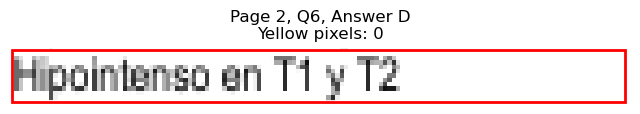

Page 2, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=489.8, y1=458.7
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 739
Page 2, Q6, E: Yellow percentage: 0.0%


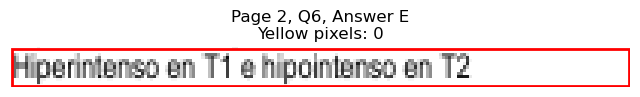


Page 2, Q6 - Selected Answer: A (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=85.0, y0=482.7, x1=136.7, y1=494.8
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 267
Page 2, Q7, A: Yellow percentage: 0.0%


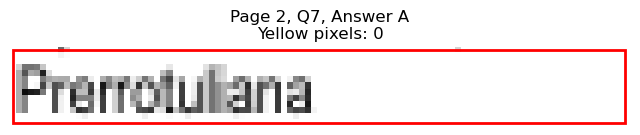

Page 2, Q7 - B: Detected box: x0=85.0, y0=494.7, x1=142.9, y1=506.8
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 286
Page 2, Q7, B: Yellow percentage: 0.0%


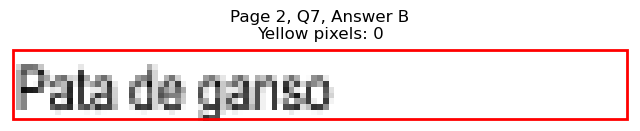

Page 2, Q7 - C: Detected box: x0=85.0, y0=506.8, x1=232.5, y1=518.9
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 779
Page 2, Q7, C: Yellow percentage: 0.0%


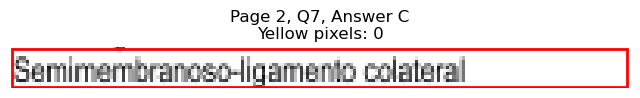

Page 2, Q7 - D: Detected box: x0=336.7, y0=482.7, x1=463.5, y1=494.8
Page 2, Q7, D: Yellow pixels: 1611
Page 2, Q7, D: Total non-white pixels: 2314
Page 2, Q7, D: Yellow percentage: 69.6%


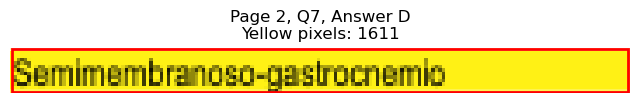

Page 2, Q7 - E: Detected box: x0=336.7, y0=494.7, x1=392.2, y1=506.8
Page 2, Q7, E: Yellow pixels: 103
Page 2, Q7, E: Total non-white pixels: 412
Page 2, Q7, E: Yellow percentage: 25.0%


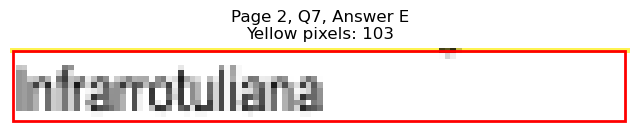


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=85.0, y0=542.9, x1=193.3, y1=555.0
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 561
Page 2, Q8, A: Yellow percentage: 0.0%


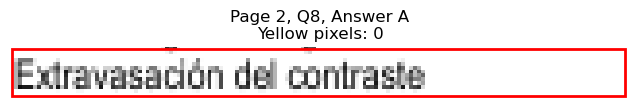

Page 2, Q8 - B: Detected box: x0=85.0, y0=554.9, x1=152.5, y1=567.0
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 350
Page 2, Q8, B: Yellow percentage: 0.0%


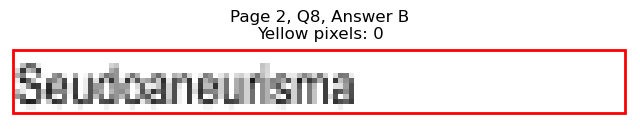

Page 2, Q8 - C: Detected box: x0=85.0, y0=567.1, x1=152.1, y1=579.2
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 360
Page 2, Q8, C: Yellow percentage: 0.0%


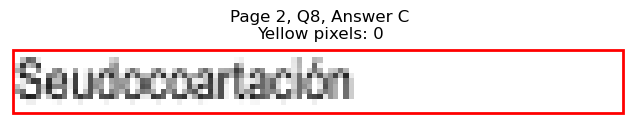

Page 2, Q8 - D: Detected box: x0=336.7, y0=542.9, x1=393.2, y1=555.0
Page 2, Q8, D: Yellow pixels: 108
Page 2, Q8, D: Total non-white pixels: 507
Page 2, Q8, D: Yellow percentage: 21.3%


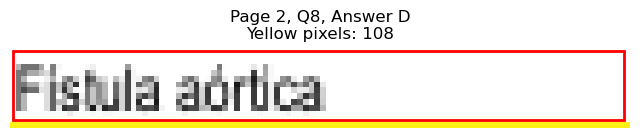

Page 2, Q8 - E: Detected box: x0=336.7, y0=554.9, x1=423.8, y1=567.0
Page 2, Q8, E: Yellow pixels: 1281
Page 2, Q8, E: Total non-white pixels: 1932
Page 2, Q8, E: Yellow percentage: 66.3%


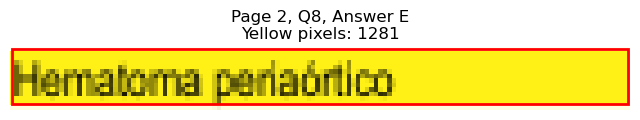


Page 2, Q8 - Selected Answer: E (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=85.0, y0=603.2, x1=128.5, y1=615.3
Page 2, Q9, A: Yellow pixels: 95
Page 2, Q9, A: Total non-white pixels: 339
Page 2, Q9, A: Yellow percentage: 28.0%


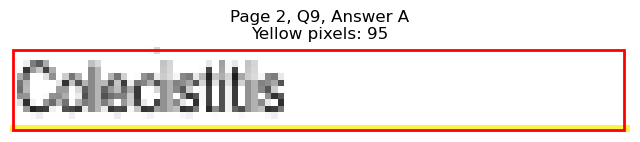

Page 2, Q9 - B: Detected box: x0=85.0, y0=615.2, x1=125.2, y1=627.3
Page 2, Q9, B: Yellow pixels: 929
Page 2, Q9, B: Total non-white pixels: 1196
Page 2, Q9, B: Yellow percentage: 77.7%


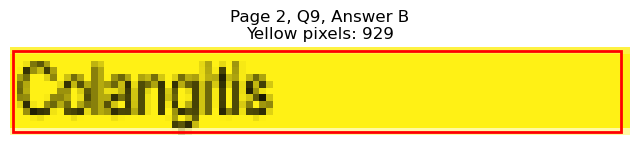

Page 2, Q9 - C: Detected box: x0=85.0, y0=627.3, x1=129.0, y1=639.4
Page 2, Q9, C: Yellow pixels: 1
Page 2, Q9, C: Total non-white pixels: 316
Page 2, Q9, C: Yellow percentage: 0.3%


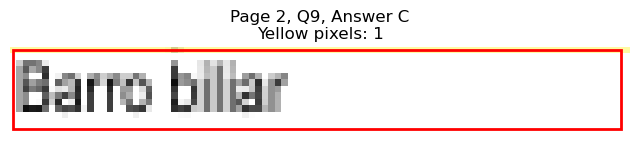

Page 2, Q9 - D: Detected box: x0=336.7, y0=603.2, x1=363.0, y1=615.3
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 145
Page 2, Q9, D: Yellow percentage: 0.0%


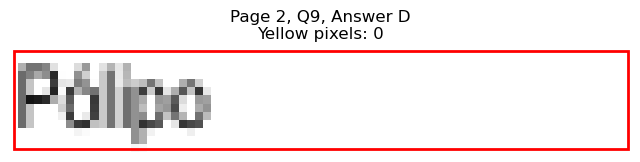

Page 2, Q9 - E: Detected box: x0=336.7, y0=615.2, x1=365.4, y1=627.3
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 148
Page 2, Q9, E: Yellow percentage: 0.0%


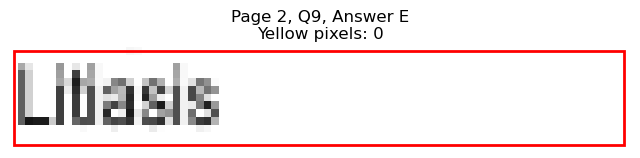


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=85.0, y0=663.4, x1=122.3, y1=675.5
Page 2, Q10, A: Yellow pixels: 0
Page 2, Q10, A: Total non-white pixels: 194
Page 2, Q10, A: Yellow percentage: 0.0%


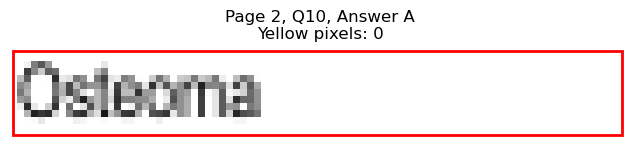

Page 2, Q10 - B: Detected box: x0=85.0, y0=675.4, x1=139.6, y1=687.5
Page 2, Q10, B: Yellow pixels: 0
Page 2, Q10, B: Total non-white pixels: 270
Page 2, Q10, B: Yellow percentage: 0.0%


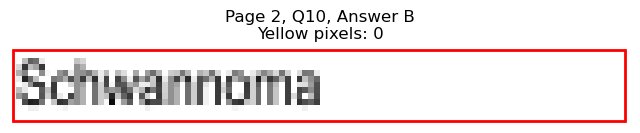

Page 2, Q10 - C: Detected box: x0=85.0, y0=687.5, x1=136.2, y1=699.7
Page 2, Q10, C: Yellow pixels: 1138
Page 2, Q10, C: Total non-white pixels: 1339
Page 2, Q10, C: Yellow percentage: 85.0%


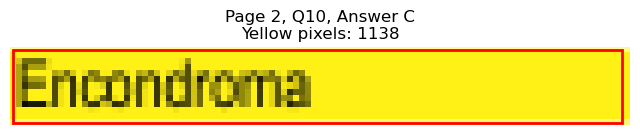

Page 2, Q10 - D: Detected box: x0=336.7, y0=663.4, x1=374.5, y1=675.5
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 182
Page 2, Q10, D: Yellow percentage: 0.0%


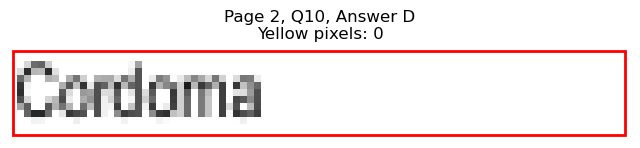

Page 2, Q10 - E: Detected box: x0=336.7, y0=675.4, x1=374.5, y1=687.5
Page 2, Q10, E: Yellow pixels: 0
Page 2, Q10, E: Total non-white pixels: 180
Page 2, Q10, E: Yellow percentage: 0.0%


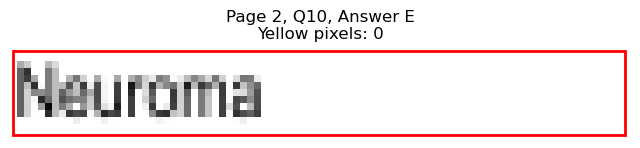


Page 2, Q10 - Selected Answer: C (based on yellow pixel count)




Page 2, Q11 - A: Detected box: x0=85.0, y0=723.7, x1=164.4, y1=735.8
Page 2, Q11, A: Yellow pixels: 1244
Page 2, Q11, A: Total non-white pixels: 1703
Page 2, Q11, A: Yellow percentage: 73.0%


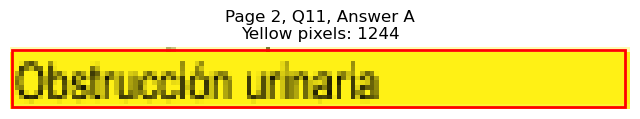

Page 2, Q11 - B: Detected box: x0=85.0, y0=735.8, x1=144.4, y1=747.9
Page 2, Q11, B: Yellow pixels: 111
Page 2, Q11, B: Total non-white pixels: 406
Page 2, Q11, B: Yellow percentage: 27.3%


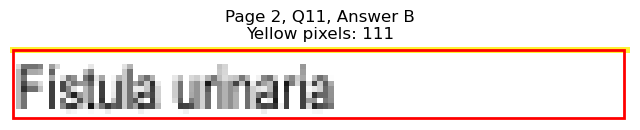

Page 2, Q11 - C: Detected box: x0=336.7, y0=723.7, x1=455.4, y1=735.8
Page 2, Q11, C: Yellow pixels: 0
Page 2, Q11, C: Total non-white pixels: 620
Page 2, Q11, C: Yellow percentage: 0.0%


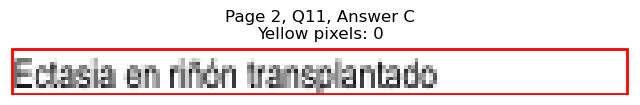

Page 2, Q11 - D: Detected box: x0=336.7, y0=735.8, x1=425.2, y1=747.9
Page 2, Q11, D: Yellow pixels: 0
Page 2, Q11, D: Total non-white pixels: 458
Page 2, Q11, D: Yellow percentage: 0.0%


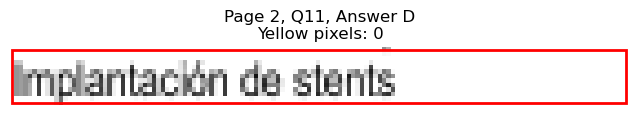

Page 2, Q11 - E: Detected box: x0=85.0, y0=747.8, x1=164.4, y1=759.9
Page 2, Q11, E: Yellow pixels: 0
Page 2, Q11, E: Total non-white pixels: 406
Page 2, Q11, E: Yellow percentage: 0.0%


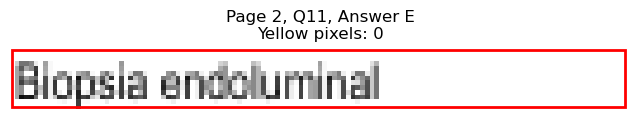


Page 2, Q11 - Selected Answer: A (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=119.4, y1=109.2
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 170
Page 3, Q1, A: Yellow percentage: 0.0%


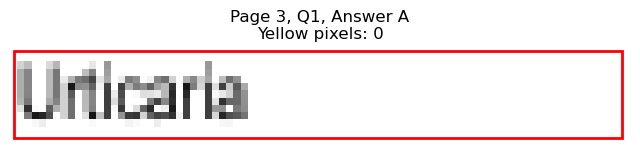

Page 3, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=149.2, y1=121.3
Page 3, Q1, B: Yellow pixels: 116
Page 3, Q1, B: Total non-white pixels: 421
Page 3, Q1, B: Yellow percentage: 27.6%


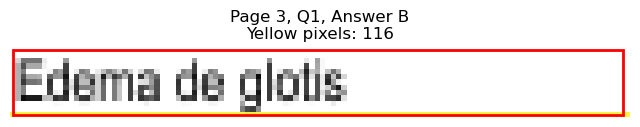

Page 3, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=130.9, y1=133.3
Page 3, Q1, C: Yellow pixels: 950
Page 3, Q1, C: Total non-white pixels: 1261
Page 3, Q1, C: Yellow percentage: 75.3%


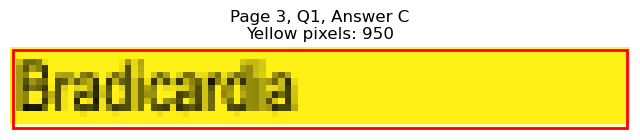

Page 3, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=404.6, y1=109.2
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 340
Page 3, Q1, D: Yellow percentage: 0.0%


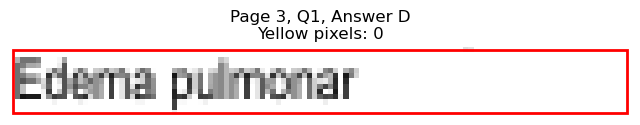

Page 3, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=401.4, y1=121.3
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 335
Page 3, Q1, E: Yellow percentage: 0.0%


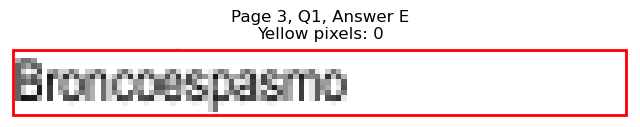


Page 3, Q1 - Selected Answer: C (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=157.2, y1=193.5
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 385
Page 3, Q2, A: Yellow percentage: 0.0%


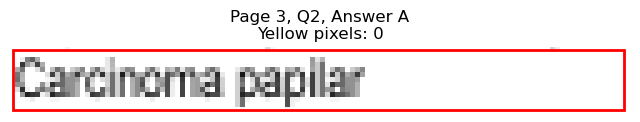

Page 3, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=123.3, y1=205.5
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 204
Page 3, Q2, B: Yellow percentage: 0.0%


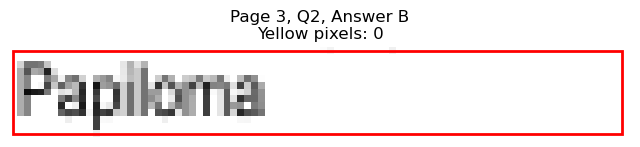

Page 3, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=149.2, y1=217.7
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 330
Page 3, Q2, C: Yellow percentage: 0.0%


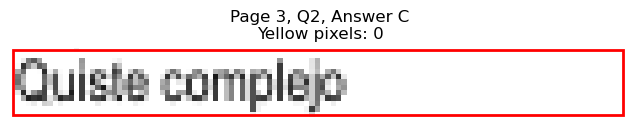

Page 3, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=414.2, y1=193.5
Page 3, Q2, D: Yellow pixels: 129
Page 3, Q2, D: Total non-white pixels: 505
Page 3, Q2, D: Yellow percentage: 25.5%


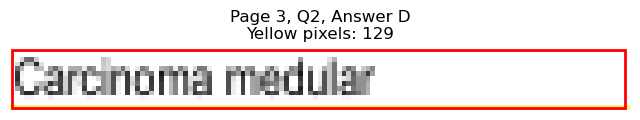

Page 3, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=396.6, y1=205.5
Page 3, Q2, E: Yellow pixels: 1190
Page 3, Q2, E: Total non-white pixels: 1443
Page 3, Q2, E: Yellow percentage: 82.5%


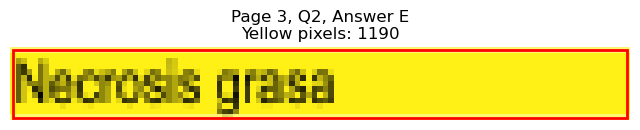


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=131.9, y1=253.8
Page 3, Q3, A: Yellow pixels: 1
Page 3, Q3, A: Total non-white pixels: 369
Page 3, Q3, A: Yellow percentage: 0.3%


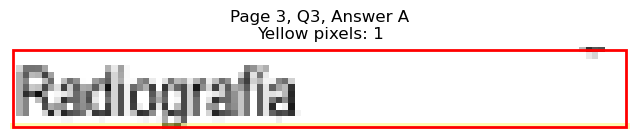

Page 3, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=131.4, y1=265.8
Page 3, Q3, B: Yellow pixels: 987
Page 3, Q3, B: Total non-white pixels: 1274
Page 3, Q3, B: Yellow percentage: 77.5%


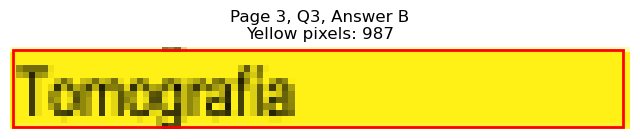

Page 3, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=132.9, y1=277.9
Page 3, Q3, C: Yellow pixels: 95
Page 3, Q3, C: Total non-white pixels: 351
Page 3, Q3, C: Yellow percentage: 27.1%


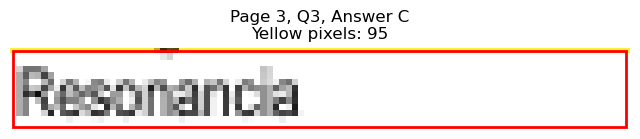

Page 3, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=370.3, y1=253.8
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 142
Page 3, Q3, D: Yellow percentage: 0.0%


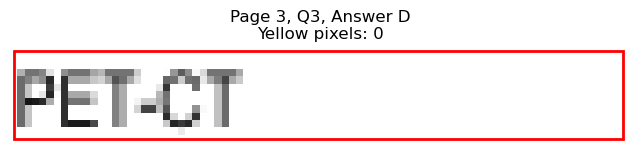

Page 3, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=434.5, y1=265.8
Page 3, Q3, E: Yellow pixels: 0
Page 3, Q3, E: Total non-white pixels: 538
Page 3, Q3, E: Yellow percentage: 0.0%


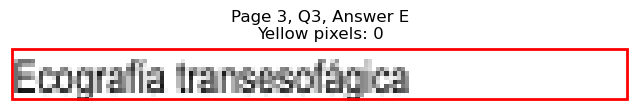


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=117.5, y1=314.0
Page 3, Q4, A: Yellow pixels: 84
Page 3, Q4, A: Total non-white pixels: 329
Page 3, Q4, A: Yellow percentage: 25.5%


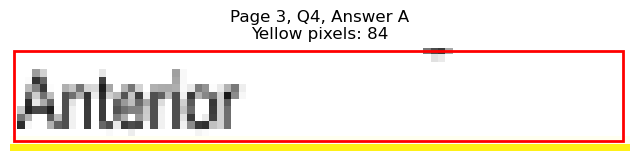

Page 3, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=110.8, y1=326.0
Page 3, Q4, B: Yellow pixels: 805
Page 3, Q4, B: Total non-white pixels: 1078
Page 3, Q4, B: Yellow percentage: 74.7%


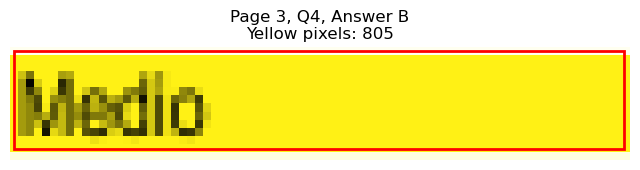

Page 3, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=121.8, y1=338.2
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 276
Page 3, Q4, C: Yellow percentage: 0.0%


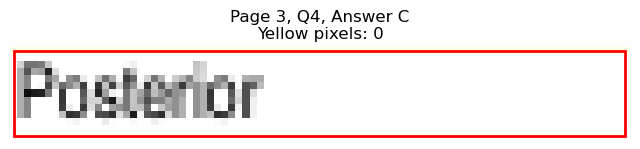

Page 3, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=371.6, y1=314.0
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 176
Page 3, Q4, D: Yellow percentage: 0.0%


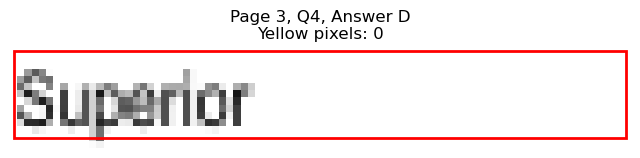

Page 3, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=365.4, y1=326.0
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 144
Page 3, Q4, E: Yellow percentage: 0.0%


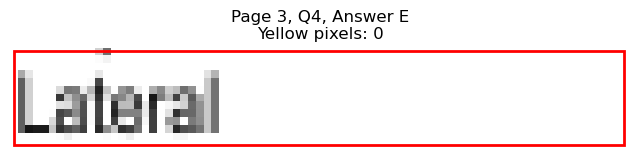


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=143.4, y1=386.3
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 292
Page 3, Q5, A: Yellow percentage: 0.0%


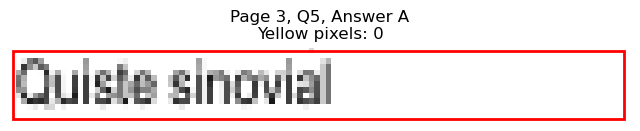

Page 3, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=115.6, y1=398.4
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 143
Page 3, Q5, B: Yellow percentage: 0.0%


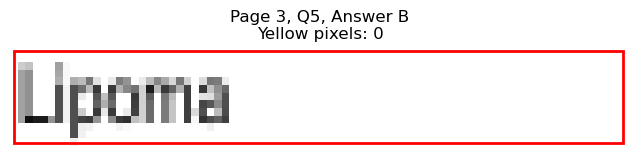

Page 3, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=122.8, y1=410.4
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 184
Page 3, Q5, C: Yellow percentage: 0.0%


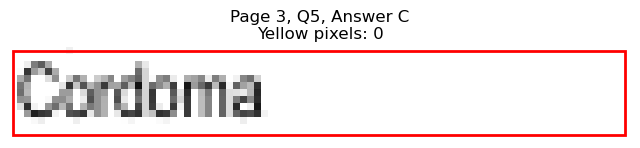

Page 3, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=390.3, y1=386.3
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 287
Page 3, Q5, D: Yellow percentage: 0.0%


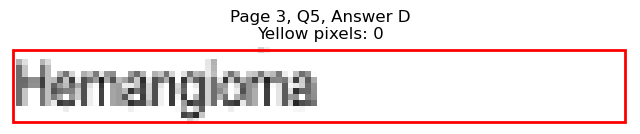

Page 3, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=415.6, y1=398.4
Page 3, Q5, E: Yellow pixels: 1262
Page 3, Q5, E: Total non-white pixels: 1690
Page 3, Q5, E: Yellow percentage: 74.7%


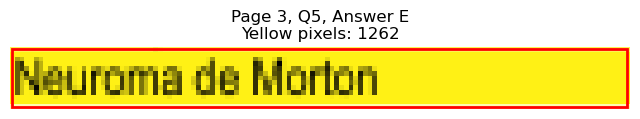


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=146.8, y1=446.5
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 329
Page 3, Q6, A: Yellow percentage: 0.0%


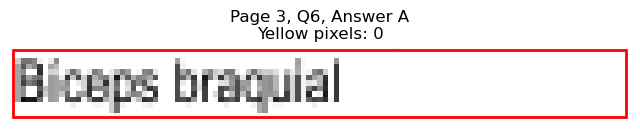

Page 3, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=121.3, y1=458.7
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 171
Page 3, Q6, B: Yellow percentage: 0.0%


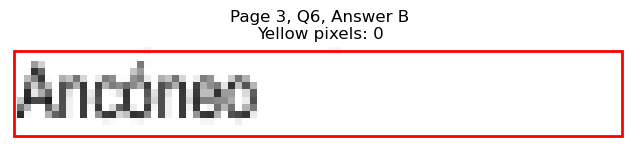

Page 3, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=126.6, y1=470.7
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 213
Page 3, Q6, C: Yellow percentage: 0.0%


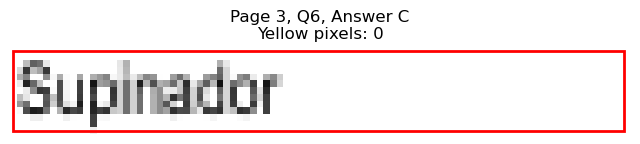

Page 3, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=408.4, y1=446.5
Page 3, Q6, D: Yellow pixels: 1305
Page 3, Q6, D: Total non-white pixels: 1599
Page 3, Q6, D: Yellow percentage: 81.6%


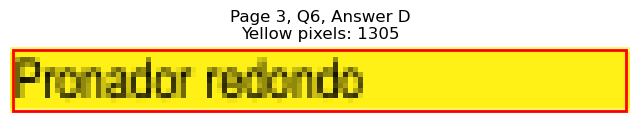

Page 3, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=387.9, y1=458.7
Page 3, Q6, E: Yellow pixels: 102
Page 3, Q6, E: Total non-white pixels: 391
Page 3, Q6, E: Yellow percentage: 26.1%


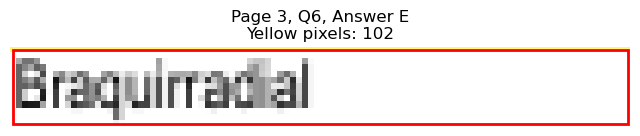


Page 3, Q6 - Selected Answer: D (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=122.9, y1=506.8
Page 3, Q7, A: Yellow pixels: 769
Page 3, Q7, A: Total non-white pixels: 1157
Page 3, Q7, A: Yellow percentage: 66.5%


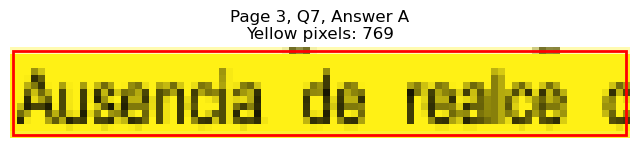

Page 3, Q7 - B: Detected box: x0=85.0, y0=518.8, x1=207.5, y1=530.9
Page 3, Q7, B: Yellow pixels: 174
Page 3, Q7, B: Total non-white pixels: 839
Page 3, Q7, B: Yellow percentage: 20.7%


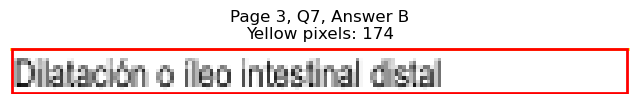

Page 3, Q7 - C: Detected box: x0=336.7, y0=494.7, x1=509.0, y1=506.8
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 887
Page 3, Q7, C: Yellow percentage: 0.0%


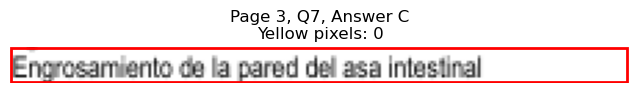

Page 3, Q7 - D: Detected box: x0=336.7, y0=506.8, x1=402.8, y1=518.9
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 353
Page 3, Q7, D: Yellow percentage: 0.0%


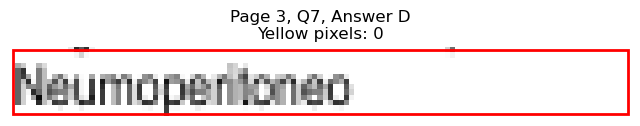

Page 3, Q7 - E: Detected box: x0=336.7, y0=518.8, x1=441.1, y1=530.9
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 514
Page 3, Q7, E: Yellow percentage: 0.0%


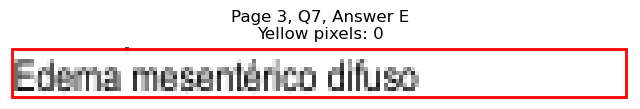


Page 3, Q7 - Selected Answer: A (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=518.6, y1=567.0
Page 3, Q8, A: Yellow pixels: 3598
Page 3, Q8, A: Total non-white pixels: 6188
Page 3, Q8, A: Yellow percentage: 58.1%


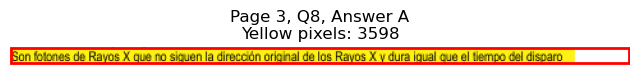

Page 3, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=356.8, y1=579.2
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 1628
Page 3, Q8, B: Yellow percentage: 0.0%


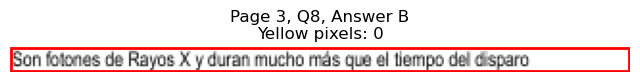

Page 3, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=526.8, y1=591.2
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 2231
Page 3, Q8, C: Yellow percentage: 0.0%


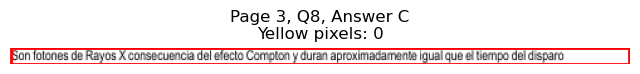

Page 3, Q8 - D: Detected box: x0=85.0, y0=591.2, x1=338.2, y1=603.3
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 1202
Page 3, Q8, D: Yellow percentage: 0.0%


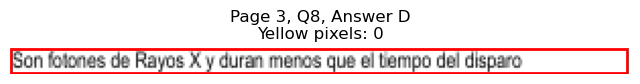

Page 3, Q8 - E: Detected box: x0=85.0, y0=603.2, x1=503.0, y1=615.3
Page 3, Q8, E: Yellow pixels: 0
Page 3, Q8, E: Total non-white pixels: 2071
Page 3, Q8, E: Yellow percentage: 0.0%


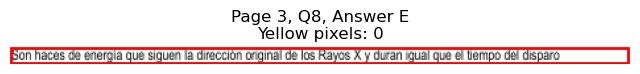


Page 3, Q8 - Selected Answer: A (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=70.8, y0=651.4, x1=79.0, y1=663.5
Page 3, Q9, A: Yellow pixels: 723
Page 3, Q9, A: Total non-white pixels: 767
Page 3, Q9, A: Yellow percentage: 94.3%


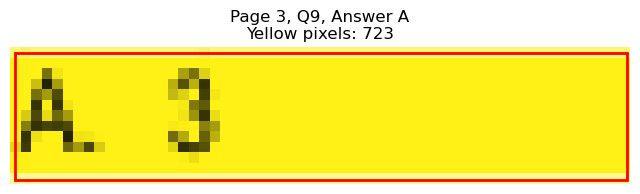

Page 3, Q9 - B: Detected box: x0=70.8, y0=663.4, x1=79.0, y1=675.5
Page 3, Q9, B: Yellow pixels: 59
Page 3, Q9, B: Total non-white pixels: 128
Page 3, Q9, B: Yellow percentage: 46.1%


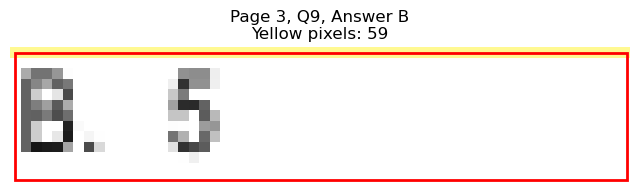

Page 3, Q9 - C: Detected box: x0=70.8, y0=675.4, x1=79.5, y1=687.5
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 57
Page 3, Q9, C: Yellow percentage: 0.0%


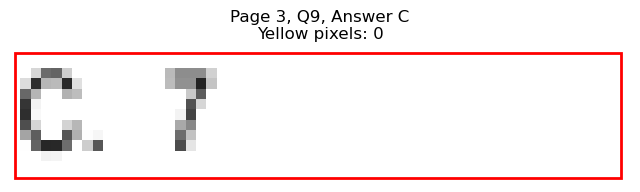

Page 3, Q9 - D: Detected box: x0=322.5, y0=651.4, x1=331.2, y1=663.5
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 65
Page 3, Q9, D: Yellow percentage: 0.0%


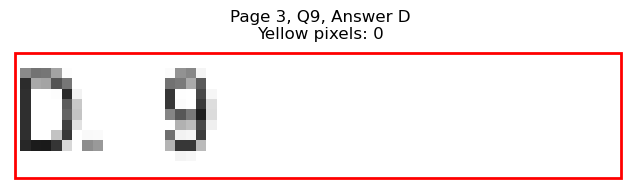

Page 3, Q9 - E: Detected box: x0=336.7, y0=663.4, x1=348.7, y1=675.5
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 29
Page 3, Q9, E: Yellow percentage: 0.0%


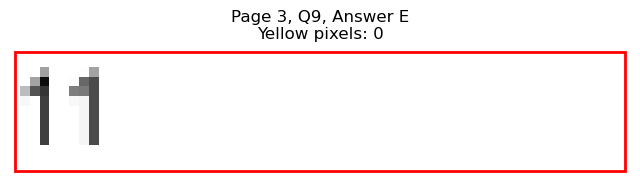


Page 3, Q9 - Selected Answer: A (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=85.0, y0=711.7, x1=362.6, y1=723.8
Page 3, Q10, A: Yellow pixels: 2805
Page 3, Q10, A: Total non-white pixels: 4277
Page 3, Q10, A: Yellow percentage: 65.6%


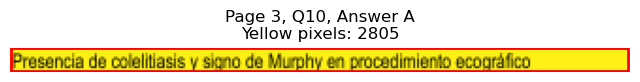

Page 3, Q10 - B: Detected box: x0=85.0, y0=723.7, x1=288.9, y1=735.8
Page 3, Q10, B: Yellow pixels: 241
Page 3, Q10, B: Total non-white pixels: 1295
Page 3, Q10, B: Yellow percentage: 18.6%


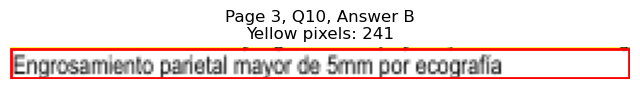

Page 3, Q10 - C: Detected box: x0=85.0, y0=735.8, x1=372.7, y1=747.9
Page 3, Q10, C: Yellow pixels: 0
Page 3, Q10, C: Total non-white pixels: 1449
Page 3, Q10, C: Yellow percentage: 0.0%


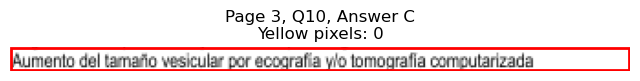

Page 3, Q10 - D: Detected box: x0=85.0, y0=747.8, x1=350.2, y1=759.9
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 1306
Page 3, Q10, D: Yellow percentage: 0.0%


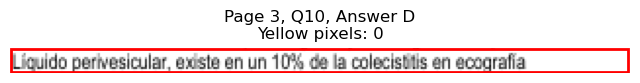

Page 3, Q10 - E: Detected box: x0=85.0, y0=759.8, x1=361.7, y1=771.9
Page 3, Q10, E: Yellow pixels: 0
Page 3, Q10, E: Total non-white pixels: 1412
Page 3, Q10, E: Yellow percentage: 0.0%


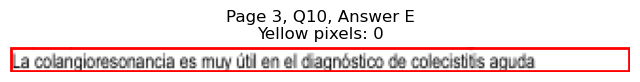


Page 3, Q10 - Selected Answer: A (based on yellow pixel count)





Page 4: Found 10 questions
Page 4, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=135.9, y1=109.2
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 270
Page 4, Q1, A: Yellow percentage: 0.0%


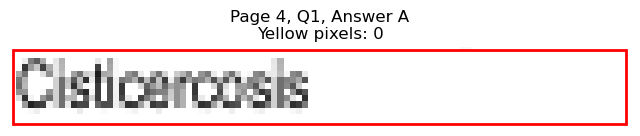

Page 4, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=144.9, y1=121.3
Page 4, Q1, B: Yellow pixels: 1081
Page 4, Q1, B: Total non-white pixels: 1443
Page 4, Q1, B: Yellow percentage: 74.9%


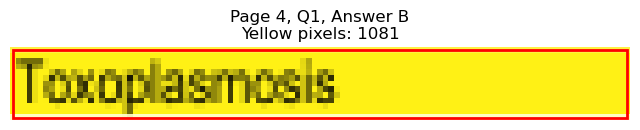

Page 4, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=129.5, y1=133.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 355
Page 4, Q1, C: Yellow percentage: 0.0%


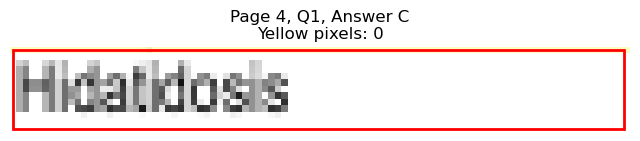

Page 4, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=387.9, y1=109.2
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 249
Page 4, Q1, D: Yellow percentage: 0.0%


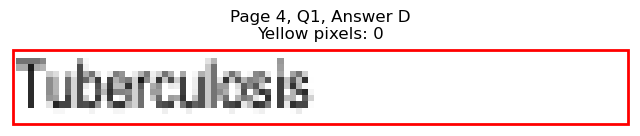

Page 4, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=383.6, y1=121.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 261
Page 4, Q1, E: Yellow percentage: 0.0%


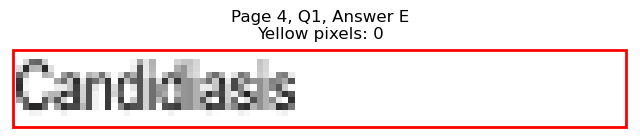


Page 4, Q1 - Selected Answer: B (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=200.8, y1=181.5
Page 4, Q2, A: Yellow pixels: 167
Page 4, Q2, A: Total non-white pixels: 740
Page 4, Q2, A: Yellow percentage: 22.6%


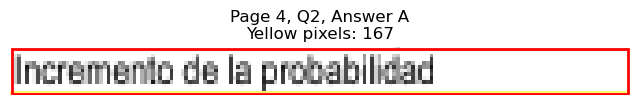

Page 4, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=174.0, y1=193.5
Page 4, Q2, B: Yellow pixels: 1493
Page 4, Q2, B: Total non-white pixels: 1833
Page 4, Q2, B: Yellow percentage: 81.5%


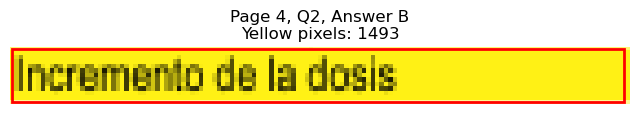

Page 4, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=177.9, y1=205.5
Page 4, Q2, C: Yellow pixels: 144
Page 4, Q2, C: Total non-white pixels: 615
Page 4, Q2, C: Yellow percentage: 23.4%


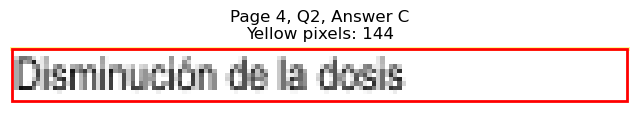

Page 4, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=469.3, y1=181.5
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 657
Page 4, Q2, D: Yellow percentage: 0.0%


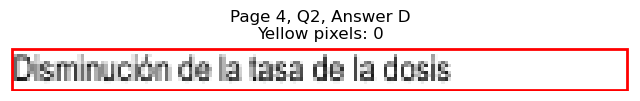

Page 4, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=502.8, y1=193.5
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 846
Page 4, Q2, E: Yellow percentage: 0.0%


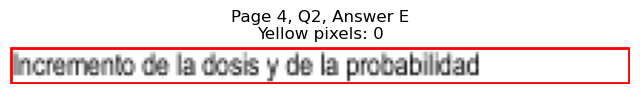


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=141.0, y1=253.8
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 294
Page 4, Q3, A: Yellow percentage: 0.0%


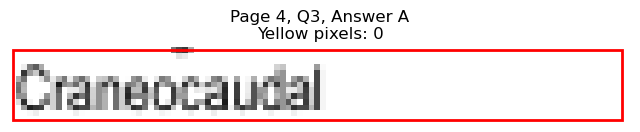

Page 4, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=134.3, y1=265.8
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 275
Page 4, Q3, B: Yellow percentage: 0.0%


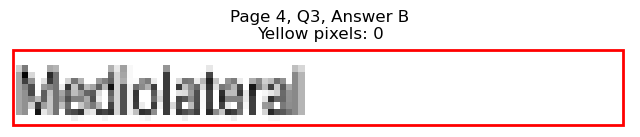

Page 4, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=141.0, y1=277.9
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 304
Page 4, Q3, C: Yellow percentage: 0.0%


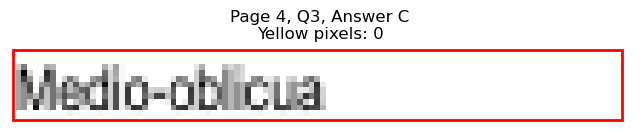

Page 4, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=365.4, y1=253.8
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 221
Page 4, Q3, D: Yellow percentage: 0.0%


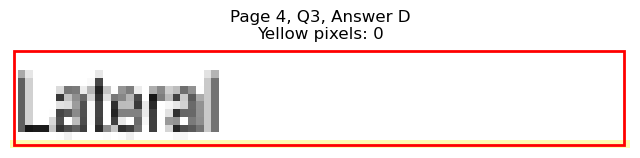

Page 4, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=381.2, y1=265.8
Page 4, Q3, E: Yellow pixels: 955
Page 4, Q3, E: Total non-white pixels: 1248
Page 4, Q3, E: Yellow percentage: 76.5%


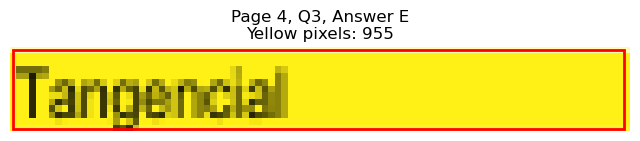


Page 4, Q3 - Selected Answer: E (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=252.1, y1=314.0
Page 4, Q4, A: Yellow pixels: 219
Page 4, Q4, A: Total non-white pixels: 1275
Page 4, Q4, A: Yellow percentage: 17.2%


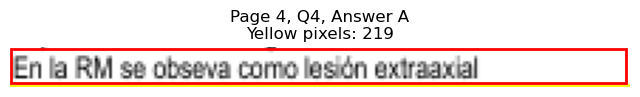

Page 4, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=294.7, y1=326.0
Page 4, Q4, B: Yellow pixels: 2307
Page 4, Q4, B: Total non-white pixels: 3654
Page 4, Q4, B: Yellow percentage: 63.1%


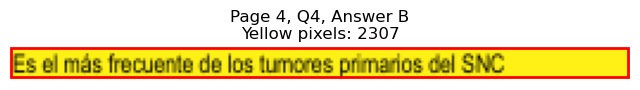

Page 4, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=263.6, y1=338.2
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 1096
Page 4, Q4, C: Yellow percentage: 0.0%


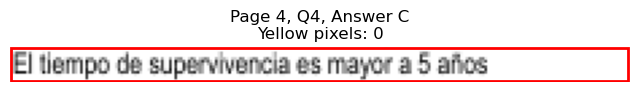

Page 4, Q4 - D: Detected box: x0=85.0, y0=338.1, x1=242.0, y1=350.2
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 817
Page 4, Q4, D: Yellow percentage: 0.0%


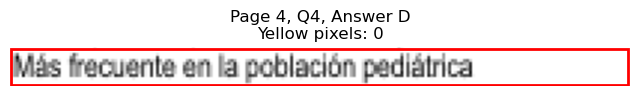

Page 4, Q4 - E: Detected box: x0=85.0, y0=350.2, x1=240.5, y1=362.3
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 776
Page 4, Q4, E: Yellow percentage: 0.0%


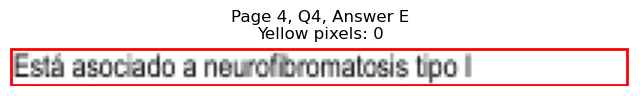


Page 4, Q4 - Selected Answer: B (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=85.0, y0=398.3, x1=165.9, y1=410.4
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 445
Page 4, Q5, A: Yellow percentage: 0.0%


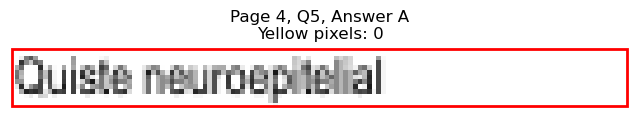

Page 4, Q5 - B: Detected box: x0=85.0, y0=410.4, x1=132.4, y1=422.5
Page 4, Q5, B: Yellow pixels: 99
Page 4, Q5, B: Total non-white pixels: 350
Page 4, Q5, B: Yellow percentage: 28.3%


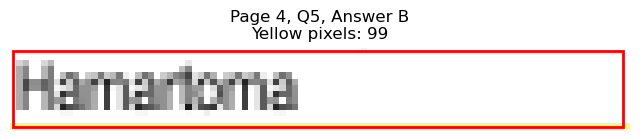

Page 4, Q5 - C: Detected box: x0=85.0, y0=422.4, x1=146.8, y1=434.5
Page 4, Q5, C: Yellow pixels: 1216
Page 4, Q5, C: Total non-white pixels: 1469
Page 4, Q5, C: Yellow percentage: 82.8%


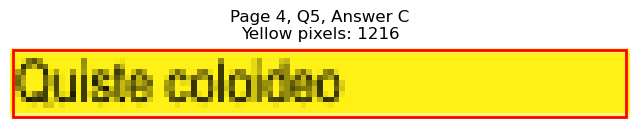

Page 4, Q5 - D: Detected box: x0=336.7, y0=398.3, x1=386.0, y1=410.4
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 263
Page 4, Q5, D: Yellow percentage: 0.0%


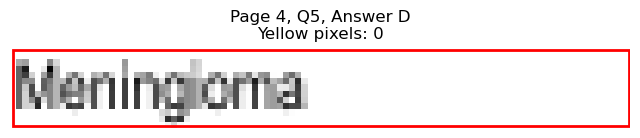

Page 4, Q5 - E: Detected box: x0=336.7, y0=410.4, x1=417.6, y1=422.5
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 418
Page 4, Q5, E: Yellow percentage: 0.0%


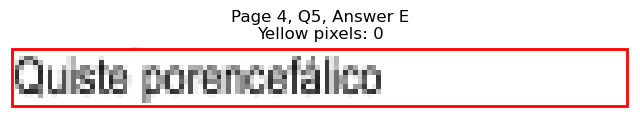


Page 4, Q5 - Selected Answer: C (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=85.0, y0=458.6, x1=121.8, y1=470.7
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 190
Page 4, Q6, A: Yellow percentage: 0.0%


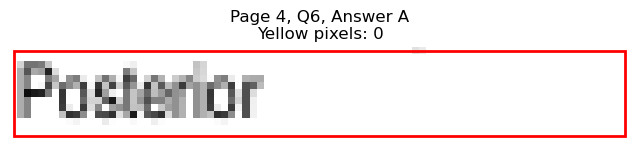

Page 4, Q6 - B: Detected box: x0=85.0, y0=470.7, x1=119.9, y1=482.8
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 176
Page 4, Q6, B: Yellow percentage: 0.0%


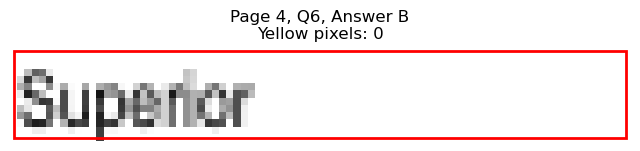

Page 4, Q6 - C: Detected box: x0=85.0, y0=482.7, x1=113.7, y1=494.8
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 135
Page 4, Q6, C: Yellow percentage: 0.0%


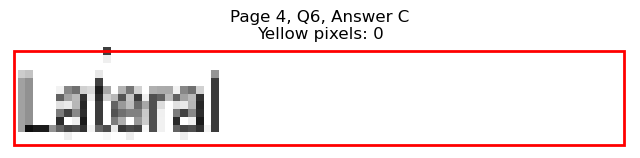

Page 4, Q6 - D: Detected box: x0=336.7, y0=458.6, x1=362.5, y1=470.7
Page 4, Q6, D: Yellow pixels: 889
Page 4, Q6, D: Total non-white pixels: 1001
Page 4, Q6, D: Yellow percentage: 88.8%


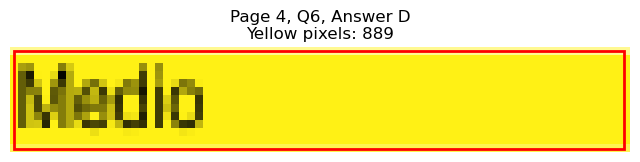

Page 4, Q6 - E: Detected box: x0=336.7, y0=470.7, x1=369.2, y1=482.8
Page 4, Q6, E: Yellow pixels: 84
Page 4, Q6, E: Total non-white pixels: 239
Page 4, Q6, E: Yellow percentage: 35.1%


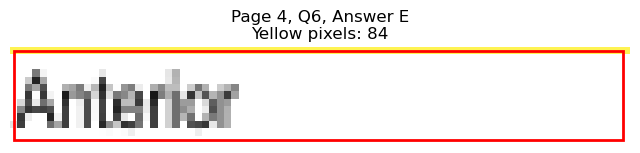


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=211.9, y1=530.9
Page 4, Q7, A: Yellow pixels: 1616
Page 4, Q7, A: Total non-white pixels: 2314
Page 4, Q7, A: Yellow percentage: 69.8%


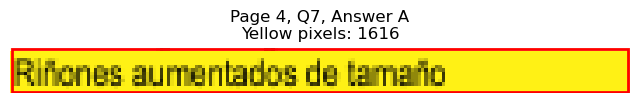

Page 4, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=214.7, y1=543.0
Page 4, Q7, B: Yellow pixels: 181
Page 4, Q7, B: Total non-white pixels: 825
Page 4, Q7, B: Yellow percentage: 21.9%


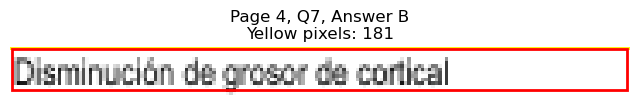

Page 4, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=159.1, y1=555.0
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 399
Page 4, Q7, C: Yellow percentage: 0.0%


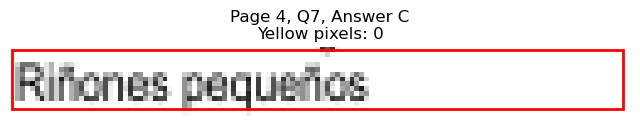

Page 4, Q7 - D: Detected box: x0=336.7, y0=518.8, x1=488.4, y1=530.9
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 768
Page 4, Q7, D: Yellow percentage: 0.0%


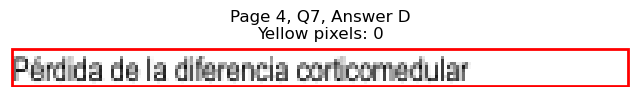

Page 4, Q7 - E: Detected box: x0=336.7, y0=530.9, x1=505.7, y1=543.0
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 865
Page 4, Q7, E: Yellow percentage: 0.0%


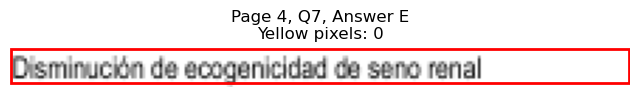


Page 4, Q7 - Selected Answer: A (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=85.0, y0=579.1, x1=192.9, y1=591.2
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 550
Page 4, Q8, A: Yellow percentage: 0.0%


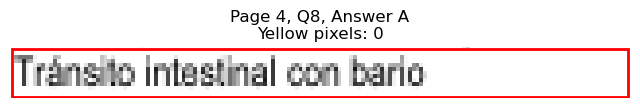

Page 4, Q8 - B: Detected box: x0=85.0, y0=591.2, x1=169.8, y1=603.3
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 434
Page 4, Q8, B: Yellow percentage: 0.0%


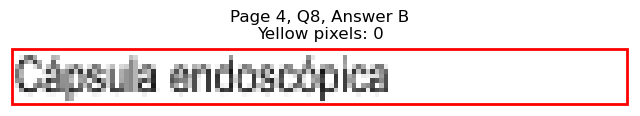

Page 4, Q8 - C: Detected box: x0=85.0, y0=603.2, x1=163.6, y1=615.3
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 375
Page 4, Q8, C: Yellow percentage: 0.0%


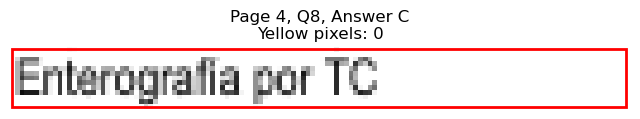

Page 4, Q8 - D: Detected box: x0=336.7, y0=579.1, x1=469.3, y1=591.2
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 682
Page 4, Q8, D: Yellow percentage: 0.0%


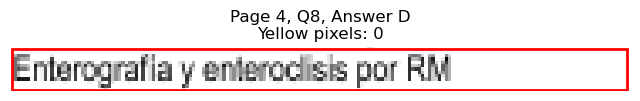

Page 4, Q8 - E: Detected box: x0=336.7, y0=591.2, x1=421.0, y1=603.3
Page 4, Q8, E: Yellow pixels: 1295
Page 4, Q8, E: Total non-white pixels: 1768
Page 4, Q8, E: Yellow percentage: 73.2%


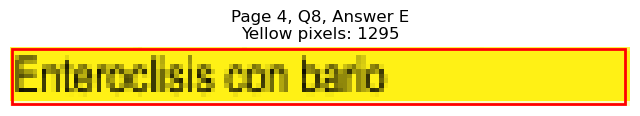


Page 4, Q8 - Selected Answer: E (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=85.0, y0=663.4, x1=147.3, y1=675.5
Page 4, Q9, A: Yellow pixels: 1230
Page 4, Q9, A: Total non-white pixels: 1482
Page 4, Q9, A: Yellow percentage: 83.0%


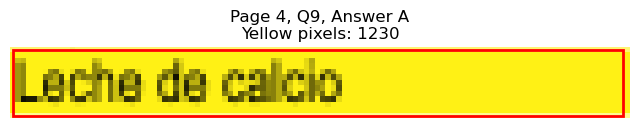

Page 4, Q9 - B: Detected box: x0=85.0, y0=675.4, x1=124.2, y1=687.5
Page 4, Q9, B: Yellow pixels: 91
Page 4, Q9, B: Total non-white pixels: 298
Page 4, Q9, B: Yellow percentage: 30.5%


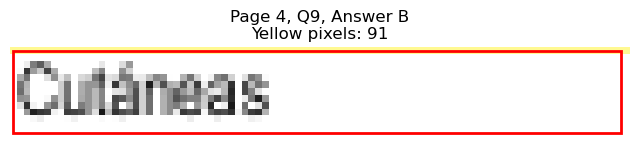

Page 4, Q9 - C: Detected box: x0=85.0, y0=687.5, x1=137.2, y1=699.7
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 261
Page 4, Q9, C: Yellow percentage: 0.0%


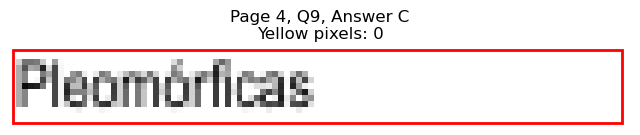

Page 4, Q9 - D: Detected box: x0=336.7, y0=663.4, x1=381.7, y1=675.5
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 225
Page 4, Q9, D: Yellow percentage: 0.0%


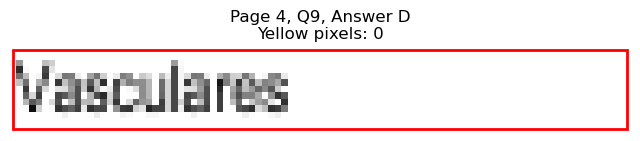

Page 4, Q9 - E: Detected box: x0=336.7, y0=675.4, x1=379.3, y1=687.5
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 221
Page 4, Q9, E: Yellow percentage: 0.0%


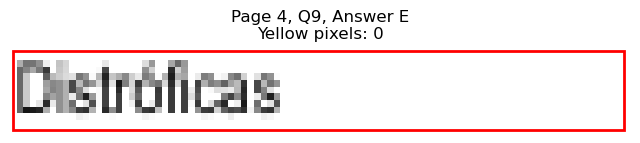


Page 4, Q9 - Selected Answer: A (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=85.0, y0=723.7, x1=104.2, y1=735.8
Page 4, Q10, A: Yellow pixels: 0
Page 4, Q10, A: Total non-white pixels: 87
Page 4, Q10, A: Yellow percentage: 0.0%


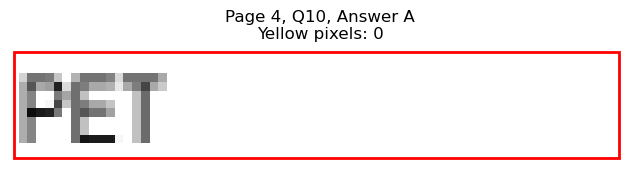

Page 4, Q10 - B: Detected box: x0=85.0, y0=735.8, x1=132.9, y1=747.9
Page 4, Q10, B: Yellow pixels: 0
Page 4, Q10, B: Total non-white pixels: 250
Page 4, Q10, B: Yellow percentage: 0.0%


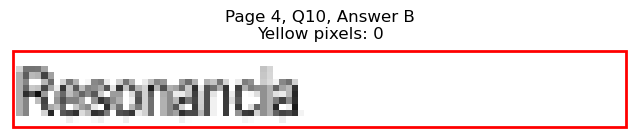

Page 4, Q10 - C: Detected box: x0=85.0, y0=747.8, x1=146.3, y1=759.9
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 308
Page 4, Q10, C: Yellow percentage: 0.0%


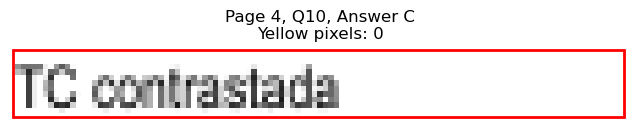

Page 4, Q10 - D: Detected box: x0=336.7, y0=723.7, x1=375.9, y1=735.8
Page 4, Q10, D: Yellow pixels: 911
Page 4, Q10, D: Total non-white pixels: 1170
Page 4, Q10, D: Yellow percentage: 77.9%


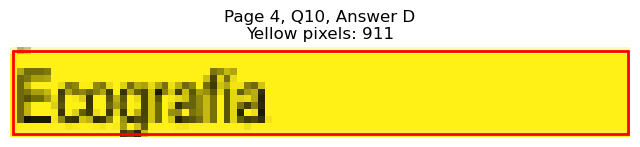

Page 4, Q10 - E: Detected box: x0=336.7, y0=735.8, x1=408.5, y1=747.9
Page 4, Q10, E: Yellow pixels: 119
Page 4, Q10, E: Total non-white pixels: 489
Page 4, Q10, E: Yellow percentage: 24.3%


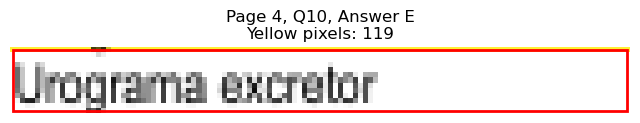


Page 4, Q10 - Selected Answer: D (based on yellow pixel count)





Page 5: Found 10 questions
Page 5, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=490.4, y1=109.2
Page 5, Q1, A: Yellow pixels: 3678
Page 5, Q1, A: Total non-white pixels: 5746
Page 5, Q1, A: Yellow percentage: 64.0%


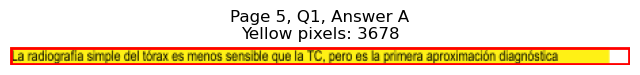

Page 5, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=441.8, y1=121.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 2174
Page 5, Q1, B: Yellow percentage: 0.0%


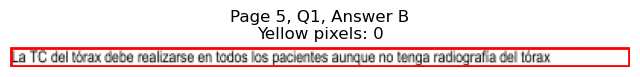

Page 5, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=373.2, y1=133.3
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 1428
Page 5, Q1, C: Yellow percentage: 0.0%


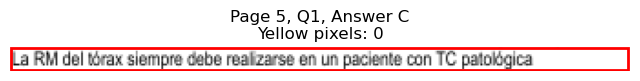

Page 5, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=367.4, y1=145.3
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 1391
Page 5, Q1, D: Yellow percentage: 0.0%


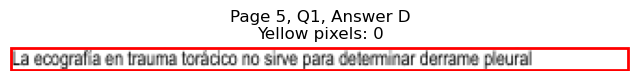

Page 5, Q1 - E: Detected box: x0=85.0, y0=145.3, x1=375.6, y1=157.4
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 1418
Page 5, Q1, E: Yellow percentage: 0.0%


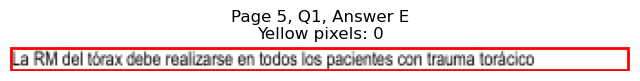


Page 5, Q1 - Selected Answer: A (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=132.4, y1=193.5
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 252
Page 5, Q2, A: Yellow percentage: 0.0%


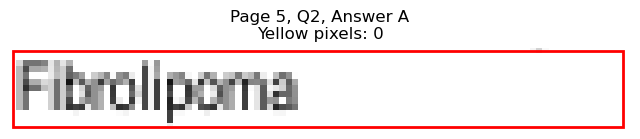

Page 5, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=134.3, y1=205.5
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 272
Page 5, Q2, B: Yellow percentage: 0.0%


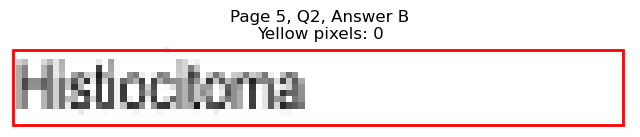

Page 5, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=166.3, y1=217.7
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 445
Page 5, Q2, C: Yellow percentage: 0.0%


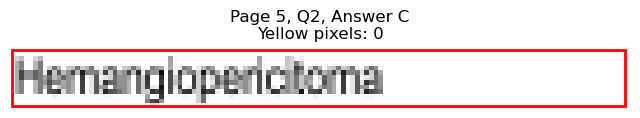

Page 5, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=402.8, y1=193.5
Page 5, Q2, D: Yellow pixels: 1256
Page 5, Q2, D: Total non-white pixels: 1521
Page 5, Q2, D: Yellow percentage: 82.6%


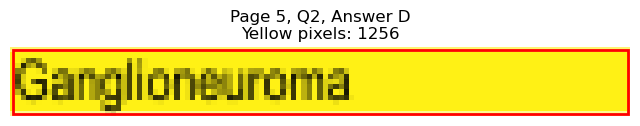

Page 5, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=394.2, y1=205.5
Page 5, Q2, E: Yellow pixels: 109
Page 5, Q2, E: Total non-white pixels: 404
Page 5, Q2, E: Yellow percentage: 27.0%


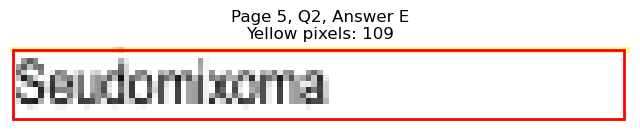


Page 5, Q2 - Selected Answer: D (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=166.3, y1=253.8
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 416
Page 5, Q3, A: Yellow percentage: 0.0%


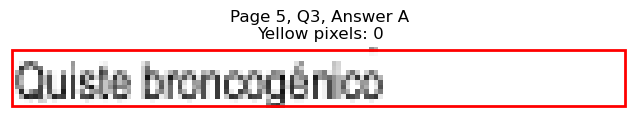

Page 5, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=230.1, y1=265.8
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 737
Page 5, Q3, B: Yellow percentage: 0.0%


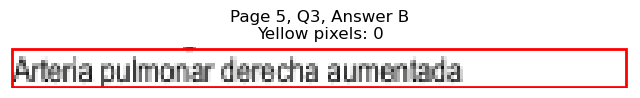

Page 5, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=150.0, y1=277.9
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 297
Page 5, Q3, C: Yellow percentage: 0.0%


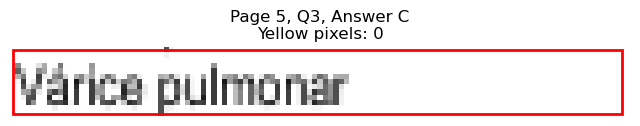

Page 5, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=396.1, y1=253.8
Page 5, Q3, D: Yellow pixels: 1093
Page 5, Q3, D: Total non-white pixels: 1443
Page 5, Q3, D: Yellow percentage: 75.7%


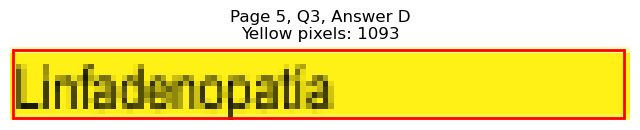

Page 5, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=475.1, y1=265.8
Page 5, Q3, E: Yellow pixels: 189
Page 5, Q3, E: Total non-white pixels: 893
Page 5, Q3, E: Yellow percentage: 21.2%


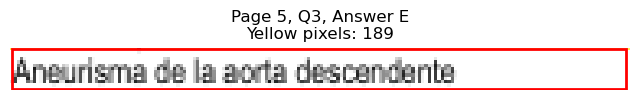


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=251.1, y1=314.0
Page 5, Q4, A: Yellow pixels: 1617
Page 5, Q4, A: Total non-white pixels: 2483
Page 5, Q4, A: Yellow percentage: 65.1%


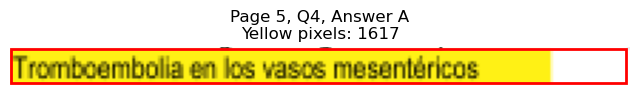

Page 5, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=161.5, y1=326.0
Page 5, Q4, B: Yellow pixels: 128
Page 5, Q4, B: Total non-white pixels: 565
Page 5, Q4, B: Yellow percentage: 22.7%


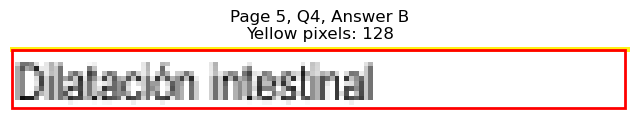

Page 5, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=182.2, y1=338.2
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 461
Page 5, Q4, C: Yellow percentage: 0.0%


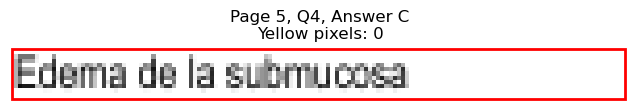

Page 5, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=415.6, y1=314.0
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 401
Page 5, Q4, D: Yellow percentage: 0.0%


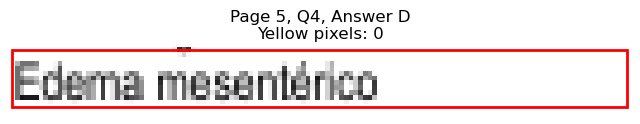

Page 5, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=363.9, y1=326.0
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 138
Page 5, Q4, E: Yellow percentage: 0.0%


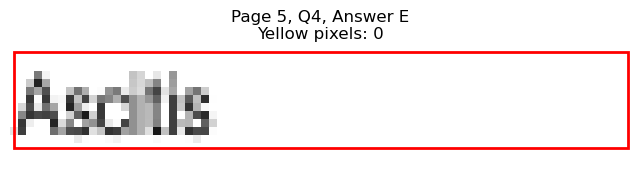


Page 5, Q4 - Selected Answer: A (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=140.1, y1=386.3
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 285
Page 5, Q5, A: Yellow percentage: 0.0%


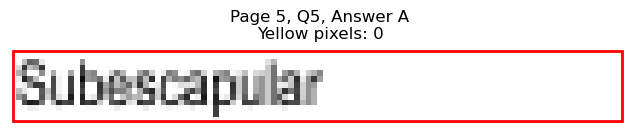

Page 5, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=144.9, y1=398.4
Page 5, Q5, B: Yellow pixels: 1086
Page 5, Q5, B: Total non-white pixels: 1443
Page 5, Q5, B: Yellow percentage: 75.3%


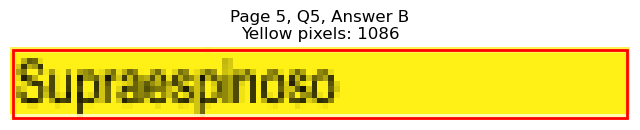

Page 5, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=139.1, y1=410.4
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 381
Page 5, Q5, C: Yellow percentage: 0.0%


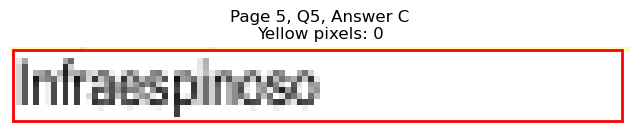

Page 5, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=383.1, y1=386.3
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 231
Page 5, Q5, D: Yellow percentage: 0.0%


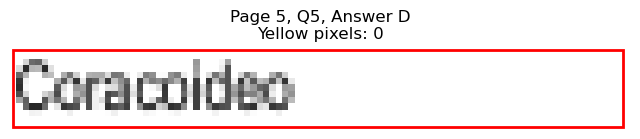

Page 5, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=400.9, y1=398.4
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 318
Page 5, Q5, E: Yellow percentage: 0.0%


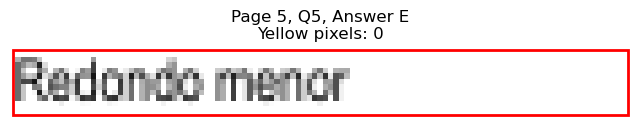


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=111.3, y1=446.5
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 139
Page 5, Q6, A: Yellow percentage: 0.0%


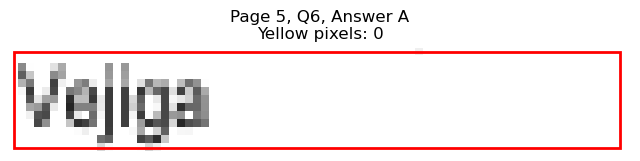

Page 5, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=176.9, y1=458.7
Page 5, Q6, B: Yellow pixels: 143
Page 5, Q6, B: Total non-white pixels: 619
Page 5, Q6, B: Yellow percentage: 23.1%


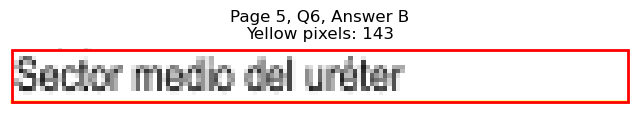

Page 5, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=159.6, y1=470.7
Page 5, Q6, C: Yellow pixels: 1318
Page 5, Q6, C: Total non-white pixels: 1638
Page 5, Q6, C: Yellow percentage: 80.5%


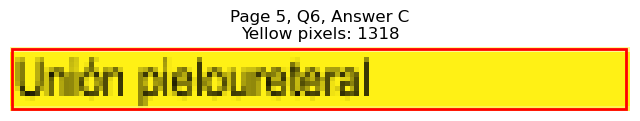

Page 5, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=420.4, y1=446.5
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 420
Page 5, Q6, D: Yellow percentage: 0.0%


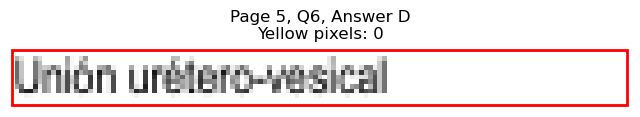

Page 5, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=383.6, y1=458.7
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 226
Page 5, Q6, E: Yellow percentage: 0.0%


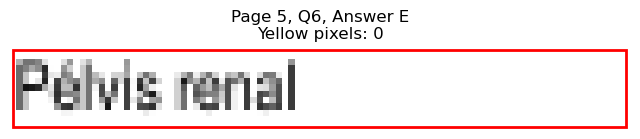


Page 5, Q6 - Selected Answer: C (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=174.5, y1=506.8
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 499
Page 5, Q7, A: Yellow percentage: 0.0%


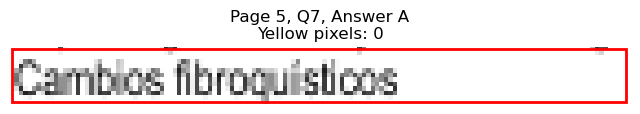

Page 5, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=144.9, y1=518.9
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 317
Page 5, Q7, B: Yellow percentage: 0.0%


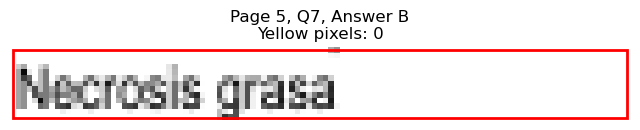

Page 5, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=165.4, y1=530.9
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 428
Page 5, Q7, C: Yellow percentage: 0.0%


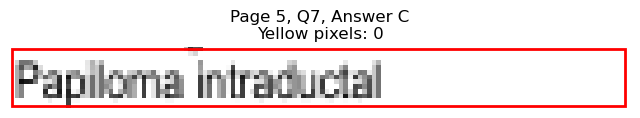

Page 5, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=394.6, y1=506.8
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 297
Page 5, Q7, D: Yellow percentage: 0.0%


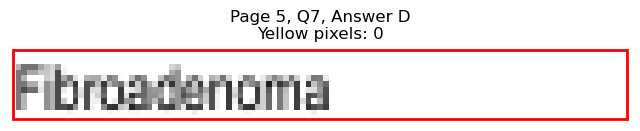

Page 5, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=431.0, y1=518.9
Page 5, Q7, E: Yellow pixels: 1383
Page 5, Q7, E: Total non-white pixels: 1885
Page 5, Q7, E: Yellow percentage: 73.4%


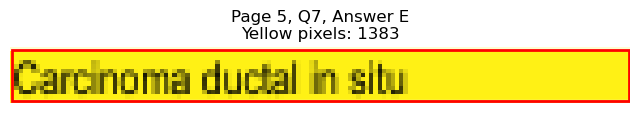


Page 5, Q7 - Selected Answer: E (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=85.0, y0=567.1, x1=171.1, y1=579.2
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 443
Page 5, Q8, A: Yellow percentage: 0.0%


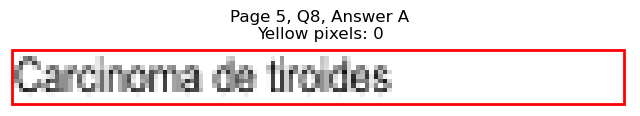

Page 5, Q8 - B: Detected box: x0=85.0, y0=579.1, x1=156.7, y1=591.2
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 372
Page 5, Q8, B: Yellow percentage: 0.0%


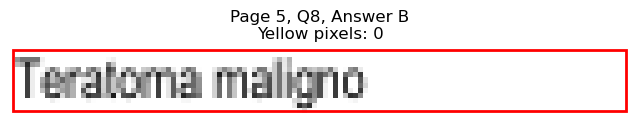

Page 5, Q8 - C: Detected box: x0=85.0, y0=591.2, x1=118.0, y1=603.3
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 165
Page 5, Q8, C: Yellow percentage: 0.0%


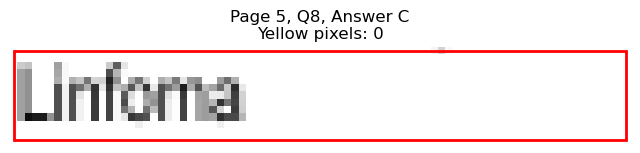

Page 5, Q8 - D: Detected box: x0=336.7, y0=567.1, x1=405.6, y1=579.2
Page 5, Q8, D: Yellow pixels: 120
Page 5, Q8, D: Total non-white pixels: 466
Page 5, Q8, D: Yellow percentage: 25.8%


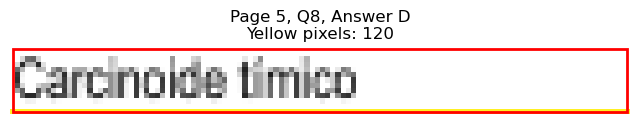

Page 5, Q8 - E: Detected box: x0=336.7, y0=579.1, x1=403.6, y1=591.2
Page 5, Q8, E: Yellow pixels: 1153
Page 5, Q8, E: Total non-white pixels: 1534
Page 5, Q8, E: Yellow percentage: 75.2%


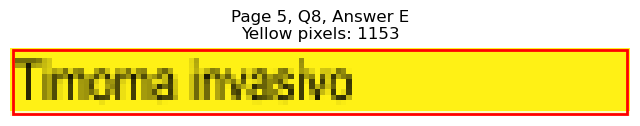


Page 5, Q8 - Selected Answer: E (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=85.0, y0=627.3, x1=221.9, y1=639.4
Page 5, Q9, A: Yellow pixels: 188
Page 5, Q9, A: Total non-white pixels: 896
Page 5, Q9, A: Yellow percentage: 21.0%


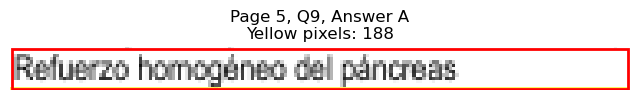

Page 5, Q9 - B: Detected box: x0=85.0, y0=639.3, x1=245.8, y1=651.4
Page 5, Q9, B: Yellow pixels: 1824
Page 5, Q9, B: Total non-white pixels: 2483
Page 5, Q9, B: Yellow percentage: 73.5%


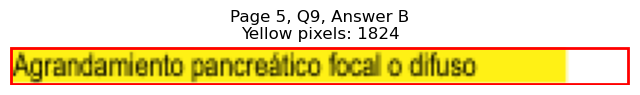

Page 5, Q9 - C: Detected box: x0=85.0, y0=651.4, x1=198.9, y1=663.5
Page 5, Q9, C: Yellow pixels: 165
Page 5, Q9, C: Total non-white pixels: 751
Page 5, Q9, C: Yellow percentage: 22.0%


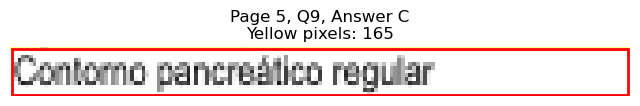

Page 5, Q9 - D: Detected box: x0=336.7, y0=627.3, x1=521.0, y1=639.4
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 924
Page 5, Q9, D: Yellow percentage: 0.0%


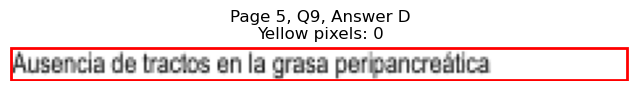

Page 5, Q9 - E: Detected box: x0=336.7, y0=639.3, x1=447.7, y1=651.4
Page 5, Q9, E: Yellow pixels: 0
Page 5, Q9, E: Total non-white pixels: 603
Page 5, Q9, E: Yellow percentage: 0.0%


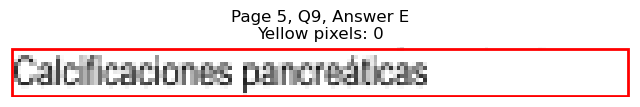


Page 5, Q9 - Selected Answer: B (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=85.0, y0=687.5, x1=442.5, y1=699.7
Page 5, Q10, A: Yellow pixels: 409
Page 5, Q10, A: Total non-white pixels: 2216
Page 5, Q10, A: Yellow percentage: 18.5%


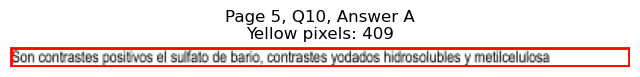

Page 5, Q10 - B: Detected box: x0=85.0, y0=699.5, x1=461.3, y1=711.7
Page 5, Q10, B: Yellow pixels: 4076
Page 5, Q10, B: Total non-white pixels: 5564
Page 5, Q10, B: Yellow percentage: 73.3%


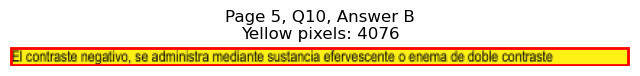

Page 5, Q10 - C: Detected box: x0=85.0, y0=711.7, x1=347.8, y1=723.8
Page 5, Q10, C: Yellow pixels: 314
Page 5, Q10, C: Total non-white pixels: 1636
Page 5, Q10, C: Yellow percentage: 19.2%


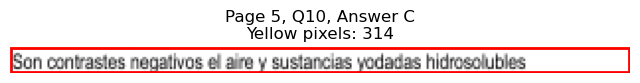

Page 5, Q10 - D: Detected box: x0=85.0, y0=723.7, x1=409.0, y1=735.8
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 1644
Page 5, Q10, D: Yellow percentage: 0.0%


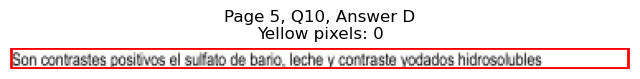

Page 5, Q10 - E: Detected box: x0=85.0, y0=735.8, x1=369.8, y1=747.9
Page 5, Q10, E: Yellow pixels: 0
Page 5, Q10, E: Total non-white pixels: 1372
Page 5, Q10, E: Yellow percentage: 0.0%


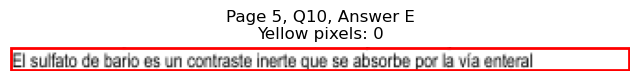


Page 5, Q10 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=152.5, y1=109.2
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 351
Page 6, Q1, A: Yellow percentage: 0.0%


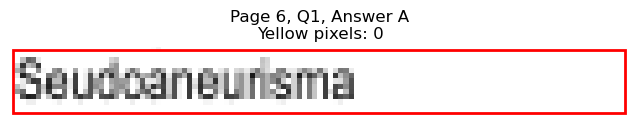

Page 6, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=220.0, y1=121.3
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 671
Page 6, Q1, B: Yellow percentage: 0.0%


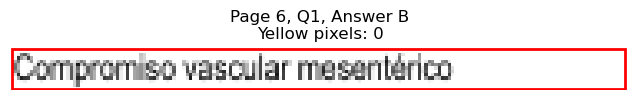

Page 6, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=159.1, y1=133.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 378
Page 6, Q1, C: Yellow percentage: 0.0%


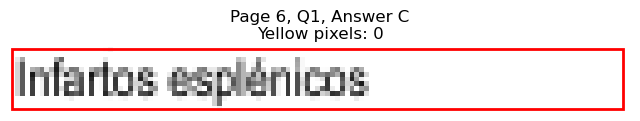

Page 6, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=460.2, y1=109.2
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 595
Page 6, Q1, D: Yellow percentage: 0.0%


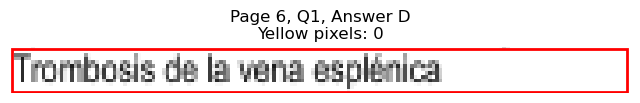

Page 6, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=423.3, y1=121.3
Page 6, Q1, E: Yellow pixels: 1315
Page 6, Q1, E: Total non-white pixels: 1794
Page 6, Q1, E: Yellow percentage: 73.3%


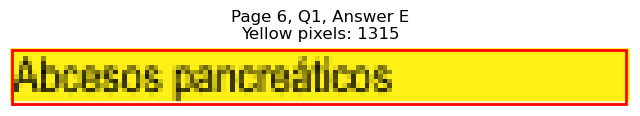


Page 6, Q1 - Selected Answer: E (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=198.9, y1=169.4
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 574
Page 6, Q2, A: Yellow percentage: 0.0%


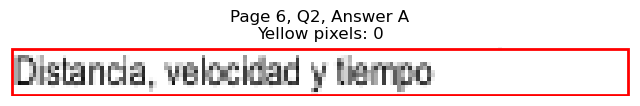

Page 6, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=202.7, y1=181.5
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 606
Page 6, Q2, B: Yellow percentage: 0.0%


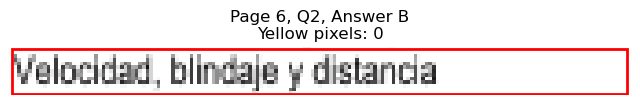

Page 6, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=197.5, y1=193.5
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 548
Page 6, Q2, C: Yellow percentage: 0.0%


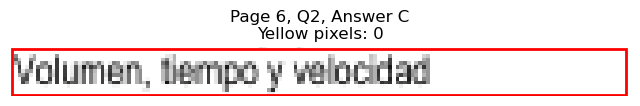

Page 6, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=447.8, y1=169.4
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 535
Page 6, Q2, D: Yellow percentage: 0.0%


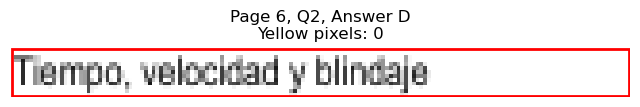

Page 6, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=444.0, y1=181.5
Page 6, Q2, E: Yellow pixels: 1591
Page 6, Q2, E: Total non-white pixels: 2054
Page 6, Q2, E: Yellow percentage: 77.5%


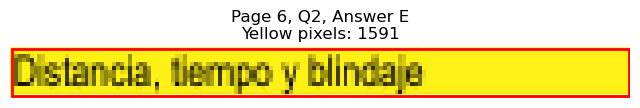


Page 6, Q2 - Selected Answer: E (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=131.4, y1=229.7
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 250
Page 6, Q3, A: Yellow percentage: 0.0%


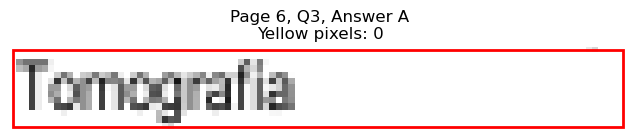

Page 6, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=132.9, y1=241.8
Page 6, Q3, B: Yellow pixels: 978
Page 6, Q3, B: Total non-white pixels: 1287
Page 6, Q3, B: Yellow percentage: 76.0%


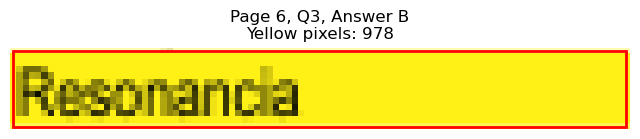

Page 6, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=131.9, y1=253.8
Page 6, Q3, C: Yellow pixels: 98
Page 6, Q3, C: Total non-white pixels: 367
Page 6, Q3, C: Yellow percentage: 26.7%


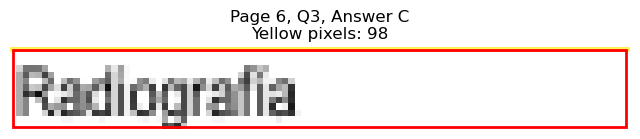

Page 6, Q3 - D: Detected box: x0=336.7, y0=217.5, x1=375.9, y1=229.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 212
Page 6, Q3, D: Yellow percentage: 0.0%


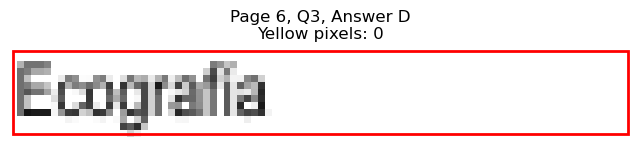

Page 6, Q3 - E: Detected box: x0=336.7, y0=229.7, x1=391.8, y1=241.8
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 285
Page 6, Q3, E: Yellow percentage: 0.0%


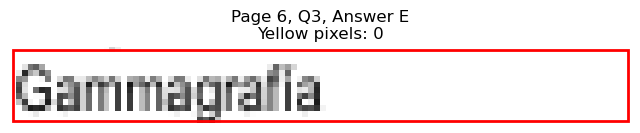


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=85.0, y0=277.8, x1=247.3, y1=289.9
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 796
Page 6, Q4, A: Yellow percentage: 0.0%


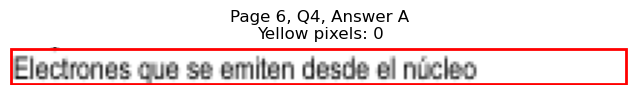

Page 6, Q4 - B: Detected box: x0=85.0, y0=289.9, x1=244.9, y1=302.0
Page 6, Q4, B: Yellow pixels: 1612
Page 6, Q4, B: Total non-white pixels: 2486
Page 6, Q4, B: Yellow percentage: 64.8%


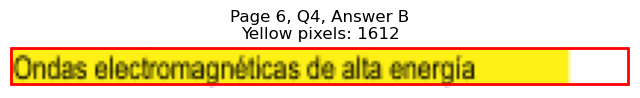

Page 6, Q4 - C: Detected box: x0=85.0, y0=301.9, x1=185.5, y1=314.0
Page 6, Q4, C: Yellow pixels: 144
Page 6, Q4, C: Total non-white pixels: 649
Page 6, Q4, C: Yellow percentage: 22.2%


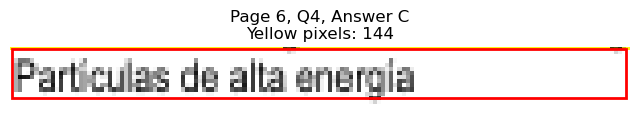

Page 6, Q4 - D: Detected box: x0=336.7, y0=277.8, x1=502.3, y1=289.9
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 838
Page 6, Q4, D: Yellow percentage: 0.0%


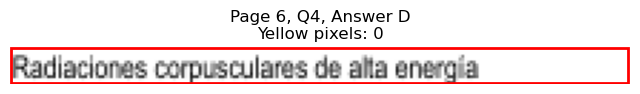

Page 6, Q4 - E: Detected box: x0=390.7, y0=289.9, x1=452.1, y1=302.0
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 549
Page 6, Q4, E: Yellow percentage: 0.0%


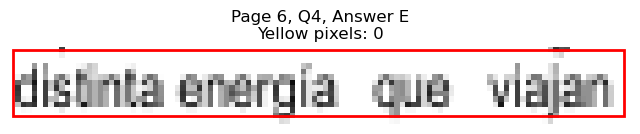


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=85.0, y0=350.2, x1=142.0, y1=362.3
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 301
Page 6, Q5, A: Yellow percentage: 0.0%


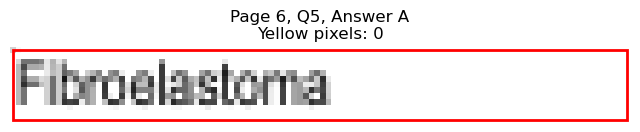

Page 6, Q5 - B: Detected box: x0=85.0, y0=362.2, x1=138.6, y1=374.3
Page 6, Q5, B: Yellow pixels: 105
Page 6, Q5, B: Total non-white pixels: 378
Page 6, Q5, B: Yellow percentage: 27.8%


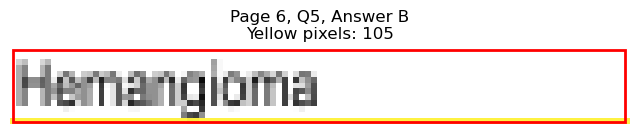

Page 6, Q5 - C: Detected box: x0=85.0, y0=374.2, x1=117.5, y1=386.3
Page 6, Q5, C: Yellow pixels: 867
Page 6, Q5, C: Total non-white pixels: 1092
Page 6, Q5, C: Yellow percentage: 79.4%


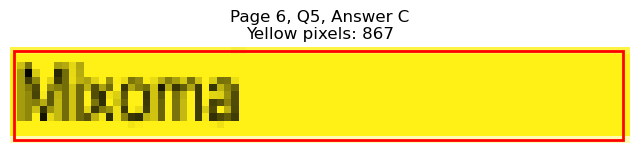

Page 6, Q5 - D: Detected box: x0=336.7, y0=350.2, x1=368.8, y1=362.3
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 136
Page 6, Q5, D: Yellow percentage: 0.0%


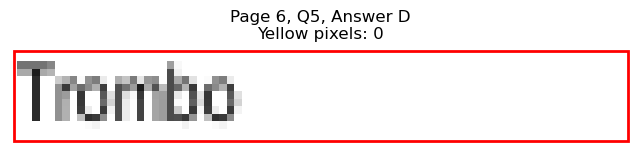

Page 6, Q5 - E: Detected box: x0=336.7, y0=362.2, x1=367.3, y1=374.3
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 141
Page 6, Q5, E: Yellow percentage: 0.0%


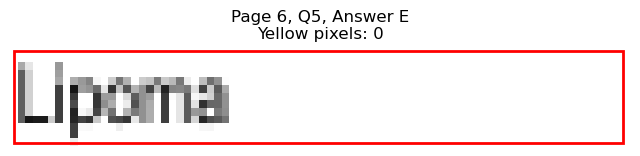


Page 6, Q5 - Selected Answer: C (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=85.0, y0=410.4, x1=116.1, y1=422.5
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 161
Page 6, Q6, A: Yellow percentage: 0.0%


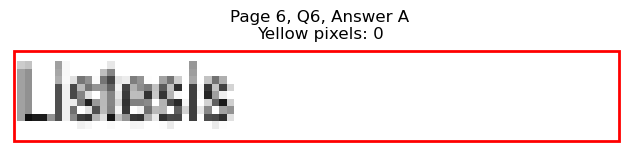

Page 6, Q6 - B: Detected box: x0=85.0, y0=422.4, x1=117.5, y1=434.5
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 170
Page 6, Q6, B: Yellow percentage: 0.0%


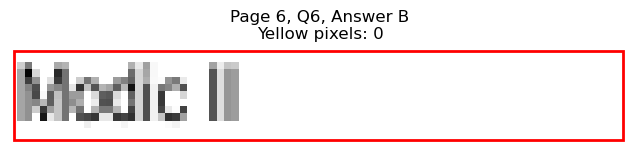

Page 6, Q6 - C: Detected box: x0=85.0, y0=434.4, x1=143.4, y1=446.5
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 283
Page 6, Q6, C: Yellow percentage: 0.0%


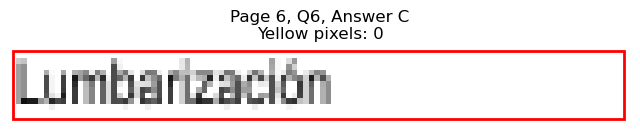

Page 6, Q6 - D: Detected box: x0=336.7, y0=410.4, x1=391.3, y1=422.5
Page 6, Q6, D: Yellow pixels: 1139
Page 6, Q6, D: Total non-white pixels: 1378
Page 6, Q6, D: Yellow percentage: 82.7%


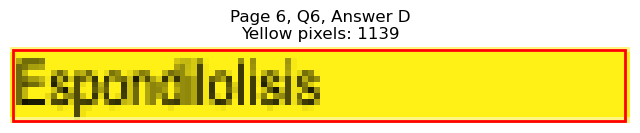

Page 6, Q6 - E: Detected box: x0=336.7, y0=422.4, x1=390.3, y1=434.5
Page 6, Q6, E: Yellow pixels: 105
Page 6, Q6, E: Total non-white pixels: 383
Page 6, Q6, E: Yellow percentage: 27.4%


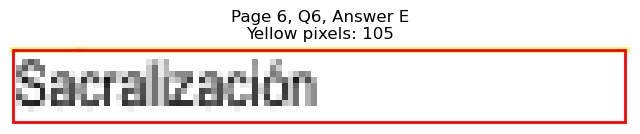


Page 6, Q6 - Selected Answer: D (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=85.0, y0=470.7, x1=144.4, y1=482.8
Page 6, Q7, A: Yellow pixels: 1080
Page 6, Q7, A: Total non-white pixels: 1443
Page 6, Q7, A: Yellow percentage: 74.8%


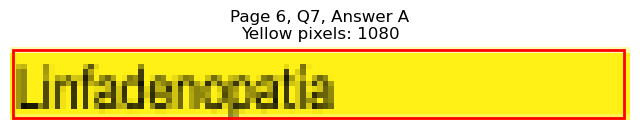

Page 6, Q7 - B: Detected box: x0=85.0, y0=482.7, x1=151.9, y1=494.8
Page 6, Q7, B: Yellow pixels: 116
Page 6, Q7, B: Total non-white pixels: 463
Page 6, Q7, B: Yellow percentage: 25.1%


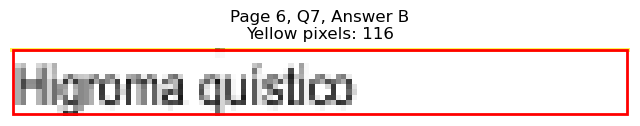

Page 6, Q7 - C: Detected box: x0=85.0, y0=494.7, x1=129.5, y1=506.8
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 239
Page 6, Q7, C: Yellow percentage: 0.0%


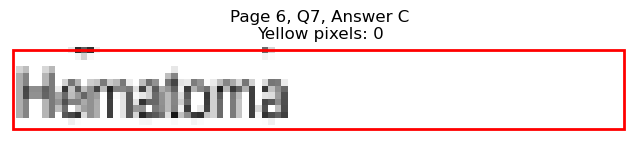

Page 6, Q7 - D: Detected box: x0=336.7, y0=470.7, x1=425.7, y1=482.8
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 463
Page 6, Q7, D: Yellow percentage: 0.0%


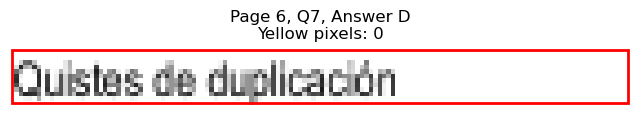

Page 6, Q7 - E: Detected box: x0=336.7, y0=482.7, x1=387.4, y1=494.8
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 266
Page 6, Q7, E: Yellow percentage: 0.0%


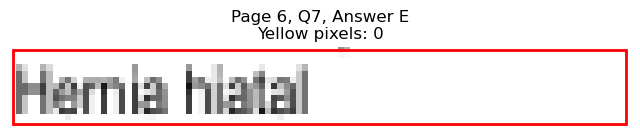


Page 6, Q7 - Selected Answer: A (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=85.0, y0=530.9, x1=519.7, y1=543.0
Page 6, Q8, A: Yellow pixels: 3508
Page 6, Q8, A: Total non-white pixels: 5758
Page 6, Q8, A: Yellow percentage: 60.9%


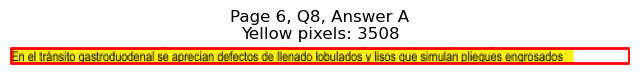

Page 6, Q8 - B: Detected box: x0=85.0, y0=542.9, x1=456.0, y1=555.0
Page 6, Q8, B: Yellow pixels: 405
Page 6, Q8, B: Total non-white pixels: 2311
Page 6, Q8, B: Yellow percentage: 17.5%


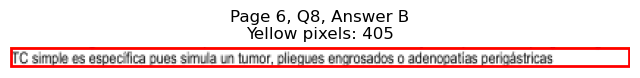

Page 6, Q8 - C: Detected box: x0=85.0, y0=554.9, x1=360.3, y1=567.0
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 1414
Page 6, Q8, C: Yellow percentage: 0.0%


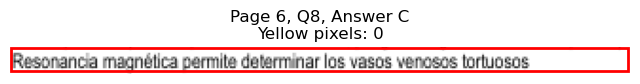

Page 6, Q8 - D: Detected box: x0=85.0, y0=567.1, x1=366.6, y1=579.2
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 1450
Page 6, Q8, D: Yellow percentage: 0.0%


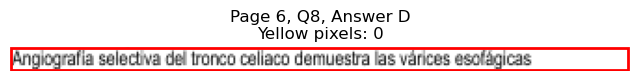

Page 6, Q8 - E: Detected box: x0=85.0, y0=579.1, x1=406.8, y1=591.2
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 1632
Page 6, Q8, E: Yellow percentage: 0.0%


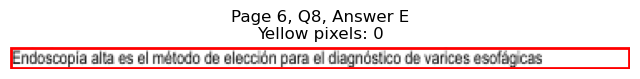


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=85.0, y0=627.3, x1=115.1, y1=639.4
Page 6, Q9, A: Yellow pixels: 849
Page 6, Q9, A: Total non-white pixels: 1066
Page 6, Q9, A: Yellow percentage: 79.6%


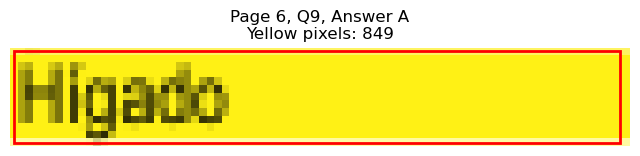

Page 6, Q9 - B: Detected box: x0=85.0, y0=639.3, x1=107.1, y1=651.4
Page 6, Q9, B: Yellow pixels: 1
Page 6, Q9, B: Total non-white pixels: 179
Page 6, Q9, B: Yellow percentage: 0.6%


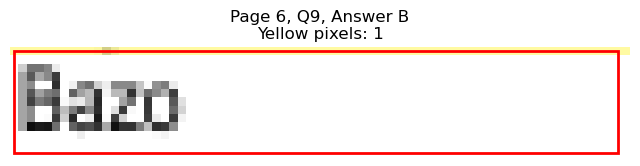

Page 6, Q9 - C: Detected box: x0=85.0, y0=651.4, x1=123.7, y1=663.5
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 196
Page 6, Q9, C: Yellow percentage: 0.0%


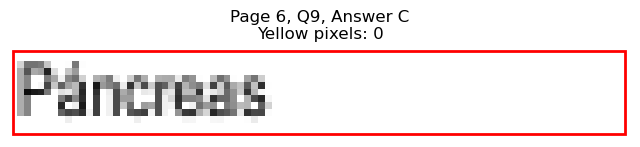

Page 6, Q9 - D: Detected box: x0=336.7, y0=627.3, x1=377.8, y1=639.4
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 227
Page 6, Q9, D: Yellow percentage: 0.0%


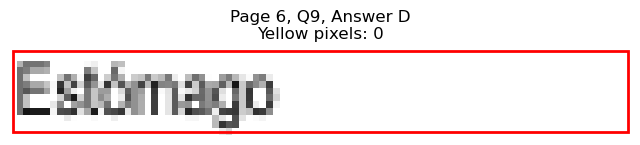

Page 6, Q9 - E: Detected box: x0=336.7, y0=639.3, x1=364.4, y1=651.4
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 125
Page 6, Q9, E: Yellow percentage: 0.0%


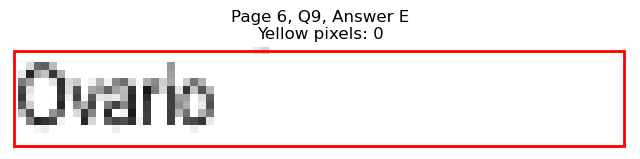


Page 6, Q9 - Selected Answer: A (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=85.0, y0=687.5, x1=216.2, y1=699.7
Page 6, Q10, A: Yellow pixels: 1837
Page 6, Q10, A: Total non-white pixels: 2379
Page 6, Q10, A: Yellow percentage: 77.2%


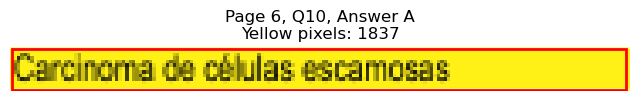

Page 6, Q10 - B: Detected box: x0=85.0, y0=699.5, x1=166.3, y1=711.7
Page 6, Q10, B: Yellow pixels: 133
Page 6, Q10, B: Total non-white pixels: 546
Page 6, Q10, B: Yellow percentage: 24.4%


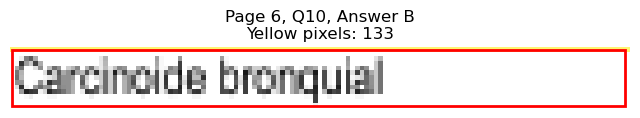

Page 6, Q10 - C: Detected box: x0=85.0, y0=711.7, x1=118.0, y1=723.8
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 163
Page 6, Q10, C: Yellow percentage: 0.0%


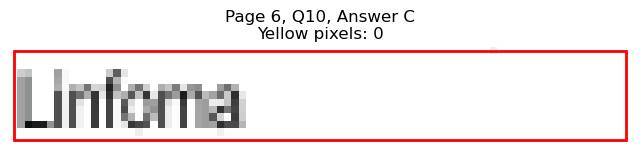

Page 6, Q10 - D: Detected box: x0=336.7, y0=687.5, x1=380.2, y1=699.7
Page 6, Q10, D: Yellow pixels: 0
Page 6, Q10, D: Total non-white pixels: 251
Page 6, Q10, D: Yellow percentage: 0.0%


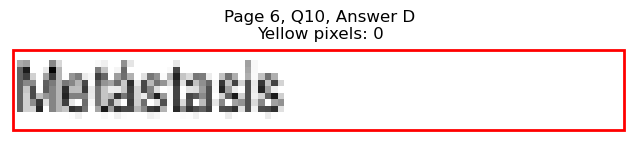

Page 6, Q10 - E: Detected box: x0=336.7, y0=699.5, x1=381.4, y1=711.7
Page 6, Q10, E: Yellow pixels: 0
Page 6, Q10, E: Total non-white pixels: 251
Page 6, Q10, E: Yellow percentage: 0.0%


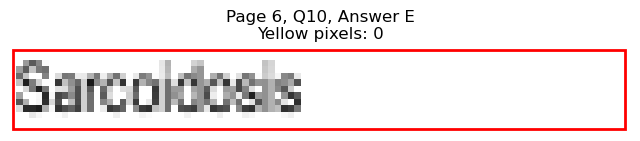


Page 6, Q10 - Selected Answer: A (based on yellow pixel count)





Page 7: Found 10 questions
Page 7, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=353.6, y1=109.2
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 1340
Page 7, Q1, A: Yellow percentage: 0.0%


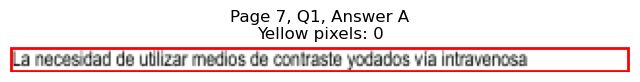

Page 7, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=336.3, y1=121.3
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 1259
Page 7, Q1, B: Yellow percentage: 0.0%


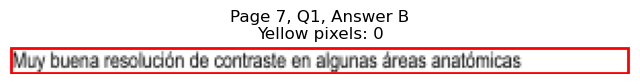

Page 7, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=275.6, y1=133.3
Page 7, Q1, C: Yellow pixels: 242
Page 7, Q1, C: Total non-white pixels: 1190
Page 7, Q1, C: Yellow percentage: 20.3%


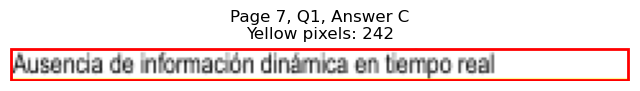

Page 7, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=377.5, y1=145.3
Page 7, Q1, D: Yellow pixels: 2977
Page 7, Q1, D: Total non-white pixels: 4472
Page 7, Q1, D: Yellow percentage: 66.6%


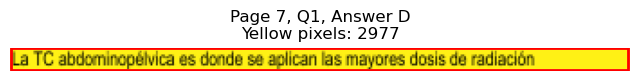

Page 7, Q1 - E: Detected box: x0=85.0, y0=145.3, x1=393.2, y1=157.4
Page 7, Q1, E: Yellow pixels: 1
Page 7, Q1, E: Total non-white pixels: 1879
Page 7, Q1, E: Yellow percentage: 0.1%


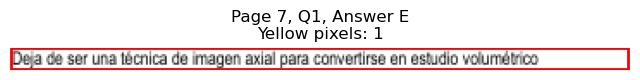


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=320.1, y1=193.5
Page 7, Q2, A: Yellow pixels: 2799
Page 7, Q2, A: Total non-white pixels: 3731
Page 7, Q2, A: Yellow percentage: 75.0%


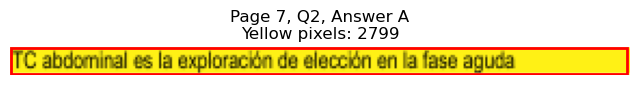

Page 7, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=324.8, y1=205.5
Page 7, Q2, B: Yellow pixels: 291
Page 7, Q2, B: Total non-white pixels: 1472
Page 7, Q2, B: Yellow percentage: 19.8%


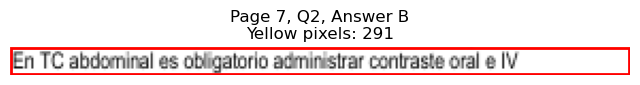

Page 7, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=425.8, y1=217.7
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 1710
Page 7, Q2, C: Yellow percentage: 0.0%


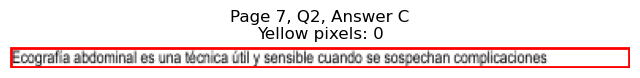

Page 7, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=318.2, y1=229.7
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 1146
Page 7, Q2, D: Yellow percentage: 0.0%


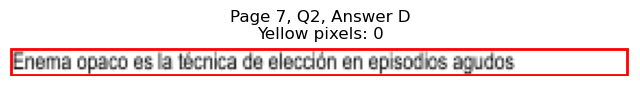

Page 7, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=268.4, y1=241.8
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 875
Page 7, Q2, E: Yellow percentage: 0.0%


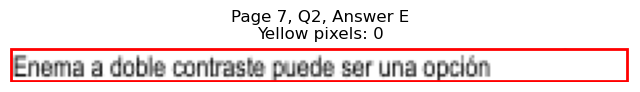


Page 7, Q2 - Selected Answer: A (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=161.5, y1=289.9
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 431
Page 7, Q3, A: Yellow percentage: 0.0%


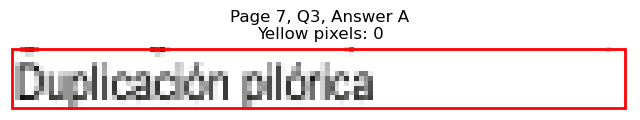

Page 7, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=154.8, y1=302.0
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 405
Page 7, Q3, B: Yellow percentage: 0.0%


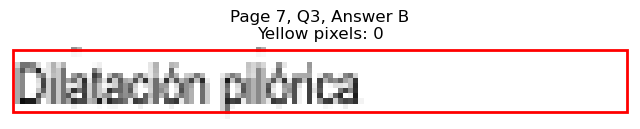

Page 7, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=177.4, y1=314.0
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 515
Page 7, Q3, C: Yellow percentage: 0.0%


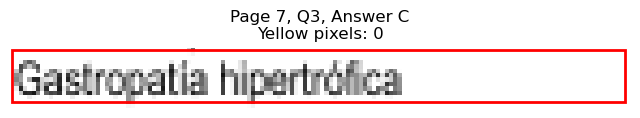

Page 7, Q3 - D: Detected box: x0=336.7, y0=277.8, x1=422.8, y1=289.9
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 453
Page 7, Q3, D: Yellow percentage: 0.0%


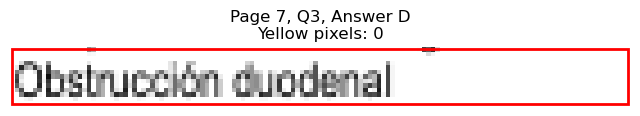

Page 7, Q3 - E: Detected box: x0=336.7, y0=289.9, x1=459.2, y1=302.0
Page 7, Q3, E: Yellow pixels: 1564
Page 7, Q3, E: Total non-white pixels: 2264
Page 7, Q3, E: Yellow percentage: 69.1%


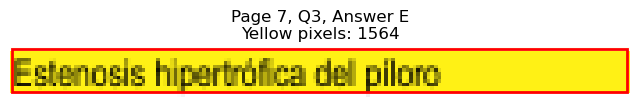


Page 7, Q3 - Selected Answer: E (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=85.0, y0=338.1, x1=442.5, y1=350.2
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 1830
Page 7, Q4, A: Yellow percentage: 0.0%


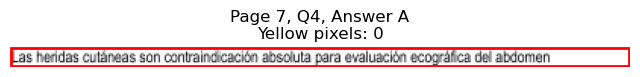

Page 7, Q4 - B: Detected box: x0=85.0, y0=350.2, x1=400.9, y1=362.3
Page 7, Q4, B: Yellow pixels: 3178
Page 7, Q4, B: Total non-white pixels: 4771
Page 7, Q4, B: Yellow percentage: 66.6%


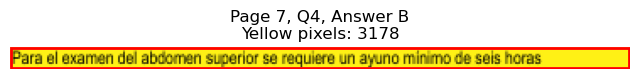

Page 7, Q4 - C: Detected box: x0=85.0, y0=362.2, x1=374.1, y1=374.3
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 1805
Page 7, Q4, C: Yellow percentage: 0.0%


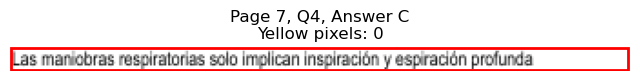

Page 7, Q4 - D: Detected box: x0=85.0, y0=374.2, x1=358.8, y1=386.3
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 1393
Page 7, Q4, D: Yellow percentage: 0.0%


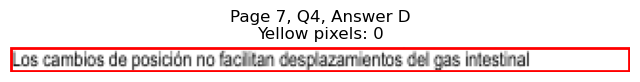

Page 7, Q4 - E: Detected box: x0=85.0, y0=386.3, x1=409.5, y1=398.4
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 1672
Page 7, Q4, E: Yellow percentage: 0.0%


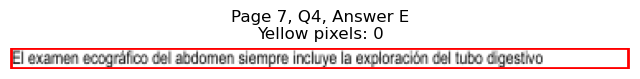


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=85.0, y0=422.4, x1=107.9, y1=434.5
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 113
Page 7, Q5, A: Yellow percentage: 0.0%


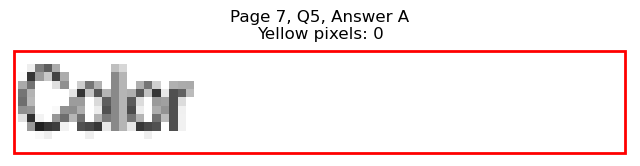

Page 7, Q5 - B: Detected box: x0=85.0, y0=434.4, x1=117.0, y1=446.5
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 163
Page 7, Q5, B: Yellow percentage: 0.0%


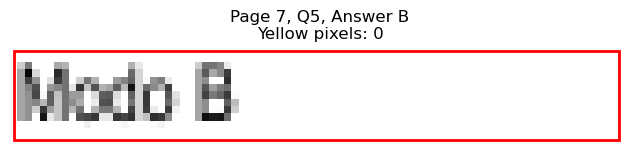

Page 7, Q5 - C: Detected box: x0=85.0, y0=446.6, x1=118.5, y1=458.7
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 160
Page 7, Q5, C: Yellow percentage: 0.0%


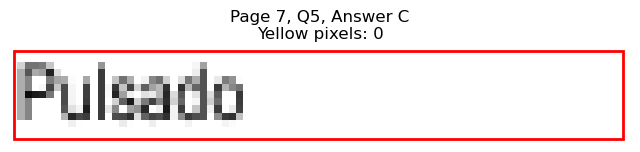

Page 7, Q5 - D: Detected box: x0=336.7, y0=422.4, x1=363.4, y1=434.5
Page 7, Q5, D: Yellow pixels: 910
Page 7, Q5, D: Total non-white pixels: 1014
Page 7, Q5, D: Yellow percentage: 89.7%


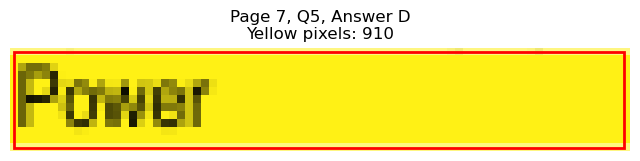

Page 7, Q5 - E: Detected box: x0=336.7, y0=434.4, x1=370.2, y1=446.5
Page 7, Q5, E: Yellow pixels: 85
Page 7, Q5, E: Total non-white pixels: 246
Page 7, Q5, E: Yellow percentage: 34.6%


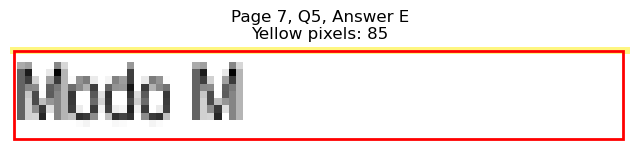


Page 7, Q5 - Selected Answer: D (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=85.0, y0=482.7, x1=171.1, y1=494.8
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 447
Page 7, Q6, A: Yellow percentage: 0.0%


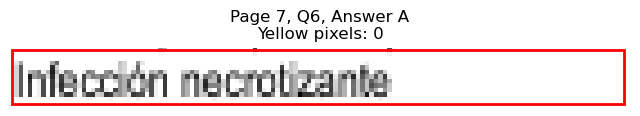

Page 7, Q6 - B: Detected box: x0=85.0, y0=494.7, x1=162.0, y1=506.8
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 389
Page 7, Q6, B: Yellow percentage: 0.0%


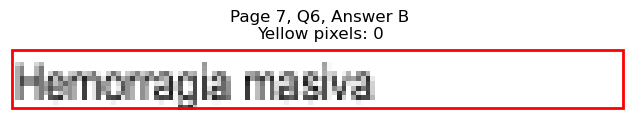

Page 7, Q6 - C: Detected box: x0=85.0, y0=506.8, x1=220.5, y1=518.9
Page 7, Q6, C: Yellow pixels: 1677
Page 7, Q6, C: Total non-white pixels: 2431
Page 7, Q6, C: Yellow percentage: 69.0%


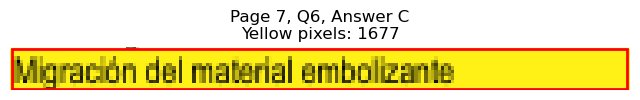

Page 7, Q6 - D: Detected box: x0=336.7, y0=482.7, x1=389.8, y1=494.8
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 249
Page 7, Q6, D: Yellow percentage: 0.0%


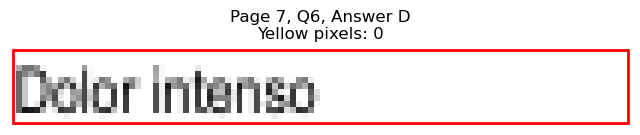

Page 7, Q6 - E: Detected box: x0=336.7, y0=494.7, x1=422.4, y1=506.8
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 446
Page 7, Q6, E: Yellow percentage: 0.0%


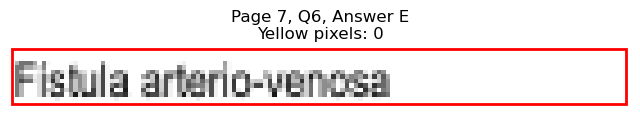


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=85.0, y0=554.9, x1=131.9, y1=567.0
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 259
Page 7, Q7, A: Yellow percentage: 0.0%


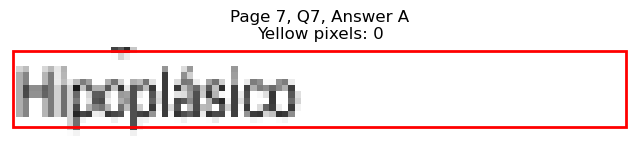

Page 7, Q7 - B: Detected box: x0=85.0, y0=567.1, x1=116.5, y1=579.2
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 168
Page 7, Q7, B: Yellow percentage: 0.0%


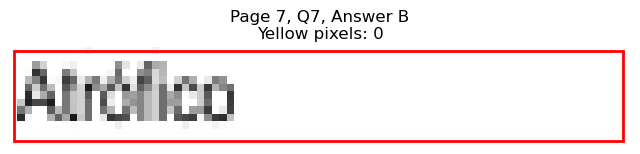

Page 7, Q7 - C: Detected box: x0=85.0, y0=579.1, x1=116.1, y1=591.2
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 169
Page 7, Q7, C: Yellow percentage: 0.0%


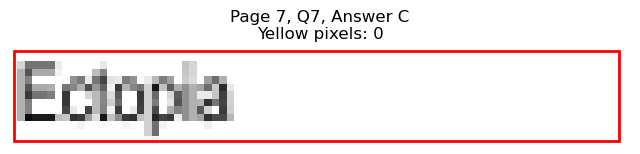

Page 7, Q7 - D: Detected box: x0=336.7, y0=554.9, x1=383.6, y1=567.0
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 240
Page 7, Q7, D: Yellow percentage: 0.0%


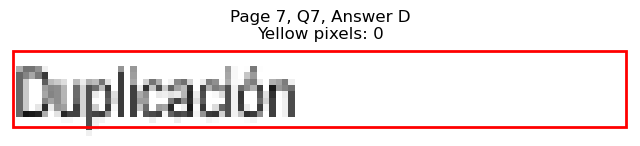

Page 7, Q7 - E: Detected box: x0=336.7, y0=567.1, x1=377.8, y1=579.2
Page 7, Q7, E: Yellow pixels: 929
Page 7, Q7, E: Total non-white pixels: 1196
Page 7, Q7, E: Yellow percentage: 77.7%


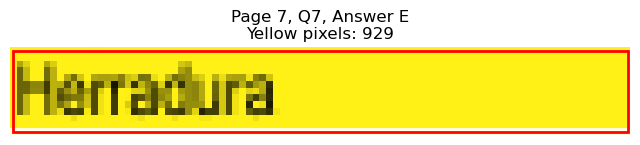


Page 7, Q7 - Selected Answer: E (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=85.0, y0=615.2, x1=130.5, y1=627.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 223
Page 7, Q8, A: Yellow percentage: 0.0%


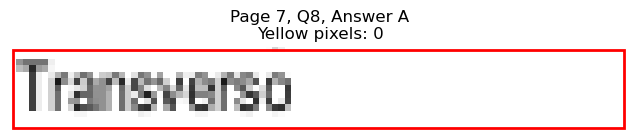

Page 7, Q8 - B: Detected box: x0=85.0, y0=627.3, x1=132.9, y1=639.4
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 243
Page 7, Q8, B: Yellow percentage: 0.0%


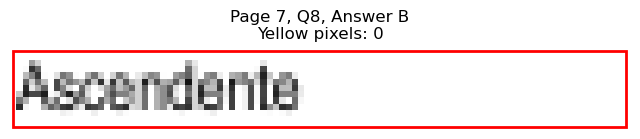

Page 7, Q8 - C: Detected box: x0=85.0, y0=639.3, x1=138.1, y1=651.4
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 285
Page 7, Q8, C: Yellow percentage: 0.0%


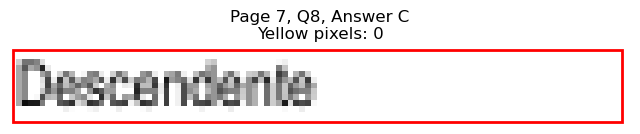

Page 7, Q8 - D: Detected box: x0=336.7, y0=615.2, x1=373.0, y1=627.3
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 192
Page 7, Q8, D: Yellow percentage: 0.0%


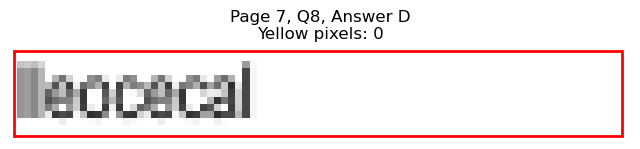

Page 7, Q8 - E: Detected box: x0=336.7, y0=627.3, x1=379.3, y1=639.4
Page 7, Q8, E: Yellow pixels: 936
Page 7, Q8, E: Total non-white pixels: 1222
Page 7, Q8, E: Yellow percentage: 76.6%


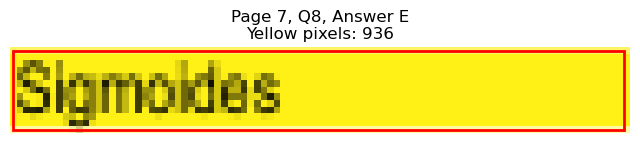


Page 7, Q8 - Selected Answer: E (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=85.0, y0=675.4, x1=139.6, y1=687.5
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 284
Page 7, Q9, A: Yellow percentage: 0.0%


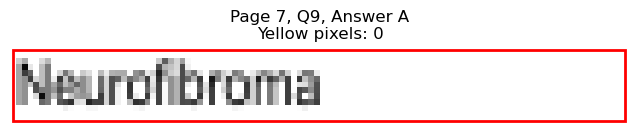

Page 7, Q9 - B: Detected box: x0=85.0, y0=687.5, x1=139.6, y1=699.7
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 270
Page 7, Q9, B: Yellow percentage: 0.0%


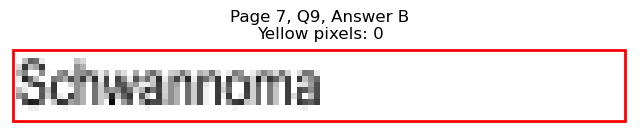

Page 7, Q9 - C: Detected box: x0=85.0, y0=699.5, x1=150.5, y1=711.7
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 362
Page 7, Q9, C: Yellow percentage: 0.0%


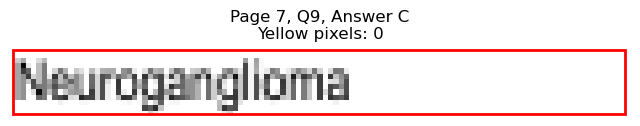

Page 7, Q9 - D: Detected box: x0=336.7, y0=675.4, x1=425.2, y1=687.5
Page 7, Q9, D: Yellow pixels: 1421
Page 7, Q9, D: Total non-white pixels: 1820
Page 7, Q9, D: Yellow percentage: 78.1%


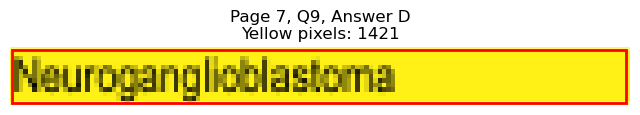

Page 7, Q9 - E: Detected box: x0=336.7, y0=687.5, x1=400.4, y1=699.7
Page 7, Q9, E: Yellow pixels: 115
Page 7, Q9, E: Total non-white pixels: 445
Page 7, Q9, E: Yellow percentage: 25.8%


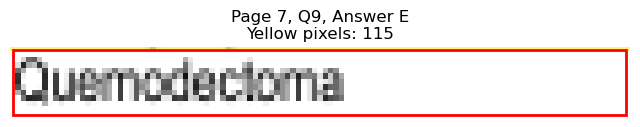


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=85.0, y0=735.8, x1=161.5, y1=747.9
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 409
Page 7, Q10, A: Yellow percentage: 0.0%


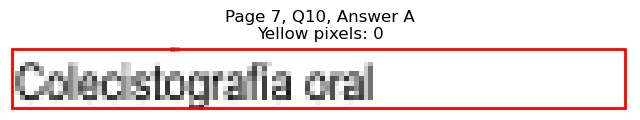

Page 7, Q10 - B: Detected box: x0=85.0, y0=747.8, x1=212.3, y1=759.9
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 672
Page 7, Q10, B: Yellow percentage: 0.0%


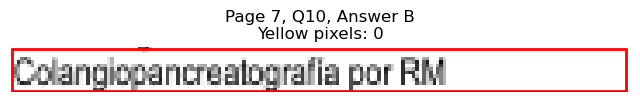

Page 7, Q10 - C: Detected box: x0=85.0, y0=759.8, x1=184.6, y1=771.9
Page 7, Q10, C: Yellow pixels: 0
Page 7, Q10, C: Total non-white pixels: 491
Page 7, Q10, C: Yellow percentage: 0.0%


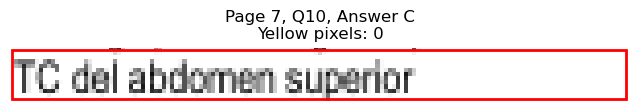

Page 7, Q10 - D: Detected box: x0=336.7, y0=735.8, x1=451.5, y1=747.9
Page 7, Q10, D: Yellow pixels: 1506
Page 7, Q10, D: Total non-white pixels: 2158
Page 7, Q10, D: Yellow percentage: 69.8%


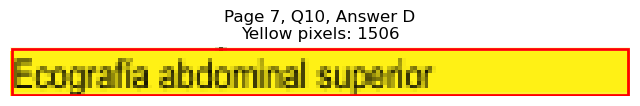

Page 7, Q10 - E: Detected box: x0=336.7, y0=747.8, x1=475.5, y1=759.9
Page 7, Q10, E: Yellow pixels: 184
Page 7, Q10, E: Total non-white pixels: 953
Page 7, Q10, E: Yellow percentage: 19.3%


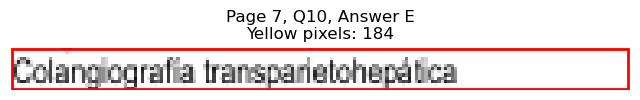


Page 7, Q10 - Selected Answer: D (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=120.9, y1=121.3
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 175
Page 8, Q1, A: Yellow percentage: 0.0%


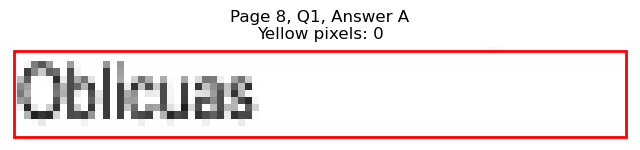

Page 8, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=139.6, y1=133.3
Page 8, Q1, B: Yellow pixels: 106
Page 8, Q1, B: Total non-white pixels: 380
Page 8, Q1, B: Yellow percentage: 27.9%


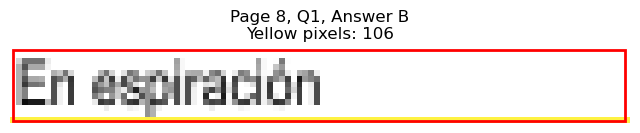

Page 8, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=122.8, y1=145.3
Page 8, Q1, C: Yellow pixels: 923
Page 8, Q1, C: Total non-white pixels: 1157
Page 8, Q1, C: Yellow percentage: 79.8%


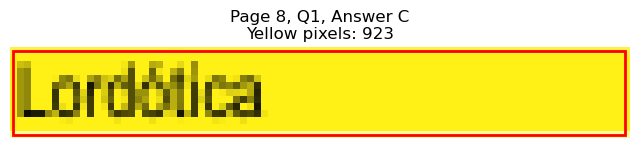

Page 8, Q1 - D: Detected box: x0=336.7, y0=109.2, x1=381.2, y1=121.3
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 231
Page 8, Q1, D: Yellow percentage: 0.0%


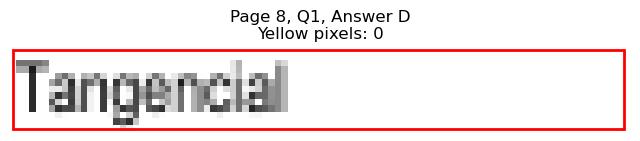

Page 8, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=399.0, y1=133.3
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 344
Page 8, Q1, E: Yellow percentage: 0.0%


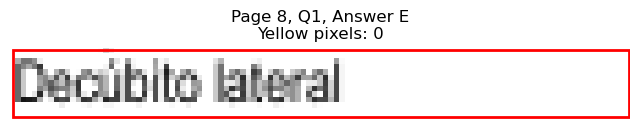


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=127.1, y1=181.5
Page 8, Q2, A: Yellow pixels: 94
Page 8, Q2, A: Total non-white pixels: 320
Page 8, Q2, A: Yellow percentage: 29.4%


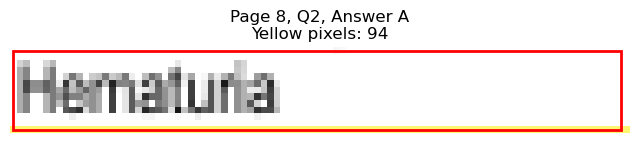

Page 8, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=160.6, y1=193.5
Page 8, Q2, B: Yellow pixels: 1318
Page 8, Q2, B: Total non-white pixels: 1651
Page 8, Q2, B: Yellow percentage: 79.8%


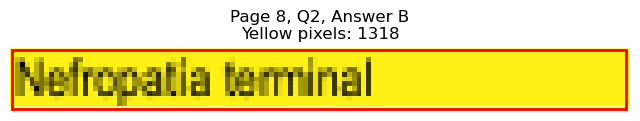

Page 8, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=131.9, y1=205.5
Page 8, Q2, C: Yellow pixels: 98
Page 8, Q2, C: Total non-white pixels: 366
Page 8, Q2, C: Yellow percentage: 26.8%


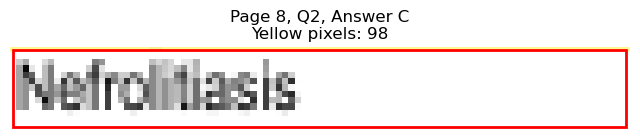

Page 8, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=388.4, y1=181.5
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 249
Page 8, Q2, D: Yellow percentage: 0.0%


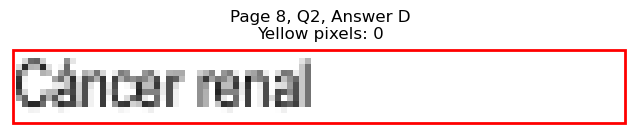

Page 8, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=432.9, y1=193.5
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 511
Page 8, Q2, E: Yellow percentage: 0.0%


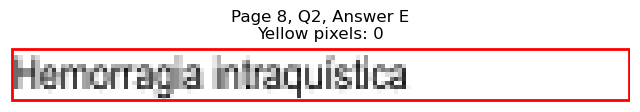


Page 8, Q2 - Selected Answer: B (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=85.0, y0=229.7, x1=109.5, y1=241.8
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 80
Page 8, Q3, A: Yellow percentage: 0.0%


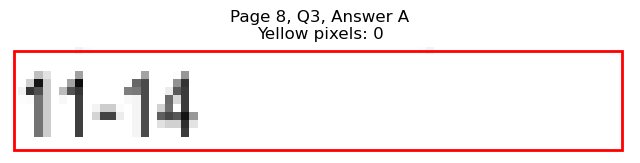

Page 8, Q3 - B: Detected box: x0=85.0, y0=241.7, x1=109.5, y1=253.8
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 188
Page 8, Q3, B: Yellow percentage: 0.0%


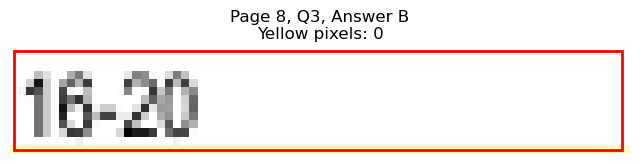

Page 8, Q3 - C: Detected box: x0=85.0, y0=253.7, x1=104.7, y1=265.8
Page 8, Q3, C: Yellow pixels: 797
Page 8, Q3, C: Total non-white pixels: 923
Page 8, Q3, C: Yellow percentage: 86.3%


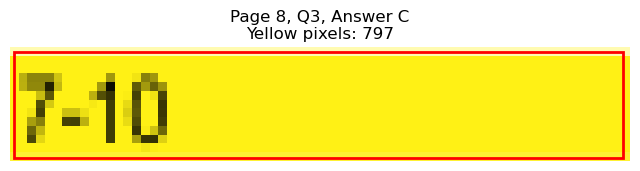

Page 8, Q3 - D: Detected box: x0=336.7, y0=229.7, x1=361.2, y1=241.8
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 120
Page 8, Q3, D: Yellow percentage: 0.0%


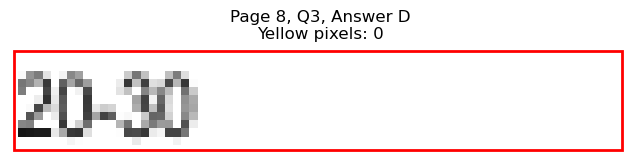

Page 8, Q3 - E: Detected box: x0=336.7, y0=241.7, x1=354.0, y1=253.8
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 49
Page 8, Q3, E: Yellow percentage: 0.0%


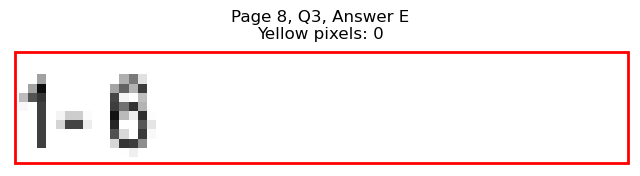


Page 8, Q3 - Selected Answer: C (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=85.0, y0=289.9, x1=195.2, y1=302.0
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 561
Page 8, Q4, A: Yellow percentage: 0.0%


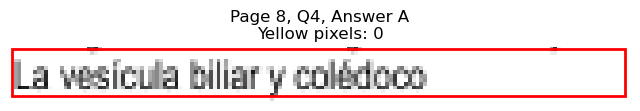

Page 8, Q4 - B: Detected box: x0=85.0, y0=301.9, x1=249.2, y1=314.0
Page 8, Q4, B: Yellow pixels: 216
Page 8, Q4, B: Total non-white pixels: 1245
Page 8, Q4, B: Yellow percentage: 17.3%


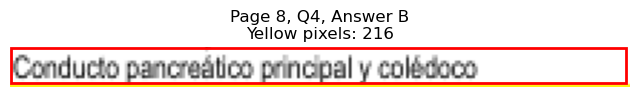

Page 8, Q4 - C: Detected box: x0=85.0, y0=313.9, x1=318.6, y1=326.0
Page 8, Q4, C: Yellow pixels: 2500
Page 8, Q4, C: Total non-white pixels: 3990
Page 8, Q4, C: Yellow percentage: 62.7%


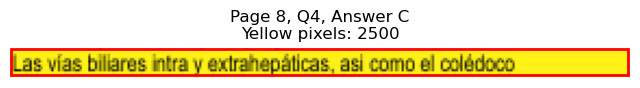

Page 8, Q4 - D: Detected box: x0=85.0, y0=326.1, x1=251.6, y1=338.2
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 1081
Page 8, Q4, D: Yellow percentage: 0.0%


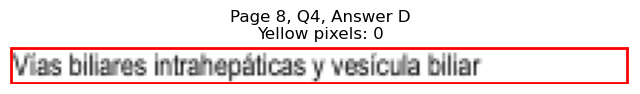

Page 8, Q4 - E: Detected box: x0=85.0, y0=338.1, x1=205.1, y1=350.2
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 601
Page 8, Q4, E: Yellow percentage: 0.0%


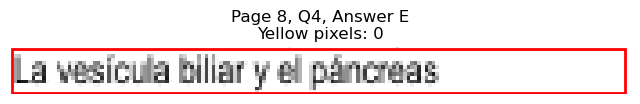


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=142.9, y1=398.4
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 306
Page 8, Q5, A: Yellow percentage: 0.0%


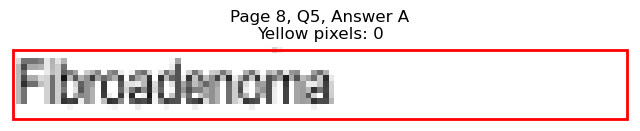

Page 8, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=140.1, y1=410.4
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 291
Page 8, Q5, B: Yellow percentage: 0.0%


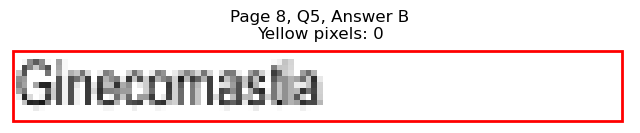

Page 8, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=112.2, y1=422.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 140
Page 8, Q5, C: Yellow percentage: 0.0%


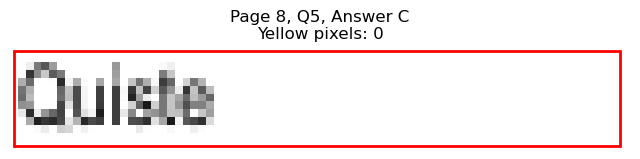

Page 8, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=414.7, y1=398.4
Page 8, Q5, D: Yellow pixels: 1213
Page 8, Q5, D: Total non-white pixels: 1677
Page 8, Q5, D: Yellow percentage: 72.3%


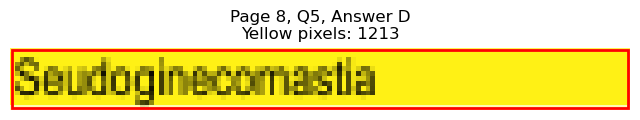

Page 8, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=375.0, y1=410.4
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 296
Page 8, Q5, E: Yellow percentage: 0.0%


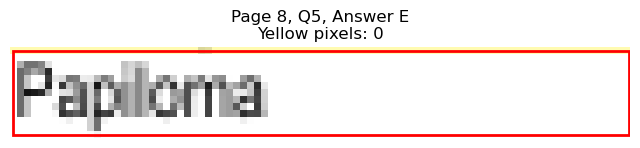


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=85.0, y0=458.6, x1=265.5, y1=470.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 958
Page 8, Q6, A: Yellow percentage: 0.0%


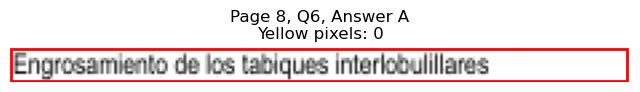

Page 8, Q6 - B: Detected box: x0=85.0, y0=470.7, x1=227.2, y1=482.8
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 677
Page 8, Q6, B: Yellow percentage: 0.0%


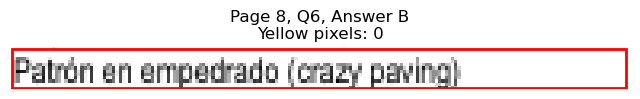

Page 8, Q6 - C: Detected box: x0=85.0, y0=482.7, x1=163.9, y1=494.8
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 414
Page 8, Q6, C: Yellow percentage: 0.0%


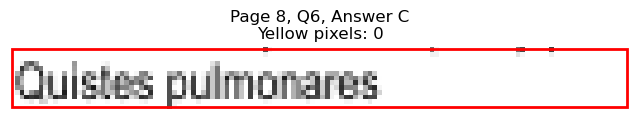

Page 8, Q6 - D: Detected box: x0=336.7, y0=458.6, x1=387.9, y1=470.7
Page 8, Q6, D: Yellow pixels: 1111
Page 8, Q6, D: Total non-white pixels: 1326
Page 8, Q6, D: Yellow percentage: 83.8%


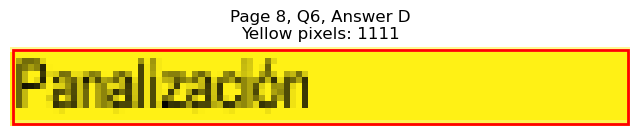

Page 8, Q6 - E: Detected box: x0=336.7, y0=470.7, x1=405.6, y1=482.8
Page 8, Q6, E: Yellow pixels: 120
Page 8, Q6, E: Total non-white pixels: 471
Page 8, Q6, E: Yellow percentage: 25.5%


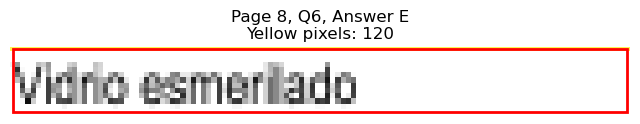


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=309.1, y1=530.9
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 1122
Page 8, Q7, A: Yellow percentage: 0.0%


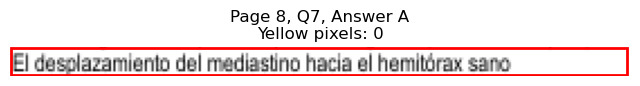

Page 8, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=288.4, y1=543.0
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 1035
Page 8, Q7, B: Yellow percentage: 0.0%


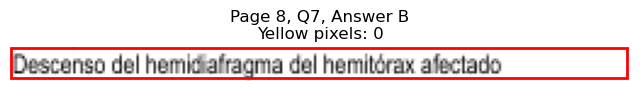

Page 8, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=248.8, y1=555.0
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 828
Page 8, Q7, C: Yellow percentage: 0.0%


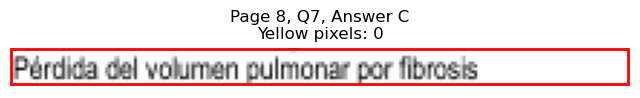

Page 8, Q7 - D: Detected box: x0=85.0, y0=554.9, x1=360.7, y1=567.0
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 1400
Page 8, Q7, D: Yellow percentage: 0.0%


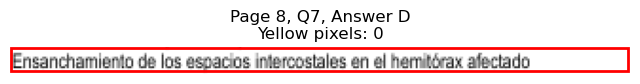

Page 8, Q7 - E: Detected box: x0=85.0, y0=567.1, x1=333.9, y1=579.2
Page 8, Q7, E: Yellow pixels: 2645
Page 8, Q7, E: Total non-white pixels: 3900
Page 8, Q7, E: Yellow percentage: 67.8%


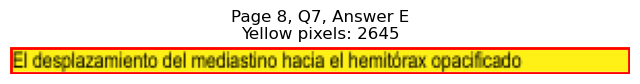


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=85.0, y0=603.2, x1=194.6, y1=615.3
Page 8, Q8, A: Yellow pixels: 161
Page 8, Q8, A: Total non-white pixels: 763
Page 8, Q8, A: Yellow percentage: 21.1%


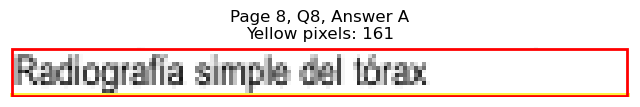

Page 8, Q8 - B: Detected box: x0=85.0, y0=615.2, x1=157.7, y1=627.3
Page 8, Q8, B: Yellow pixels: 1183
Page 8, Q8, B: Total non-white pixels: 1612
Page 8, Q8, B: Yellow percentage: 73.4%


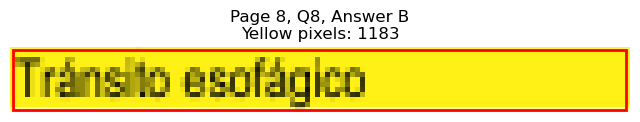

Page 8, Q8 - C: Detected box: x0=85.0, y0=627.3, x1=223.9, y1=639.4
Page 8, Q8, C: Yellow pixels: 2
Page 8, Q8, C: Total non-white pixels: 888
Page 8, Q8, C: Yellow percentage: 0.2%


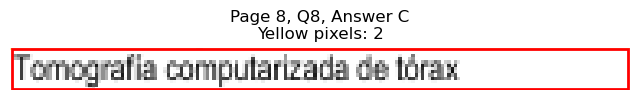

Page 8, Q8 - D: Detected box: x0=85.0, y0=639.3, x1=233.0, y1=651.4
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 798
Page 8, Q8, D: Yellow percentage: 0.0%


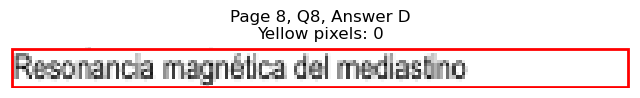

Page 8, Q8 - E: Detected box: x0=85.0, y0=651.4, x1=235.7, y1=663.5
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 763
Page 8, Q8, E: Yellow percentage: 0.0%


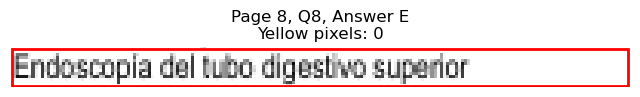


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=85.0, y0=699.5, x1=114.1, y1=711.7
Page 8, Q9, A: Yellow pixels: 929
Page 8, Q9, A: Total non-white pixels: 1053
Page 8, Q9, A: Yellow percentage: 88.2%


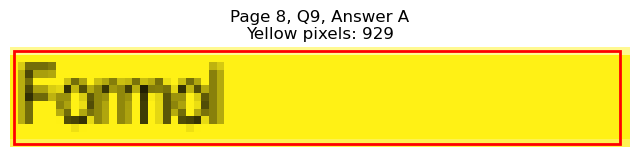

Page 8, Q9 - B: Detected box: x0=85.0, y0=711.7, x1=115.6, y1=723.8
Page 8, Q9, B: Yellow pixels: 82
Page 8, Q9, B: Total non-white pixels: 223
Page 8, Q9, B: Yellow percentage: 36.8%


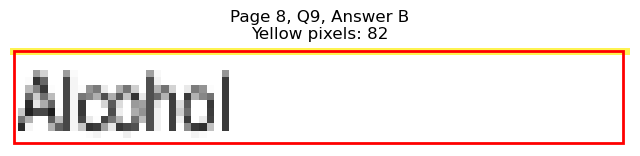

Page 8, Q9 - C: Detected box: x0=85.0, y0=723.7, x1=118.5, y1=735.8
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 168
Page 8, Q9, C: Yellow percentage: 0.0%


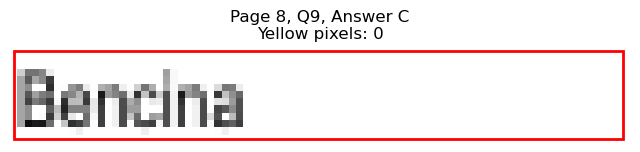

Page 8, Q9 - D: Detected box: x0=336.7, y0=699.5, x1=359.2, y1=711.7
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 98
Page 8, Q9, D: Yellow percentage: 0.0%


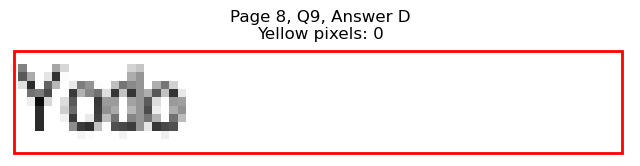

Page 8, Q9 - E: Detected box: x0=336.7, y0=711.7, x1=388.1, y1=723.8
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 268
Page 8, Q9, E: Yellow percentage: 0.0%


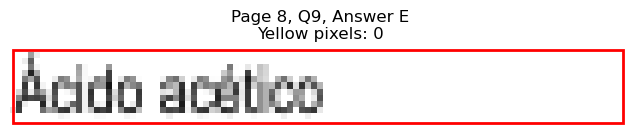


Page 8, Q9 - Selected Answer: A (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=132.9, y1=109.2
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 252
Page 9, Q1, A: Yellow percentage: 0.0%


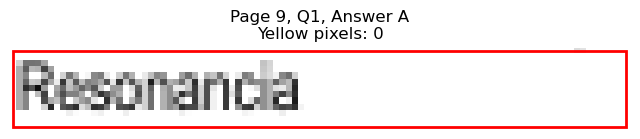

Page 9, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=124.2, y1=121.3
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 204
Page 9, Q1, B: Yellow percentage: 0.0%


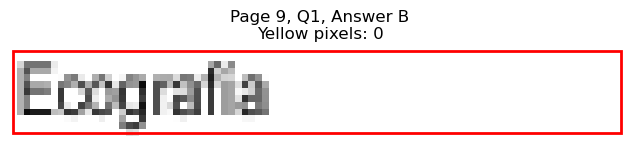

Page 9, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=140.1, y1=133.3
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 283
Page 9, Q1, C: Yellow percentage: 0.0%


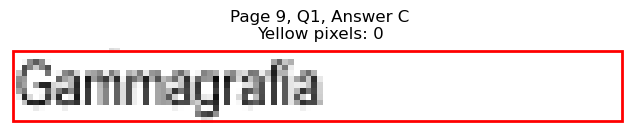

Page 9, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=390.3, y1=109.2
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 266
Page 9, Q1, D: Yellow percentage: 0.0%


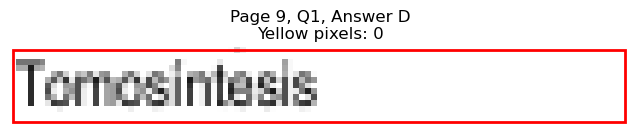

Page 9, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=383.1, y1=121.3
Page 9, Q1, E: Yellow pixels: 990
Page 9, Q1, E: Total non-white pixels: 1274
Page 9, Q1, E: Yellow percentage: 77.7%


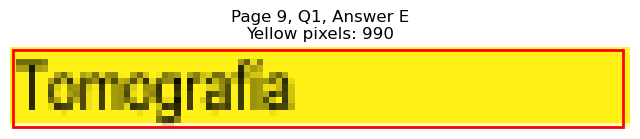


Page 9, Q1 - Selected Answer: E (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=157.7, y1=169.4
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 353
Page 9, Q2, A: Yellow percentage: 0.0%


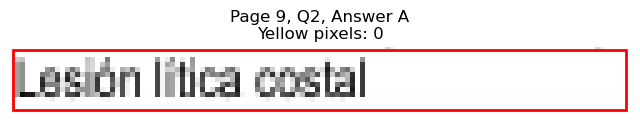

Page 9, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=179.3, y1=181.5
Page 9, Q2, B: Yellow pixels: 146
Page 9, Q2, B: Total non-white pixels: 606
Page 9, Q2, B: Yellow percentage: 24.1%


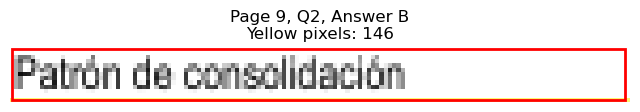

Page 9, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=275.2, y1=193.5
Page 9, Q2, C: Yellow pixels: 1741
Page 9, Q2, C: Total non-white pixels: 2483
Page 9, Q2, C: Yellow percentage: 70.1%


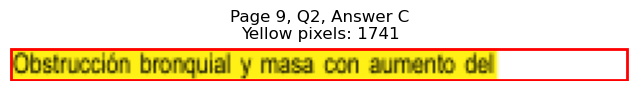

Page 9, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=432.0, y1=169.4
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 461
Page 9, Q2, D: Yellow percentage: 0.0%


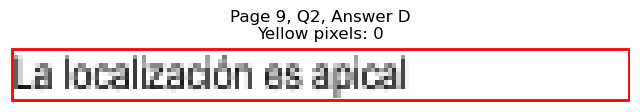

Page 9, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=452.5, y1=181.5
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 583
Page 9, Q2, E: Yellow percentage: 0.0%


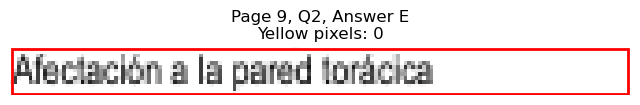


Page 9, Q2 - Selected Answer: C (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=85.0, y0=229.7, x1=122.3, y1=241.8
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 189
Page 9, Q3, A: Yellow percentage: 0.0%


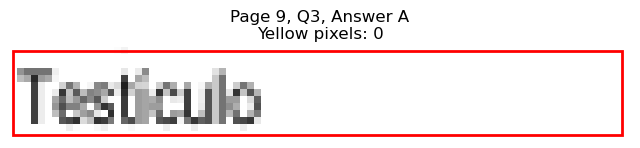

Page 9, Q3 - B: Detected box: x0=85.0, y0=241.7, x1=127.6, y1=253.8
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 221
Page 9, Q3, B: Yellow percentage: 0.0%


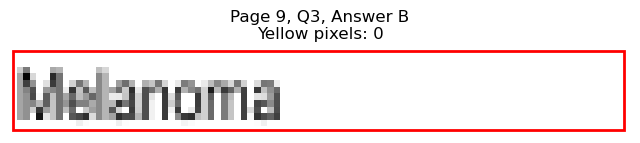

Page 9, Q3 - C: Detected box: x0=85.0, y0=253.7, x1=116.5, y1=265.8
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 137
Page 9, Q3, C: Yellow percentage: 0.0%


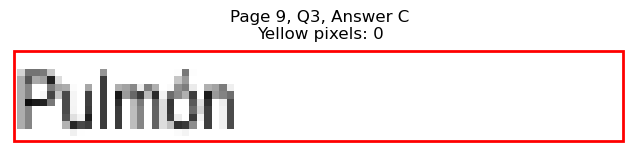

Page 9, Q3 - D: Detected box: x0=336.7, y0=229.7, x1=361.5, y1=241.8
Page 9, Q3, D: Yellow pixels: 826
Page 9, Q3, D: Total non-white pixels: 988
Page 9, Q3, D: Yellow percentage: 83.6%


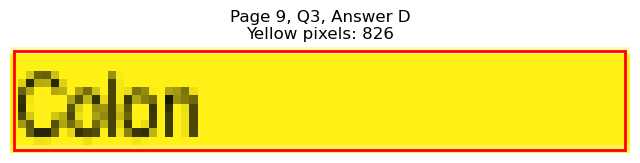

Page 9, Q3 - E: Detected box: x0=336.7, y0=241.7, x1=371.1, y1=253.8
Page 9, Q3, E: Yellow pixels: 86
Page 9, Q3, E: Total non-white pixels: 262
Page 9, Q3, E: Yellow percentage: 32.8%


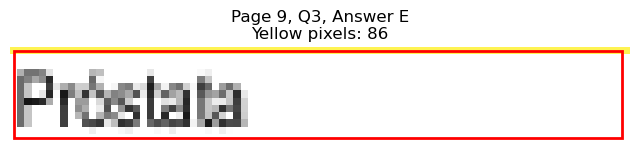


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=85.0, y0=289.9, x1=134.3, y1=302.0
Page 9, Q4, A: Yellow pixels: 990
Page 9, Q4, A: Total non-white pixels: 1313
Page 9, Q4, A: Yellow percentage: 75.4%


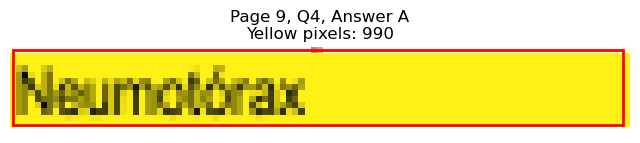

Page 9, Q4 - B: Detected box: x0=85.0, y0=301.9, x1=132.4, y1=314.0
Page 9, Q4, B: Yellow pixels: 99
Page 9, Q4, B: Total non-white pixels: 346
Page 9, Q4, B: Yellow percentage: 28.6%


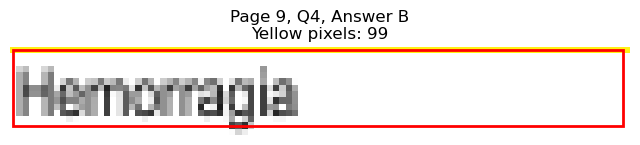

Page 9, Q4 - C: Detected box: x0=85.0, y0=313.9, x1=154.3, y1=326.0
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 353
Page 9, Q4, C: Yellow percentage: 0.0%


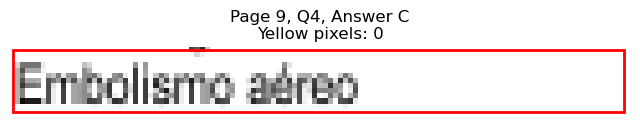

Page 9, Q4 - D: Detected box: x0=336.7, y0=289.9, x1=421.9, y1=302.0
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 434
Page 9, Q4, D: Yellow percentage: 0.0%


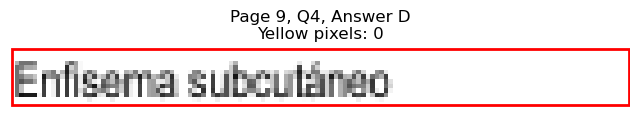

Page 9, Q4 - E: Detected box: x0=336.7, y0=301.9, x1=359.6, y1=314.0
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 106
Page 9, Q4, E: Yellow percentage: 0.0%


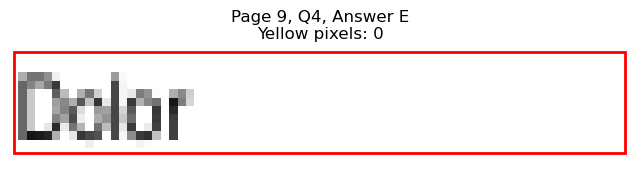


Page 9, Q4 - Selected Answer: A (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=85.0, y0=350.2, x1=312.4, y1=362.3
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 1107
Page 9, Q5, A: Yellow percentage: 0.0%


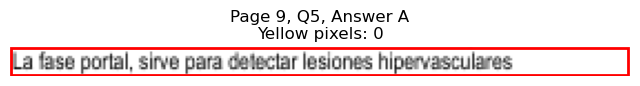

Page 9, Q5 - B: Detected box: x0=85.0, y0=362.2, x1=321.4, y1=374.3
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 1151
Page 9, Q5, B: Yellow percentage: 0.0%


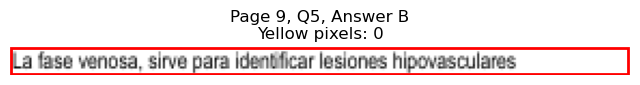

Page 9, Q5 - C: Detected box: x0=85.0, y0=374.2, x1=327.2, y1=386.3
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 1199
Page 9, Q5, C: Yellow percentage: 0.0%


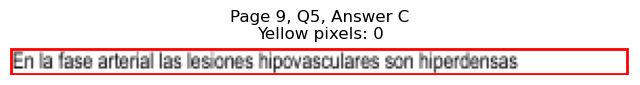

Page 9, Q5 - D: Detected box: x0=85.0, y0=386.3, x1=317.2, y1=398.4
Page 9, Q5, D: Yellow pixels: 2459
Page 9, Q5, D: Total non-white pixels: 3692
Page 9, Q5, D: Yellow percentage: 66.6%


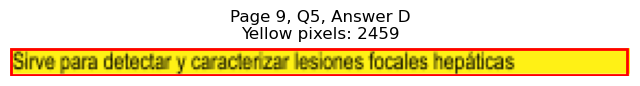

Page 9, Q5 - E: Detected box: x0=85.0, y0=398.3, x1=307.1, y1=410.4
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 1409
Page 9, Q5, E: Yellow percentage: 0.0%


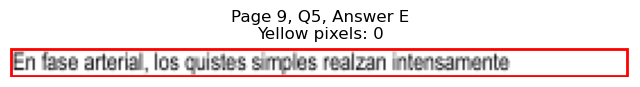


Page 9, Q5 - Selected Answer: D (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=138.1, y1=446.5
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 270
Page 9, Q6, A: Yellow percentage: 0.0%


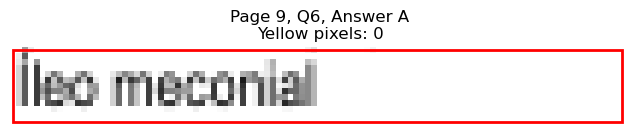

Page 9, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=206.6, y1=458.7
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 642
Page 9, Q6, B: Yellow percentage: 0.0%


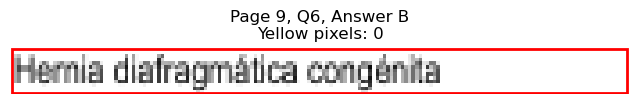

Page 9, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=174.5, y1=470.7
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 431
Page 9, Q6, C: Yellow percentage: 0.0%


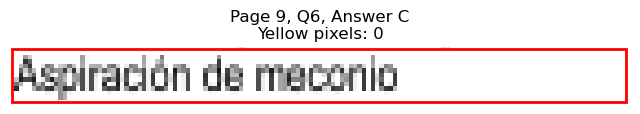

Page 9, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=426.7, y1=446.5
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 456
Page 9, Q6, D: Yellow percentage: 0.0%


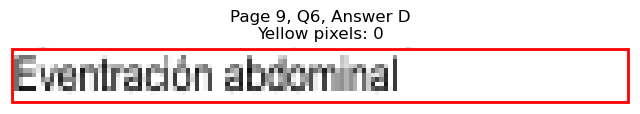

Page 9, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=435.3, y1=458.7
Page 9, Q6, E: Yellow pixels: 1522
Page 9, Q6, E: Total non-white pixels: 1950
Page 9, Q6, E: Yellow percentage: 78.1%


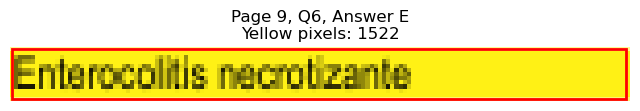


Page 9, Q6 - Selected Answer: E (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=183.1, y1=506.8
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 521
Page 9, Q7, A: Yellow percentage: 0.0%


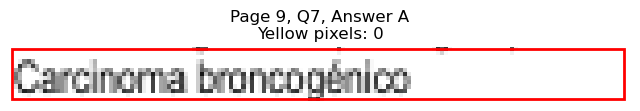

Page 9, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=129.5, y1=518.9
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 238
Page 9, Q7, B: Yellow percentage: 0.0%


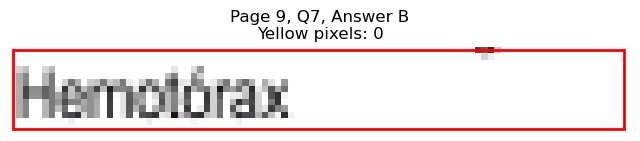

Page 9, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=109.3, y1=530.9
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 115
Page 9, Q7, C: Yellow percentage: 0.0%


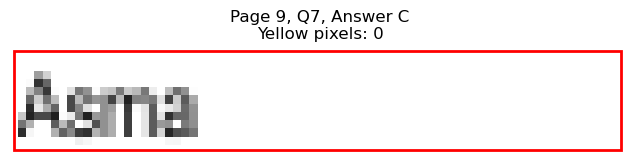

Page 9, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=397.0, y1=506.8
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 325
Page 9, Q7, D: Yellow percentage: 0.0%


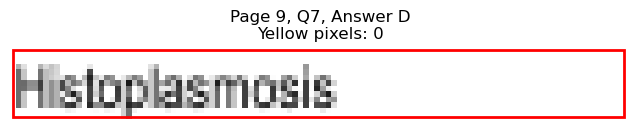

Page 9, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=387.9, y1=518.9
Page 9, Q7, E: Yellow pixels: 1017
Page 9, Q7, E: Total non-white pixels: 1326
Page 9, Q7, E: Yellow percentage: 76.7%


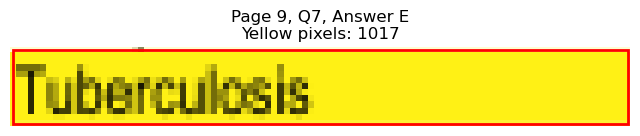


Page 9, Q7 - Selected Answer: E (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=150.0, y1=567.0
Page 9, Q8, A: Yellow pixels: 1147
Page 9, Q8, A: Total non-white pixels: 1638
Page 9, Q8, A: Yellow percentage: 70.0%


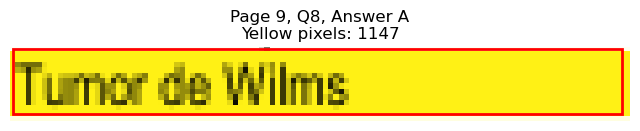

Page 9, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=143.4, y1=579.2
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 432
Page 9, Q8, B: Yellow percentage: 0.0%


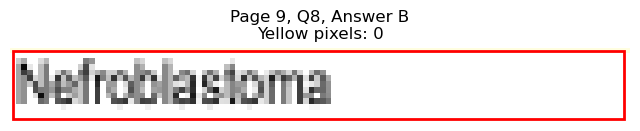

Page 9, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=152.4, y1=591.2
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 359
Page 9, Q8, C: Yellow percentage: 0.0%


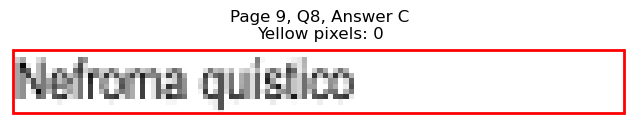

Page 9, Q8 - D: Detected box: x0=336.7, y0=554.9, x1=369.7, y1=567.0
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 140
Page 9, Q8, D: Yellow percentage: 0.0%


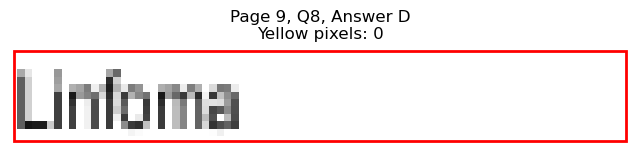

Page 9, Q8 - E: Detected box: x0=336.7, y0=567.1, x1=385.0, y1=579.2
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 237
Page 9, Q8, E: Yellow percentage: 0.0%


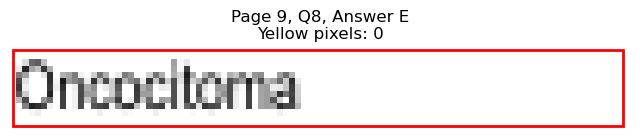


Page 9, Q8 - Selected Answer: A (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=85.0, y0=615.2, x1=276.5, y1=627.3
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 933
Page 9, Q9, A: Yellow percentage: 0.0%


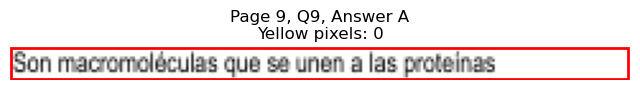

Page 9, Q9 - B: Detected box: x0=85.0, y0=627.3, x1=232.5, y1=639.4
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 767
Page 9, Q9, B: Yellow percentage: 0.0%


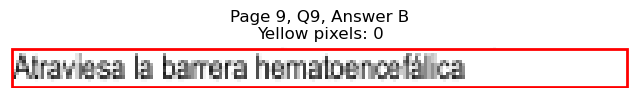

Page 9, Q9 - C: Detected box: x0=85.0, y0=639.3, x1=293.2, y1=651.4
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 1032
Page 9, Q9, C: Yellow percentage: 0.0%


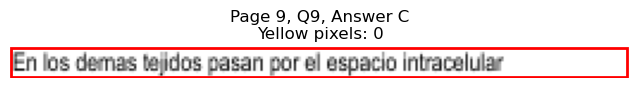

Page 9, Q9 - D: Detected box: x0=85.0, y0=651.4, x1=293.2, y1=663.5
Page 9, Q9, D: Yellow pixels: 2519
Page 9, Q9, D: Total non-white pixels: 3380
Page 9, Q9, D: Yellow percentage: 74.5%


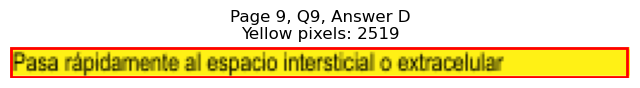

Page 9, Q9 - E: Detected box: x0=85.0, y0=663.4, x1=236.7, y1=675.5
Page 9, Q9, E: Yellow pixels: 203
Page 9, Q9, E: Total non-white pixels: 963
Page 9, Q9, E: Yellow percentage: 21.1%


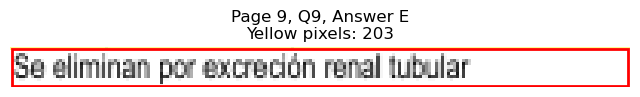


Page 9, Q9 - Selected Answer: D (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=85.0, y0=699.5, x1=252.5, y1=711.7
Page 9, Q10, A: Yellow pixels: 1750
Page 9, Q10, A: Total non-white pixels: 2483
Page 9, Q10, A: Yellow percentage: 70.5%


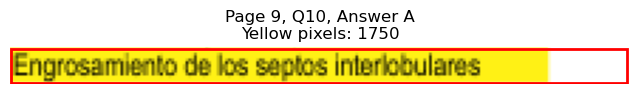

Page 9, Q10 - B: Detected box: x0=85.0, y0=711.7, x1=211.4, y1=723.8
Page 9, Q10, B: Yellow pixels: 178
Page 9, Q10, B: Total non-white pixels: 830
Page 9, Q10, B: Yellow percentage: 21.4%


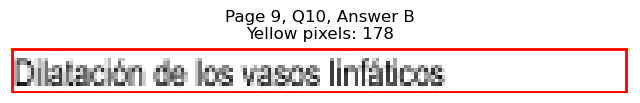

Page 9, Q10 - C: Detected box: x0=85.0, y0=723.7, x1=155.4, y1=735.8
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 376
Page 9, Q10, C: Yellow percentage: 0.0%


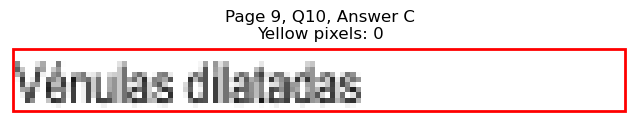

Page 9, Q10 - D: Detected box: x0=336.7, y0=699.5, x1=460.2, y1=711.7
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 649
Page 9, Q10, D: Yellow percentage: 0.0%


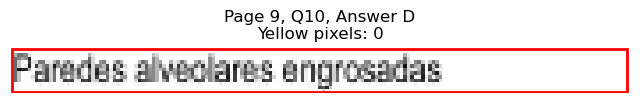

Page 9, Q10 - E: Detected box: x0=336.7, y0=711.7, x1=405.6, y1=723.8
Page 9, Q10, E: Yellow pixels: 0
Page 9, Q10, E: Total non-white pixels: 349
Page 9, Q10, E: Yellow percentage: 0.0%


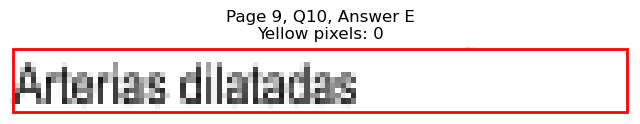


Page 9, Q10 - Selected Answer: A (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=417.2, y1=109.2
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 1603
Page 10, Q1, A: Yellow percentage: 0.0%


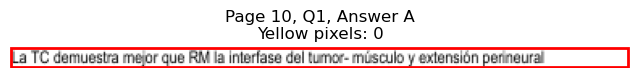

Page 10, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=348.8, y1=121.3
Page 10, Q1, B: Yellow pixels: 315
Page 10, Q1, B: Total non-white pixels: 1590
Page 10, Q1, B: Yellow percentage: 19.8%


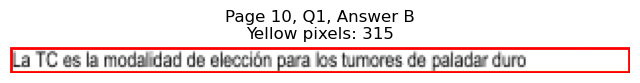

Page 10, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=419.6, y1=133.3
Page 10, Q1, C: Yellow pixels: 3318
Page 10, Q1, C: Total non-white pixels: 5018
Page 10, Q1, C: Yellow percentage: 66.1%


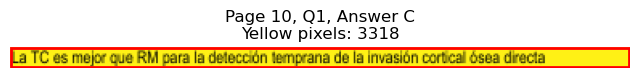

Page 10, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=482.7, y1=145.3
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 2471
Page 10, Q1, D: Yellow percentage: 0.0%


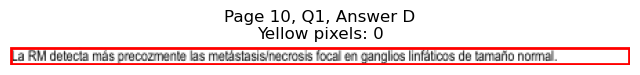

Page 10, Q1 - E: Detected box: x0=85.0, y0=145.3, x1=302.3, y1=157.4
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 1022
Page 10, Q1, E: Yellow percentage: 0.0%


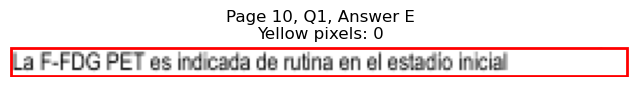


Page 10, Q1 - Selected Answer: C (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=380.8, y1=193.5
Page 10, Q2, A: Yellow pixels: 347
Page 10, Q2, A: Total non-white pixels: 1791
Page 10, Q2, A: Yellow percentage: 19.4%


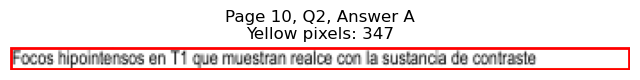

Page 10, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=358.3, y1=205.5
Page 10, Q2, B: Yellow pixels: 3175
Page 10, Q2, B: Total non-white pixels: 4225
Page 10, Q2, B: Yellow percentage: 75.1%


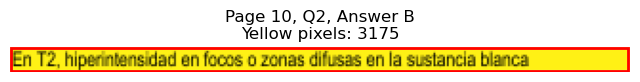

Page 10, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=243.4, y1=217.7
Page 10, Q2, C: Yellow pixels: 210
Page 10, Q2, C: Total non-white pixels: 956
Page 10, Q2, C: Yellow percentage: 22.0%


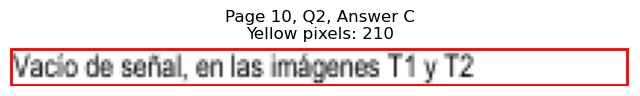

Page 10, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=293.7, y1=229.7
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 1049
Page 10, Q2, D: Yellow percentage: 0.0%


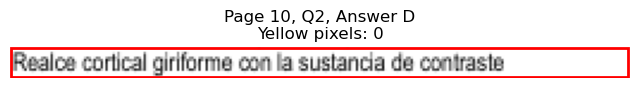

Page 10, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=273.2, y1=241.8
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 978
Page 10, Q2, E: Yellow percentage: 0.0%


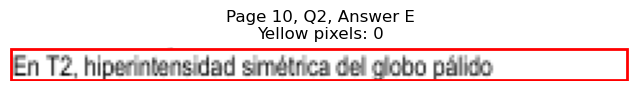


Page 10, Q2 - Selected Answer: B (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=85.0, y0=265.8, x1=141.5, y1=277.9
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 376
Page 10, Q3, A: Yellow percentage: 0.0%


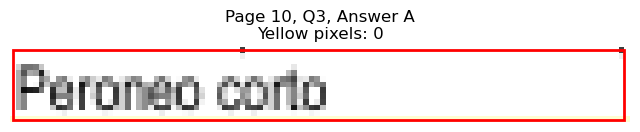

Page 10, Q3 - B: Detected box: x0=85.0, y0=277.8, x1=143.9, y1=289.9
Page 10, Q3, B: Yellow pixels: 1059
Page 10, Q3, B: Total non-white pixels: 1430
Page 10, Q3, B: Yellow percentage: 74.1%


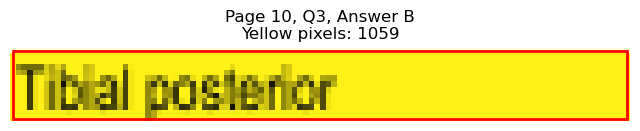

Page 10, Q3 - C: Detected box: x0=85.0, y0=289.9, x1=141.5, y1=302.0
Page 10, Q3, C: Yellow pixels: 106
Page 10, Q3, C: Total non-white pixels: 382
Page 10, Q3, C: Yellow percentage: 27.7%


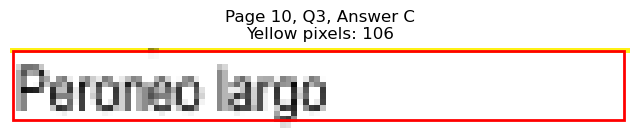

Page 10, Q3 - D: Detected box: x0=336.7, y0=265.8, x1=413.2, y1=277.9
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 384
Page 10, Q3, D: Yellow percentage: 0.0%


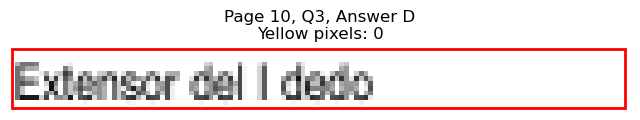

Page 10, Q3 - E: Detected box: x0=336.7, y0=277.8, x1=391.3, y1=289.9
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 259
Page 10, Q3, E: Yellow percentage: 0.0%


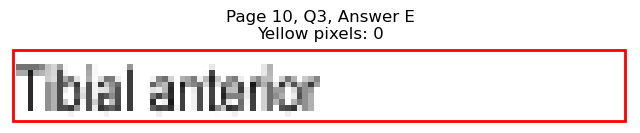


Page 10, Q3 - Selected Answer: B (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=85.0, y0=326.1, x1=268.9, y1=338.2
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 910
Page 10, Q4, A: Yellow percentage: 0.0%


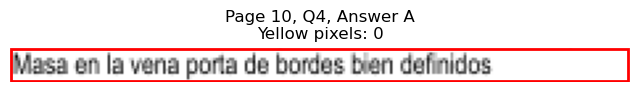

Page 10, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=254.9, y1=350.2
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 839
Page 10, Q4, B: Yellow percentage: 0.0%


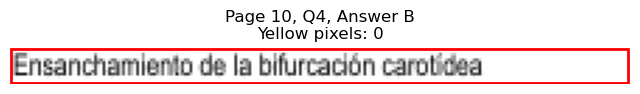

Page 10, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=237.7, y1=362.3
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 825
Page 10, Q4, C: Yellow percentage: 0.0%


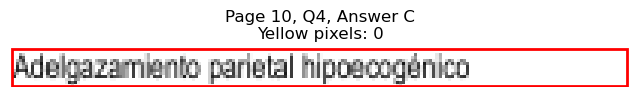

Page 10, Q4 - D: Detected box: x0=336.7, y0=326.1, x1=489.8, y1=338.2
Page 10, Q4, D: Yellow pixels: 190
Page 10, Q4, D: Total non-white pixels: 960
Page 10, Q4, D: Yellow percentage: 19.8%


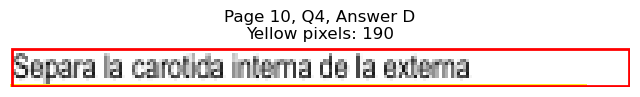

Page 10, Q4 - E: Detected box: x0=336.7, y0=338.1, x1=482.6, y1=350.2
Page 10, Q4, E: Yellow pixels: 1709
Page 10, Q4, E: Total non-white pixels: 2470
Page 10, Q4, E: Yellow percentage: 69.2%


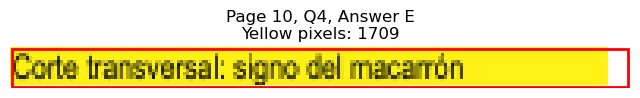


Page 10, Q4 - Selected Answer: E (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=146.3, y1=398.4
Page 10, Q5, A: Yellow pixels: 1098
Page 10, Q5, A: Total non-white pixels: 1469
Page 10, Q5, A: Yellow percentage: 74.7%


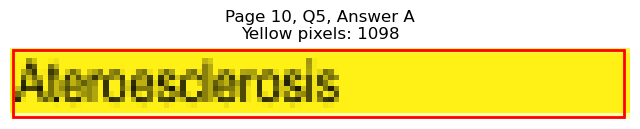

Page 10, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=140.5, y1=410.4
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 394
Page 10, Q5, B: Yellow percentage: 0.0%


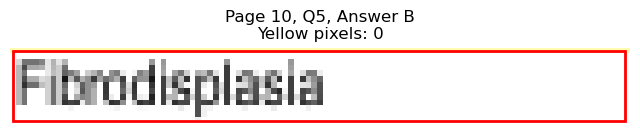

Page 10, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=157.2, y1=422.5
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 385
Page 10, Q5, C: Yellow percentage: 0.0%


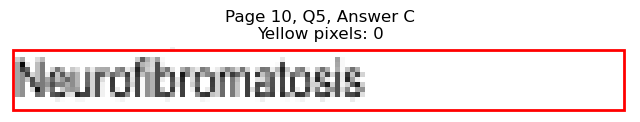

Page 10, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=432.9, y1=398.4
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 472
Page 10, Q5, D: Yellow percentage: 0.0%


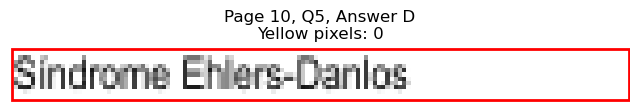

Page 10, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=412.3, y1=410.4
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 405
Page 10, Q5, E: Yellow percentage: 0.0%


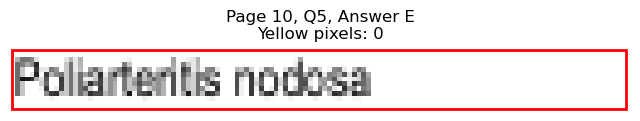


Page 10, Q5 - Selected Answer: A (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=85.0, y0=446.6, x1=115.6, y1=458.7
Page 10, Q6, A: Yellow pixels: 969
Page 10, Q6, A: Total non-white pixels: 1066
Page 10, Q6, A: Yellow percentage: 90.9%


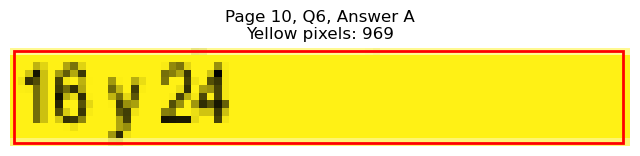

Page 10, Q6 - B: Detected box: x0=85.0, y0=458.6, x1=115.6, y1=470.7
Page 10, Q6, B: Yellow pixels: 82
Page 10, Q6, B: Total non-white pixels: 218
Page 10, Q6, B: Yellow percentage: 37.6%


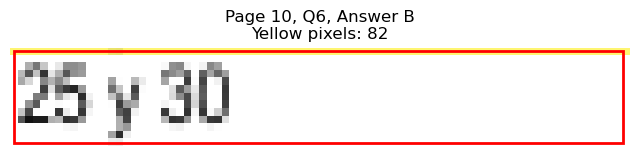

Page 10, Q6 - C: Detected box: x0=85.0, y0=470.7, x1=115.6, y1=482.8
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 128
Page 10, Q6, C: Yellow percentage: 0.0%


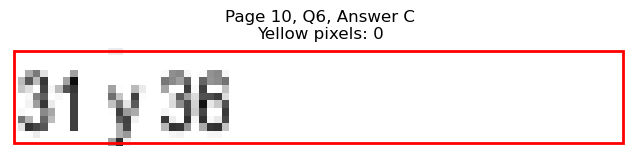

Page 10, Q6 - D: Detected box: x0=336.7, y0=446.6, x1=367.3, y1=458.7
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 129
Page 10, Q6, D: Yellow percentage: 0.0%


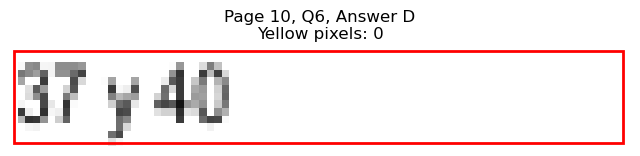

Page 10, Q6 - E: Detected box: x0=336.7, y0=458.6, x1=362.6, y1=470.7
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 103
Page 10, Q6, E: Yellow percentage: 0.0%


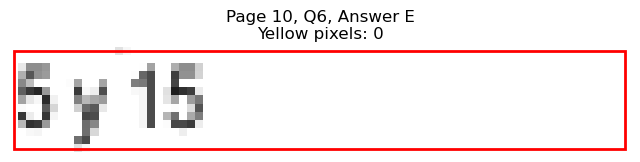


Page 10, Q6 - Selected Answer: A (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=85.0, y0=506.8, x1=318.2, y1=518.9
Page 10, Q7, A: Yellow pixels: 2468
Page 10, Q7, A: Total non-white pixels: 3705
Page 10, Q7, A: Yellow percentage: 66.6%


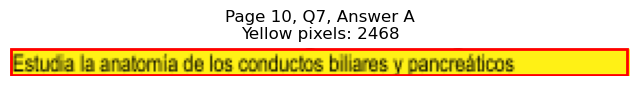

Page 10, Q7 - B: Detected box: x0=85.0, y0=518.8, x1=262.6, y1=530.9
Page 10, Q7, B: Yellow pixels: 224
Page 10, Q7, B: Total non-white pixels: 1144
Page 10, Q7, B: Yellow percentage: 19.6%


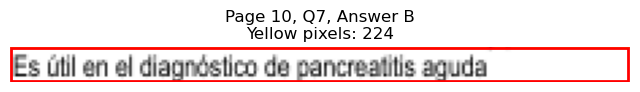

Page 10, Q7 - C: Detected box: x0=85.0, y0=530.9, x1=249.7, y1=543.0
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 866
Page 10, Q7, C: Yellow percentage: 0.0%


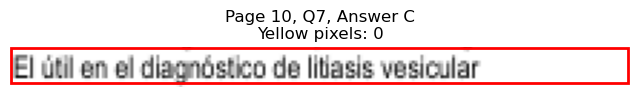

Page 10, Q7 - D: Detected box: x0=85.0, y0=542.9, x1=294.2, y1=555.0
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 1050
Page 10, Q7, D: Yellow percentage: 0.0%


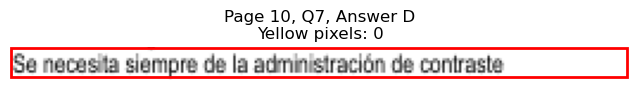

Page 10, Q7 - E: Detected box: x0=85.0, y0=554.9, x1=194.7, y1=567.0
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 537
Page 10, Q7, E: Yellow percentage: 0.0%


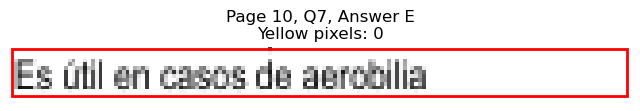


Page 10, Q7 - Selected Answer: A (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=85.0, y0=591.2, x1=131.4, y1=603.3
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 250
Page 10, Q8, A: Yellow percentage: 0.0%


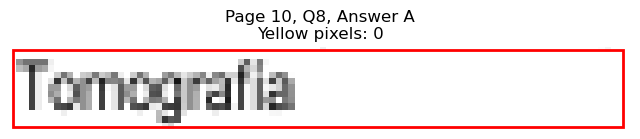

Page 10, Q8 - B: Detected box: x0=85.0, y0=603.2, x1=133.3, y1=615.3
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 277
Page 10, Q8, B: Yellow percentage: 0.0%


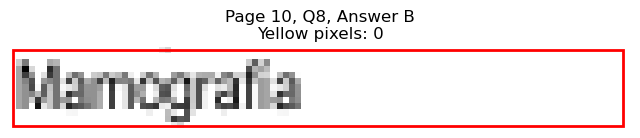

Page 10, Q8 - C: Detected box: x0=85.0, y0=615.2, x1=124.2, y1=627.3
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 206
Page 10, Q8, C: Yellow percentage: 0.0%


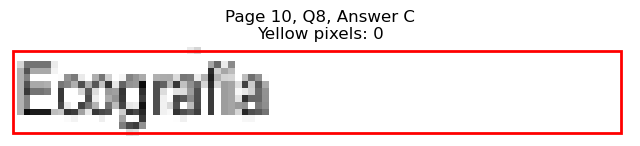

Page 10, Q8 - D: Detected box: x0=336.7, y0=591.2, x1=384.6, y1=603.3
Page 10, Q8, D: Yellow pixels: 997
Page 10, Q8, D: Total non-white pixels: 1287
Page 10, Q8, D: Yellow percentage: 77.5%


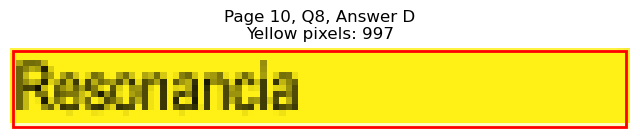

Page 10, Q8 - E: Detected box: x0=336.7, y0=603.2, x1=390.3, y1=615.3
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 369
Page 10, Q8, E: Yellow percentage: 0.0%


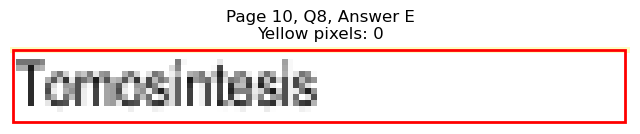


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=85.0, y0=663.4, x1=135.9, y1=675.5
Page 10, Q9, A: Yellow pixels: 1099
Page 10, Q9, A: Total non-white pixels: 1326
Page 10, Q9, A: Yellow percentage: 82.9%


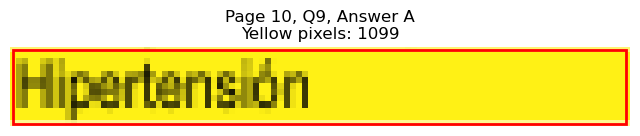

Page 10, Q9 - B: Detected box: x0=85.0, y0=675.4, x1=127.7, y1=687.5
Page 10, Q9, B: Yellow pixels: 94
Page 10, Q9, B: Total non-white pixels: 311
Page 10, Q9, B: Yellow percentage: 30.2%


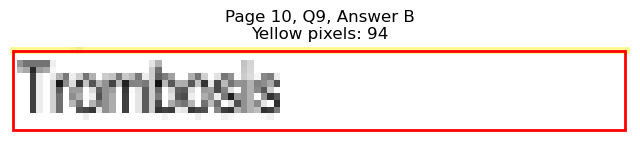

Page 10, Q9 - C: Detected box: x0=85.0, y0=687.5, x1=149.7, y1=699.7
Page 10, Q9, C: Yellow pixels: 0
Page 10, Q9, C: Total non-white pixels: 333
Page 10, Q9, C: Yellow percentage: 0.0%


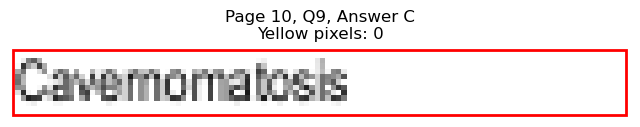

Page 10, Q9 - D: Detected box: x0=336.7, y0=663.4, x1=364.0, y1=675.5
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 117
Page 10, Q9, D: Yellow percentage: 0.0%


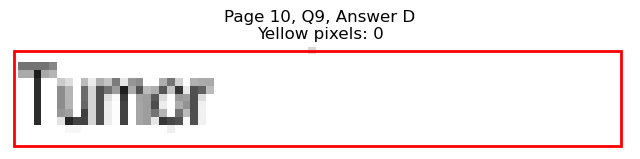

Page 10, Q9 - E: Detected box: x0=336.7, y0=675.4, x1=395.6, y1=687.5
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 293
Page 10, Q9, E: Yellow percentage: 0.0%


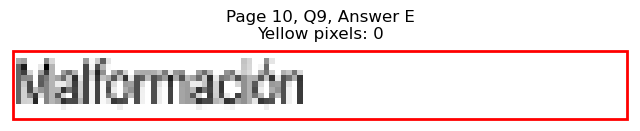


Page 10, Q9 - Selected Answer: A (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Cuál es el hallazgo tomográfico mas indicativ...
1,En ecografía. ¿Qué artefacto se forma cuando e...
2,En un nódulo benigno de mama. ¿Cuál es el patr...
3,"Lactante en el primer día de vida, presenta vó..."
4,¿Qué tipo de atelectasia se produce cuando la ...
...,...
95,¿Cuál es la causa más frecuente de aneurisma e...
96,En la ecografía prenatal. ¿En qué semana de ge...
97,¿Cuál es una característica de la colangioreso...
98,Paciente acude por alta sospecha de ruptura de...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Seudoaneurisma,Dilatación del conducto pancreático principal,Seudoquistes,Atrofia del parénquima pancreático,Calcificaciones pancreáticas intraductales
1,Velocidad de propagación,Lóbulo lateral,Espejo,Grosor de corte,Reverberación
2,Lavado,Periferia se realza primero,Rápido e inicial,Gradual,Meseta tardía
3,Obstrucción ileal,Estenosis del píloro,Malrotación intestinal,Duplicación intestinal,Atresia duodenal
4,Cicatrización,Adhesiva,Compresión,Reabsorción,Pasiva
...,...,...,...,...,...
95,Ateroesclerosis,Fibrodisplasia,Neurofibromatosis,Síndrome Ehlers-Danlos,Poliarteritis nodosa
96,16 y 24,25 y 30,31 y 36,37 y 40,5 y 15
97,Estudia la anatomía de los conductos biliares ...,Es útil en el diagnóstico de pancreatitis aguda,El útil en el diagnóstico de litiasis vesicular,Se necesita siempre de la administración de co...,Es útil en casos de aerobilia
98,Tomografía,Mamografía,Ecografía,Resonancia,Tomosíntesis


In [9]:
correct_answers_df

,correct_answer
0,E
1,C
2,D
3,E
4,B
...,...
95,A
96,A
97,A
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,¿Cuál es el hallazgo tomográfico mas indicativ...,Seudoaneurisma,Dilatación del conducto pancreático principal,Seudoquistes,Atrofia del parénquima pancreático,Calcificaciones pancreáticas intraductales,E
1,En ecografía. ¿Qué artefacto se forma cuando e...,Velocidad de propagación,Lóbulo lateral,Espejo,Grosor de corte,Reverberación,C
2,En un nódulo benigno de mama. ¿Cuál es el patr...,Lavado,Periferia se realza primero,Rápido e inicial,Gradual,Meseta tardía,D
3,"Lactante en el primer día de vida, presenta vó...",Obstrucción ileal,Estenosis del píloro,Malrotación intestinal,Duplicación intestinal,Atresia duodenal,E
4,¿Qué tipo de atelectasia se produce cuando la ...,Cicatrización,Adhesiva,Compresión,Reabsorción,Pasiva,B
...,...,...,...,...,...,...,...
95,¿Cuál es la causa más frecuente de aneurisma e...,Ateroesclerosis,Fibrodisplasia,Neurofibromatosis,Síndrome Ehlers-Danlos,Poliarteritis nodosa,A
96,En la ecografía prenatal. ¿En qué semana de ge...,16 y 24,25 y 30,31 y 36,37 y 40,5 y 15,A
97,¿Cuál es una característica de la colangioreso...,Estudia la anatomía de los conductos biliares ...,Es útil en el diagnóstico de pancreatitis aguda,El útil en el diagnóstico de litiasis vesicular,Se necesita siempre de la administración de co...,Es útil en casos de aerobilia,A
98,Paciente acude por alta sospecha de ruptura de...,Tomografía,Mamografía,Ecografía,Resonancia,Tomosíntesis,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/RADIOLOGÍA.csv
